# Gaze Data Density Comparison

This notebook compares gaze data density between **TextualAttack** and **MultiModalAttack** conditions and produces a publication-ready figure.

In [5]:
import os
import glob
import re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import gridspec


# ===============================
# -------- CONFIGURATION --------
# ===============================

BASE_DIR = Path(r"C:\Users\nahmed25\PhD\ISMAR26_Engagement")
TEXT_GAZE_PATH = BASE_DIR / "TextualAttack" / "gaze"
MULTI_GAZE_PATH = BASE_DIR / "MultiModalAttack" / "gaze"


# ===============================
# ---- PARTICIPANT EXTRACTOR ----
# ===============================

def extract_participant_id(filename: str) -> str:
    stem = Path(filename).stem
    return stem.split("_")[0]  # safer than regex


def get_file_stats(path: Path, condition_label: str) -> pd.DataFrame:
    data_stats = []
    files = sorted(glob.glob(str(path / "*.csv")))

    print(f"Found {len(files)} files in {condition_label}: {path}")

    for f in files:
        try:
            df = pd.read_csv(f)
            pid = extract_participant_id(os.path.basename(f))

            data_stats.append({
                "Participant ID": pid,
                "Data Points": len(df),
                "Condition": condition_label,
                "Duration (s)": len(df) / 60.0  # assuming 60Hz
            })

        except Exception as e:
            print(f"Error reading {f}: {e}")

    return pd.DataFrame(data_stats)


# ===============================
# -------- LOAD DATA ------------
# ===============================

df_text = get_file_stats(TEXT_GAZE_PATH, "Text-Only")
df_multi = get_file_stats(MULTI_GAZE_PATH, "Multi-Modal")

full_df = pd.concat([df_text, df_multi], ignore_index=True)

if full_df.empty:
    raise ValueError("No gaze CSV files were loaded. Check directory paths.")

# numeric sorting
full_df["Participant ID"] = full_df["Participant ID"].astype(int)
full_df = full_df.sort_values(by=["Participant ID", "Condition"]).reset_index(drop=True)


# ===============================
# -------- STATISTICS -----------
# ===============================

stats_summary = full_df.groupby("Condition")["Data Points"].agg(
    ["mean", "std", "count", "sum"]
)

print("\n--- STATISTICS FOR PAPER ---")
print(stats_summary)
print("\nTotal Data Points:", int(full_df["Data Points"].sum()))


# ===============================
# --------- FIGURE --------------
# ===============================

if __name__ == '__main__':

    # ---- Style (match your example exactly) ----
    plt.rcParams['font.family'] = 'sans-serif'
    plt.rcParams['font.sans-serif'] = ['Arial', 'DejaVu Sans']
    plt.rcParams['font.size'] = 28
    plt.rcParams['axes.spines.right'] = False
    plt.rcParams['axes.spines.top'] = False
    plt.rcParams['axes.linewidth'] = 3

    fig = plt.figure(figsize=(42, 12))
    gs = gridspec.GridSpec(1, 3)

    conditions = ["Text-Only", "Multi-Modal"]
    colors = ['#0F4D92', '#F1ACA4']

    # -----------------------------
    # Panel 1 — Per Participant
    # -----------------------------
    ax1 = fig.add_subplot(gs[0])

    participants = sorted(full_df["Participant ID"].unique())

    width = 0.35
    x = np.arange(len(participants))

    for idx, cond in enumerate(conditions):
        values = []
        for pid in participants:
            row = full_df[(full_df["Participant ID"] == pid) &
                          (full_df["Condition"] == cond)]
            if not row.empty:
                values.append(row["Data Points"].values[0])
            else:
                values.append(0)

        bars = ax1.bar(
            x + idx * width,
            values,
            width=width,
            color=colors[idx],
            label=cond
        )

    ax1.set_ylabel("Total Gaze Points", fontsize=48)
    ax1.set_xticks(x + width / 2)
    ax1.set_xticklabels(participants, rotation=45)
    ax1.tick_params(axis='both', labelsize=28)
    ax1.legend(fontsize=32, frameon=False)

    # -----------------------------
    # Panel 2 — Mean Comparison
    # -----------------------------
    ax2 = fig.add_subplot(gs[1])

    means = stats_summary["mean"].values
    stds = stats_summary["std"].values

    bars = ax2.bar(
        np.arange(len(conditions)),
        means,
        yerr=stds,
        capsize=12,
        color=colors
    )

    for i, value in enumerate(means):
        ax2.text(
            i,
            value + stds[i],
            f'{value:,.0f}',
            ha='center',
            va='bottom',
            fontsize=36
        )

    ax2.set_ylabel("Mean Gaze Points (± SD)", fontsize=48)
    ax2.set_xticks(np.arange(len(conditions)))
    ax2.set_xticklabels(conditions)
    ax2.tick_params(axis='both', labelsize=28)

    # -----------------------------
    # Panel 3 — Total Data Volume
    # -----------------------------
    ax3 = fig.add_subplot(gs[2])

    totals = stats_summary["sum"].values

    bars = ax3.bar(
        np.arange(len(conditions)),
        totals,
        color=colors
    )

    for i, value in enumerate(totals):
        ax3.text(
            i,
            value,
            f'{int(value):,}',
            ha='center',
            va='bottom',
            fontsize=36
        )

    ax3.set_ylabel("Total Gaze Data Points", fontsize=48)
    ax3.set_xticks(np.arange(len(conditions)))
    ax3.set_xticklabels(conditions)
    ax3.tick_params(axis='both', labelsize=28)

    fig.tight_layout(pad=2)

    os.makedirs('./figures/', exist_ok=True)
    fig.savefig('./figures/engagement_gaze_density.png', dpi=300)
    plt.close(fig)

    # print("\nFigure saved to ./figures/engagement_gaze_density.png")
    os.makedirs('./figures/', exist_ok=True)

    pdf_path = './figures/engagement_gaze_density.pdf'
    fig.savefig(
        pdf_path,
        format='pdf',
        bbox_inches='tight'
    )
    
    print(f"\nFigure saved to {pdf_path}")

Found 15 files in Text-Only: C:\Users\nahmed25\PhD\ISMAR26_Engagement\TextualAttack\gaze
Found 14 files in Multi-Modal: C:\Users\nahmed25\PhD\ISMAR26_Engagement\MultiModalAttack\gaze

--- STATISTICS FOR PAPER ---
                     mean          std  count     sum
Condition                                            
Multi-Modal  17303.857143  5712.003526     14  242254
Text-Only    22828.933333  8469.111140     15  342434

Total Data Points: 584688

Figure saved to ./figures/engagement_gaze_density.pdf


In [6]:
print("\n--- EXACT VALUES ---")
print("Text-Only:")
print("  Total:", int(stats_summary.loc["Text-Only", "sum"]))
print("  Mean :", stats_summary.loc["Text-Only", "mean"])
print("  Std  :", stats_summary.loc["Text-Only", "std"])

print("\nMulti-Modal:")
print("  Total:", int(stats_summary.loc["Multi-Modal", "sum"]))
print("  Mean :", stats_summary.loc["Multi-Modal", "mean"])
print("  Std  :", stats_summary.loc["Multi-Modal", "std"])



--- EXACT VALUES ---
Text-Only:
  Total: 342434
  Mean : 22828.933333333334
  Std  : 8469.111139620149

Multi-Modal:
  Total: 242254
  Mean : 17303.85714285714
  Std  : 5712.003526409475


In [14]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
import numpy as np
from scipy import stats

# =====================================================
# ================= CONFIGURATION =====================
# =====================================================

BASE_PATH = r"C:\Users\nahmed25\PhD\ISMAR26_Engagement"

TEXT_SURVEY_PATH = os.path.join(
    BASE_PATH, "TextualAttack", "Surveys and Pre-Post Measures"
)

MULTI_SURVEY_PATH = os.path.join(
    BASE_PATH, "MultiModalAttack", "Surveys and Pre-Post Measures"
)

FILENAME = "tia.csv"

# =====================================================
# ================= LOAD DATA =========================
# =====================================================

def load_surveys():
    text_file = os.path.join(TEXT_SURVEY_PATH, FILENAME)
    multi_file = os.path.join(MULTI_SURVEY_PATH, FILENAME)

    df_text = pd.read_csv(text_file)
    df_multi = pd.read_csv(multi_file)

    print(f"Loaded Text-Only rows: {len(df_text)}")
    print(f"Loaded Multi-Modal rows: {len(df_multi)}")

    df = pd.concat([df_text, df_multi], ignore_index=True)

    # -----------------------------
    # Remove incomplete participant
    # -----------------------------
    df = df[df['participant_id'] != 1003]

    print(f"Rows after removing participant 1003: {len(df)}")

    # Normalize intensity labels
    intensity_map = {
        1: 'Low',
        2: 'Medium',
        3: 'High',
        'Low': 'Low',
        'Medium': 'Medium',
        'High': 'High'
    }

    df['Intensity_Label'] = df['intensity'].map(intensity_map)
    df = df[df['Intensity_Label'].notna()]

    return df

df_tia = load_surveys()

# =====================================================
# ============ COMPOSITE TRUST SCORE ==================
# =====================================================

metadata_cols = [
    'participant_id','study_name','study_name_code','device','device_code',
    'event_type','event_type_code','system_change','system_change_code',
    'intensity','intensity_code','Intensity_Label','Timestamp'
]

measure_cols = [
    c for c in df_tia.columns
    if c not in metadata_cols and pd.api.types.is_numeric_dtype(df_tia[c])
]

df_tia['Total_Trust_Score'] = df_tia[measure_cols].sum(axis=1)

# =====================================================
# ================= SUMMARY STATS =====================
# =====================================================

summary = df_tia.groupby('Intensity_Label')['Total_Trust_Score'].agg(
    ['mean', 'std', 'count']
)

summary['se'] = summary['std'] / np.sqrt(summary['count'])

print("\n===== TRUST SUMMARY BY INTENSITY =====")
print(summary.round(3))

# =====================================================
# ===================== ANOVA =========================
# =====================================================

low = df_tia[df_tia['Intensity_Label']=='Low']['Total_Trust_Score']
med = df_tia[df_tia['Intensity_Label']=='Medium']['Total_Trust_Score']
high = df_tia[df_tia['Intensity_Label']=='High']['Total_Trust_Score']

F_stat, p_val = stats.f_oneway(low, med, high)

print("\n===== ANOVA RESULTS =====")
print(f"F = {F_stat:.4f}")
print(f"p = {p_val:.6f}")

# Effect size (Eta squared)
all_vals = df_tia['Total_Trust_Score']
grand_mean = np.mean(all_vals)

ss_between = (
    len(low)*(np.mean(low)-grand_mean)**2 +
    len(med)*(np.mean(med)-grand_mean)**2 +
    len(high)*(np.mean(high)-grand_mean)**2
)

ss_total = np.sum((all_vals - grand_mean)**2)

eta_sq = ss_between / ss_total

print(f"Eta squared (η²) = {eta_sq:.4f}")

# =====================================================
# ===================== PLOT ==========================
# =====================================================

plt.rcParams['pdf.fonttype'] = 42
plt.rcParams['ps.fonttype'] = 42

sns.set_style("white")

plt.figure(figsize=(6.5,4.5))

ax = sns.barplot(
    data=df_tia,
    x='Intensity_Label',
    y='Total_Trust_Score',
    order=['Low','Medium','High'],
    color='gray',
    errorbar='se',
    capsize=0.15
)

plt.xlabel("Attack Intensity")
plt.ylabel("Total Trust Score (Mean ± SE)")
plt.title("Dose–Response Effect of Attack Intensity on Trust")

plt.tight_layout()

os.makedirs("figures", exist_ok=True)
plt.savefig("figures/Figure2_Trust_Intensity.pdf", bbox_inches='tight')
plt.close()

print("\nFigure saved as figures/Figure2_Trust_Intensity.pdf")


Loaded Text-Only rows: 15
Loaded Multi-Modal rows: 15
Rows after removing participant 1003: 29

===== TRUST SUMMARY BY INTENSITY =====
                      mean    std  count     se
Intensity_Label                                
High                  66.9  7.310     10  2.312
Low              70.111111  8.652      9  2.884
Medium                61.2  8.337     10  2.636

===== ANOVA RESULTS =====
F = 2.9765
p = 0.068547
Eta squared (η²) = 0.1863

Figure saved as figures/Figure2_Trust_Intensity.pdf


In [21]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
import numpy as np
from scipy import stats

BASE_PATH = r"C:\Users\nahmed25\PhD\ISMAR26_Engagement"

TEXT_PATH = os.path.join(BASE_PATH,
                         "TextualAttack",
                         "Surveys and Pre-Post Measures",
                         "nasatlx.csv")

MULTI_PATH = os.path.join(BASE_PATH,
                          "MultiModalAttack",
                          "Surveys and Pre-Post Measures",
                          "nasatlx.csv")

# ================= LOAD =================
df_text = pd.read_csv(TEXT_PATH)
df_multi = pd.read_csv(MULTI_PATH)

df_text["Condition"] = "Text-Only"
df_multi["Condition"] = "Multi-Modal"

# Remove incomplete participant
df_text = df_text[df_text["participant_id"] != 1003]
df_multi = df_multi[df_multi["participant_id"] != 1003]

# ================= WORKLOAD =================
df_text["Total_Workload"] = pd.to_numeric(
    df_text["nasa_total_socre"], errors="coerce"
)

df_multi["Total_Workload"] = pd.to_numeric(
    df_multi["nasa_tlx_total_score"], errors="coerce"
)

df = pd.concat([
    df_text[["Condition", "Total_Workload"]],
    df_multi[["Condition", "Total_Workload"]]
], ignore_index=True)

df = df[df["Total_Workload"].notna()]

print(f"Text valid n: {len(df_text)}")
print(f"Multi valid n: {len(df_multi)}")
print(f"Total valid workload records: {len(df)}")

# ================= STATISTICS =================
group_text = df[df["Condition"] == "Text-Only"]["Total_Workload"]
group_multi = df[df["Condition"] == "Multi-Modal"]["Total_Workload"]

t_stat, p_val = stats.ttest_ind(group_text, group_multi, equal_var=False)

mean_diff = group_multi.mean() - group_text.mean()
pooled_sd = np.sqrt(
    ((group_text.var(ddof=1) + group_multi.var(ddof=1)) / 2)
)
cohens_d = mean_diff / pooled_sd

print("\n===== WORKLOAD RESULTS =====")
print(f"Text-Only:   M={group_text.mean():.3f}, SD={group_text.std():.3f}, n={len(group_text)}")
print(f"Multi-Modal: M={group_multi.mean():.3f}, SD={group_multi.std():.3f}, n={len(group_multi)}")
print(f"Welch t-test: t={t_stat:.4f}")
print(f"p-value: {p_val:.6f}")
print(f"Cohen's d: {cohens_d:.4f}")

# ================= PLOT =================
plt.rcParams["pdf.fonttype"] = 42
plt.rcParams["ps.fonttype"] = 42
sns.set_style("white")

plt.figure(figsize=(6.5,5))

sns.boxplot(
    data=df,
    x="Condition",
    y="Total_Workload",
    color="lightgray",
    width=0.5
)

sns.stripplot(
    data=df,
    x="Condition",
    y="Total_Workload",
    color="black",
    alpha=0.6,
    jitter=True
)

plt.ylabel("NASA-TLX Raw Score")
plt.xlabel("")
plt.title("Cognitive Workload by Attack Modality")

plt.tight_layout()

os.makedirs("figures", exist_ok=True)
plt.savefig("figures/Figure3_Modality_Workload.pdf", bbox_inches="tight")
plt.close()

print("\nFigure saved as figures/Figure3_Modality_Workload.pdf")


Text valid n: 15
Multi valid n: 14
Total valid workload records: 29

===== WORKLOAD RESULTS =====
Text-Only:   M=6.456, SD=3.700, n=15
Multi-Modal: M=5.905, SD=4.544, n=14
Welch t-test: t=0.3565
p-value: 0.724447
Cohen's d: -0.1329

Figure saved as figures/Figure3_Modality_Workload.pdf


In [22]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import glob
import os
from scipy.stats import entropy, ttest_ind

# =====================================================
# ================= CONFIGURATION =====================
# =====================================================

BASE_PATH = r"C:\Users\nahmed25\PhD\ISMAR26_Engagement"

TEXT_GAZE_PATH = os.path.join(BASE_PATH, "TextualAttack", "gaze")
MULTI_GAZE_PATH = os.path.join(BASE_PATH, "MultiModalAttack", "gaze")

# =====================================================
# ============== HELPER FUNCTIONS =====================
# =====================================================

def extract_pid(filename):
    stem = os.path.splitext(os.path.basename(filename))[0]
    return stem.split("_")[0]

def infer_intensity(pid):
    pid = int(pid)

    # Multi IDs ~ 600 series
    if 600 <= pid < 700:
        if pid in [600,601,602,605]:
            return "Low"
        if pid in [608,609,611,612,614]:
            return "High"

    # Text IDs ~ 700 series
    if 700 <= pid < 800:
        if pid in [700,701,702,710,714]:
            return "Low"
        if pid in [706,707,708,709,712]:
            return "High"

    return None

def calculate_entropy(df, bins=20):

    df = df[~((df['GazeDirectionX']==0) & (df['GazeDirectionY']==0))]

    if len(df) < 200:
        return np.nan

    x = df['GazeDirectionX']
    y = df['GazeDirectionY']
    z = df['GazeDirectionZ']

    pitch = np.arcsin(np.clip(y, -1, 1))
    yaw = np.arctan2(x, z)

    hist, _, _ = np.histogram2d(
        yaw, pitch,
        bins=bins,
        range=[[-1.5,1.5],[-1.0,1.0]]
    )

    p = hist.flatten()
    p = p[p>0]
    p = p / p.sum()

    return entropy(p)

# =====================================================
# ================= PROCESS GAZE ======================
# =====================================================

def process_folder(path, modality):

    files = glob.glob(os.path.join(path, "*.csv"))
    results = []

    print(f"Processing {modality}: {len(files)} files")

    for f in files:

        pid = extract_pid(f)

        if pid == "1003":
            continue

        intensity = infer_intensity(pid)

        if intensity is None:
            continue

        try:
            df = pd.read_csv(
                f,
                usecols=["GazeDirectionX","GazeDirectionY","GazeDirectionZ"]
            )

            ent = calculate_entropy(df)

            if not np.isnan(ent):
                results.append({
                    "Participant": pid,
                    "Modality": modality,
                    "Intensity": intensity,
                    "Entropy": ent
                })

        except Exception as e:
            print(f"Skipping {pid}: {e}")

    return pd.DataFrame(results)

df_text = process_folder(TEXT_GAZE_PATH, "Text")
df_multi = process_folder(MULTI_GAZE_PATH, "Multi")

df = pd.concat([df_text, df_multi], ignore_index=True)

# =====================================================
# ================= STATISTICS ========================
# =====================================================

print("\n===== ENTROPY SUMMARY =====")
print(df.groupby(["Modality","Intensity"])["Entropy"].describe())

# Collapse across modality for intensity effect
low = df[df["Intensity"]=="Low"]["Entropy"]
high = df[df["Intensity"]=="High"]["Entropy"]

t_stat, p_val = ttest_ind(low, high, equal_var=False)

# Effect size
mean_diff = high.mean() - low.mean()
pooled_sd = np.sqrt((low.var(ddof=1) + high.var(ddof=1)) / 2)
cohens_d = mean_diff / pooled_sd

print("\n===== LOW vs HIGH =====")
print(f"Low Mean: {low.mean():.4f}")
print(f"High Mean: {high.mean():.4f}")
print(f"t = {t_stat:.4f}")
print(f"p = {p_val:.6f}")
print(f"Cohen's d = {cohens_d:.4f}")

# =====================================================
# ===================== PLOT ==========================
# =====================================================

plt.rcParams["pdf.fonttype"] = 42
plt.rcParams["ps.fonttype"] = 42
sns.set_style("white")

plt.figure(figsize=(7,5))

sns.boxplot(
    data=df,
    x="Modality",
    y="Entropy",
    hue="Intensity",
    palette={"Low":"lightgray","High":"dimgray"}
)

sns.stripplot(
    data=df,
    x="Modality",
    y="Entropy",
    hue="Intensity",
    dodge=True,
    color="black",
    alpha=0.5
)

plt.title("Gaze Spatial Entropy by Modality and Intensity")
plt.ylabel("Shannon Entropy")
plt.xlabel("")

plt.legend(title="Intensity", loc="best")

plt.tight_layout()

os.makedirs("figures", exist_ok=True)
plt.savefig("figures/Figure4_Gaze_Entropy.pdf", bbox_inches="tight")
plt.close()

print("\nFigure saved as figures/Figure4_Gaze_Entropy.pdf")


Processing Text: 15 files
Processing Multi: 14 files

===== ENTROPY SUMMARY =====
                    count      mean       std       min       25%       50%  \
Modality Intensity                                                            
Multi    High         5.0  4.146534  0.498787  3.486666  3.846033  4.175765   
         Low          4.0  3.993950  0.302320  3.656322  3.791309  3.999103   
Text     High         5.0  4.077189  0.352333  3.690614  3.758877  4.161298   
         Low          5.0  4.544175  0.308037  4.159753  4.291979  4.619398   

                         75%       max  
Modality Intensity                      
Multi    High       4.479702  4.744506  
         Low        4.201744  4.321272  
Text     High       4.235863  4.539292  
         Low        4.775271  4.874477  

===== LOW vs HIGH =====
Low Mean: 4.2996
High Mean: 4.1119
t = 1.0018
p = 0.330656
Cohen's d = -0.4602


C:\Users\nahmed25\AppData\Local\Temp\ipykernel_29300\1320152821.py:163: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:black'` for the same effect.

  sns.stripplot(



Figure saved as figures/Figure4_Gaze_Entropy.pdf


Combined Data Shape: (30, 5)
Columns: ['participant_id', 'Immersive_Tendency', 'Locus_Control', 'Trust_Score', 'Engagement_Score']

Correlation matrix:
                     Immersive_Tendency  Locus_Control  Trust_Score  \
Immersive_Tendency            1.000000      -0.275040     0.327326   
Locus_Control                -0.275040       1.000000    -0.069979   
Trust_Score                   0.327326      -0.069979     1.000000   
Engagement_Score              0.341824      -0.079012     0.564695   

                    Engagement_Score  
Immersive_Tendency          0.341824  
Locus_Control              -0.079012  
Trust_Score                 0.564695  
Engagement_Score            1.000000  
Saved correlation matrix to: c:\Users\nahmed25\PhD\ISMAR26_Engagement\figures\Figure5_Correlations.png


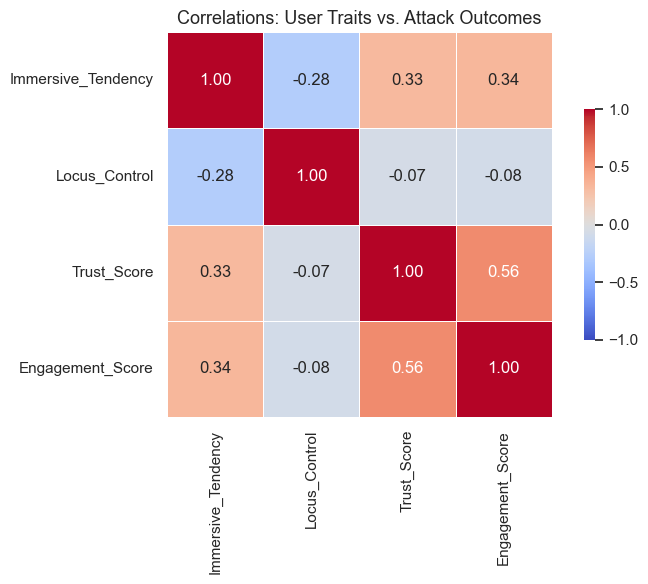

In [1]:
import os
import re
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# --- CONFIGURATION ---
BASE_ROOT = Path(r"c:\Users\nahmed25\PhD\ISMAR26_Engagement")
BASE_PATH_TEXT = BASE_ROOT / "TextualAttack" / "Surveys and Pre-Post Measures"
BASE_PATH_MULTI = BASE_ROOT / "MultiModalAttack" / "Surveys and Pre-Post Measures"

# Candidate participant-id columns seen in survey exports
PID_CANDIDATES = [
    "participant_id",
    "Participant ID",
    "participant id",
    "id",
    "user_id",
]


def standardize_columns(df: pd.DataFrame) -> pd.DataFrame:
    out = df.copy()
    out.columns = [str(c).strip() for c in out.columns]
    return out


def find_participant_col(df: pd.DataFrame) -> str:
    lowered = {c.lower().strip(): c for c in df.columns}
    for candidate in PID_CANDIDATES:
        key = candidate.lower().strip()
        if key in lowered:
            return lowered[key]

    # Fallback: any column containing both participant and id
    for c in df.columns:
        cl = c.lower()
        if "participant" in cl and "id" in cl:
            return c

    raise ValueError("No participant ID column found.")


def load_data(filename: str, path_text: Path, path_multi: Path) -> pd.DataFrame:
    files = [path_text / filename, path_multi / filename]
    frames = []
    for f in files:
        if f.exists():
            df = pd.read_csv(f)
            df = standardize_columns(df)
            df["__source_file"] = str(f)
            frames.append(df)

    if not frames:
        return pd.DataFrame()

    return pd.concat(frames, ignore_index=True)


def get_score(df: pd.DataFrame, score_name: str) -> pd.DataFrame:
    if df.empty:
        return pd.DataFrame(columns=["participant_id", score_name])

    pid_col = find_participant_col(df)

    # Work on numeric columns only
    numerics = df.select_dtypes(include="number").copy()

    # Exclude common metadata-like columns
    exclude_patterns = [r"code", r"id", r"timestamp", r"time"]

    def keep_col(col_name: str) -> bool:
        cl = col_name.lower()
        return not any(re.search(p, cl) for p in exclude_patterns)

    score_cols = [c for c in numerics.columns if keep_col(c)]

    if not score_cols:
        # As fallback, try all numeric cols except a numeric participant column
        score_cols = [c for c in numerics.columns if c != pid_col]

    scored = pd.DataFrame(
        {
            "participant_id": df[pid_col].astype(str).str.strip(),
            score_name: numerics[score_cols].sum(axis=1, skipna=True),
        }
    )

    # If duplicate participant rows exist, average the computed score per participant
    scored = scored.groupby("participant_id", as_index=False)[score_name].mean()
    return scored


# 1) Load predictor/trait surveys
# (Demographics loaded for possible extension; not used in this minimal matrix.)
df_dem = load_data("demographics.csv", BASE_PATH_TEXT, BASE_PATH_MULTI)
df_itq = load_data("immersive_tendencies.csv", BASE_PATH_TEXT, BASE_PATH_MULTI)
df_loc = load_data("locus_of_control.csv", BASE_PATH_TEXT, BASE_PATH_MULTI)

# 2) Load outcome surveys
df_tia = load_data("tia.csv", BASE_PATH_TEXT, BASE_PATH_MULTI)
df_ues = load_data("ues.csv", BASE_PATH_TEXT, BASE_PATH_MULTI)

# 3) Build master table
score_frames = [
    get_score(df_itq, "Immersive_Tendency"),
    get_score(df_loc, "Locus_Control"),
    get_score(df_tia, "Trust_Score"),
    get_score(df_ues, "Engagement_Score"),
]

master = score_frames[0]
for frame in score_frames[1:]:
    master = master.merge(frame, on="participant_id", how="inner")

print(f"Combined Data Shape: {master.shape}")
print("Columns:", list(master.columns))

if master.shape[0] < 3:
    raise ValueError("Not enough matched participants across surveys to compute reliable correlations.")

# 4) Correlation matrix
corr = master.drop(columns=["participant_id"]).corr(numeric_only=True)
print("\nCorrelation matrix:\n", corr)

# 5) Plot
sns.set_theme(style="white")
plt.figure(figsize=(8, 6))

sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    linewidths=0.5,
    cbar_kws={"shrink": 0.6},
)

plt.title("Correlations: User Traits vs. Attack Outcomes", fontsize=13)
plt.tight_layout()

output_path = BASE_ROOT / "figures" / "Figure5_Correlations.png"
output_path.parent.mkdir(parents=True, exist_ok=True)
plt.savefig(output_path, dpi=300, bbox_inches="tight")
print(f"Saved correlation matrix to: {output_path}")
plt.show()

# Engagement Trend Over Time (2-Minute Bins)

This section aggregates **Engagement** self-reports across participants at each 2-minute interval, separately for **Text-Only** and **Multi-Modal** conditions, and plots the **mean** and **variance** over time.

Engagement long shape: (470, 4)
   ParticipantID  Condition  TimeMinutes  Engagement
0            700  Text-Only            2         6.0
1            701  Text-Only            2         7.0
2            702  Text-Only            2         3.0
3            714  Text-Only            2         5.0
4            710  Text-Only            2         6.0

Trend summary (first 10 rows):
     Condition  TimeMinutes      mean  variance   n
0  Multi-Modal            2  5.428571  1.186813  14
1  Multi-Modal            4  5.428571  1.186813  14
2  Multi-Modal            6  5.928571  0.840659  14
3  Multi-Modal            8  6.000000  0.923077  14
4  Multi-Modal           10  6.142857  0.439560  14
5  Multi-Modal           12  5.928571  1.148352  14
6  Multi-Modal           14  6.000000  1.076923  14
7  Multi-Modal           16  6.357143  0.401099  14
8  Multi-Modal           18  6.142857  0.901099  14
9  Multi-Modal           20  6.214286  1.719780  14

Saved: C:\Users\nahmed25\PhD\ISMAR26_Engageme

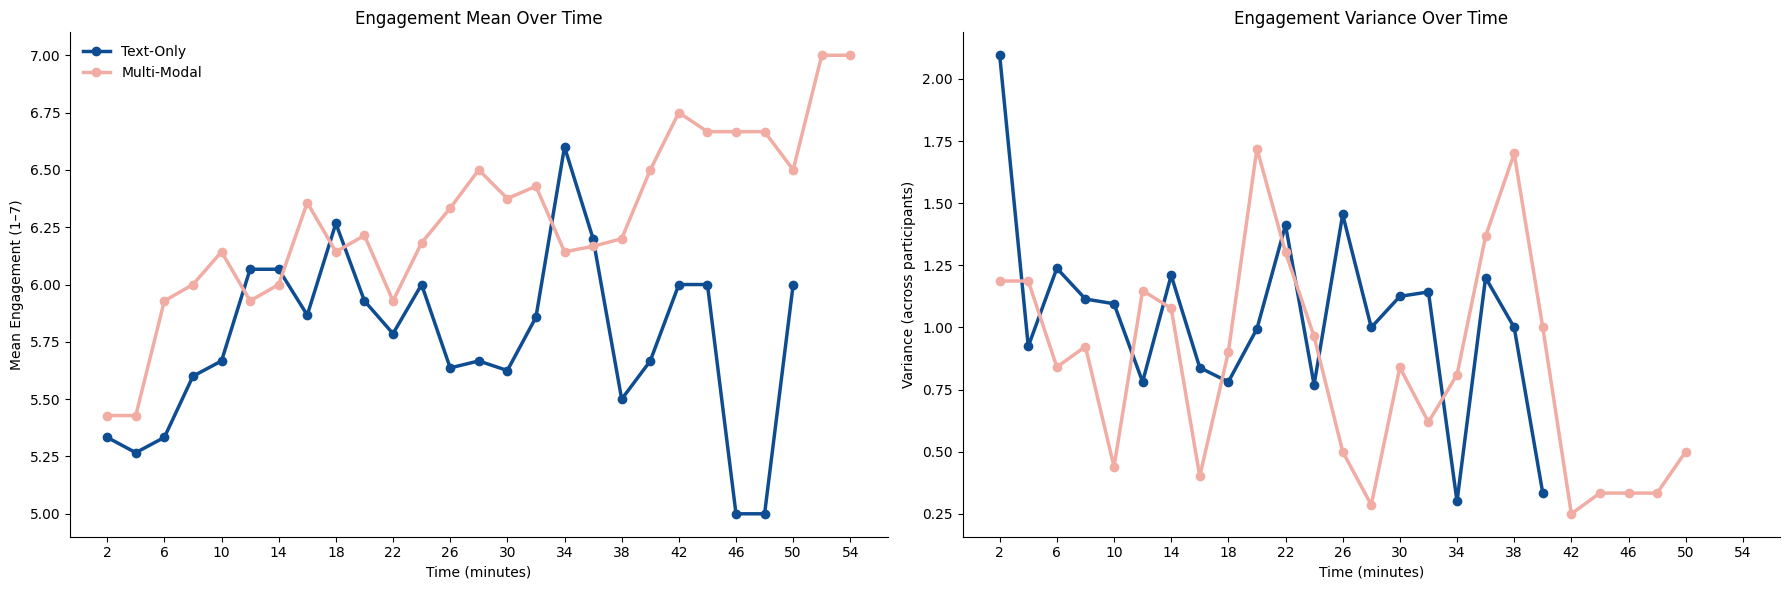

In [3]:
from pathlib import Path
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# -----------------------------
# Configuration
# -----------------------------
BASE_DIR = Path(r"C:\Users\nahmed25\PhD\ISMAR26_Engagement")

TEXT_ENGAGEMENT_FILE = BASE_DIR / "TextualAttack" / "Trust and Engagement Self Report_TextOnly.csv"
MULTI_ENGAGEMENT_FILE = BASE_DIR / "MultiModalAttack" / "Trust and Engagement Self Report_Multi_Modal.csv"

CONDITIONS = {
    "Text-Only": TEXT_ENGAGEMENT_FILE,
    "Multi-Modal": MULTI_ENGAGEMENT_FILE,
}

COLORS = {
    "Text-Only": "#0F4D92",
    "Multi-Modal": "#F1ACA4",
}

EXCLUDE_PARTICIPANT_IDS = {1003}  # incomplete pilot in Multi-Modal

# -----------------------------
# Load + reshape
# -----------------------------
def _parse_participant_id(raw: str) -> int | None:
    if raw is None or (isinstance(raw, float) and np.isnan(raw)):
        return None
    match = re.search(r"(\d+)", str(raw))
    if not match:
        return None
    return int(match.group(1))


def load_engagement_long(file_path: Path, condition: str) -> pd.DataFrame:
    if not file_path.exists():
        raise FileNotFoundError(f"Missing file: {file_path}")
    
    # First row is a prompt/description row, second row is the header
    df = pd.read_csv(file_path, skiprows=1)
    df.columns = [str(c).strip() for c in df.columns]
    df["Condition"] = condition
    
    # Standardize key columns
    required = {"Participant", "Score Type"}
    missing = required - set(df.columns)
    if missing:
        raise ValueError(f"{file_path.name} missing columns: {sorted(missing)}")
    
    # Identify time columns like 'Min 2', 'Min 4', ...
    time_cols = [c for c in df.columns if re.fullmatch(r"Min\s+\d+", str(c))]
    if not time_cols:
        raise ValueError(f"No 'Min N' time columns found in {file_path.name}")
    
    # Only engagement rows
    df = df[df["Score Type"].astype(str).str.strip().str.lower() == "engagement"].copy()
    if df.empty:
        return pd.DataFrame(columns=["ParticipantID", "Condition", "TimeMinutes", "Engagement"])
    
    df["ParticipantID"] = df["Participant"].apply(_parse_participant_id)
    df = df[df["ParticipantID"].notna()].copy()
    df["ParticipantID"] = df["ParticipantID"].astype(int)
    df = df[~df["ParticipantID"].isin(EXCLUDE_PARTICIPANT_IDS)].copy()
    
    long_df = df.melt(
        id_vars=["ParticipantID", "Condition"],
        value_vars=time_cols,
        var_name="TimeLabel",
        value_name="Engagement",
    )
    long_df["TimeMinutes"] = long_df["TimeLabel"].str.replace("Min", "", regex=False).str.strip().astype(int)
    long_df["Engagement"] = pd.to_numeric(long_df["Engagement"], errors="coerce")
    long_df = long_df.dropna(subset=["Engagement"]).copy()
    
    return long_df[["ParticipantID", "Condition", "TimeMinutes", "Engagement"]]


eng_long = pd.concat(
    [load_engagement_long(path, cond) for cond, path in CONDITIONS.items()],
    ignore_index=True,
)

print("Engagement long shape:", eng_long.shape)
print(eng_long.head())

# -----------------------------
# Aggregate: mean + variance
# -----------------------------
trend = (
    eng_long.groupby(["Condition", "TimeMinutes"])["Engagement"]
    .agg(mean="mean", variance=lambda s: s.var(ddof=1), n="count")
    .reset_index()
    .sort_values(["Condition", "TimeMinutes"])
    .reset_index(drop=True)
 )

print("\nTrend summary (first 10 rows):")
print(trend.head(10))

# -----------------------------
# Plot: mean + variance panels
# -----------------------------
plt.rcParams["pdf.fonttype"] = 42
plt.rcParams["ps.fonttype"] = 42
plt.rcParams["axes.spines.right"] = False
plt.rcParams["axes.spines.top"] = False

fig, (ax_mean, ax_var) = plt.subplots(1, 2, figsize=(18, 6), sharex=True)

for cond in CONDITIONS.keys():
    sub = trend[trend["Condition"] == cond]
    ax_mean.plot(
        sub["TimeMinutes"],
        sub["mean"],
        marker="o",
        linewidth=2.5,
        color=COLORS.get(cond, None),
        label=cond,
    )
    ax_var.plot(
        sub["TimeMinutes"],
        sub["variance"],
        marker="o",
        linewidth=2.5,
        color=COLORS.get(cond, None),
        label=cond,
    )

ax_mean.set_title("Engagement Mean Over Time")
ax_mean.set_xlabel("Time (minutes)")
ax_mean.set_ylabel("Mean Engagement (1–7)")
ax_mean.legend(frameon=False)

ax_var.set_title("Engagement Variance Over Time")
ax_var.set_xlabel("Time (minutes)")
ax_var.set_ylabel("Variance (across participants)")

# Ticks: show every 4 minutes to reduce clutter
max_t = int(trend["TimeMinutes"].max()) if not trend.empty else 0
if max_t > 0:
    ticks = list(range(2, max_t + 1, 4))
    ax_mean.set_xticks(ticks)
    ax_var.set_xticks(ticks)

fig.tight_layout()

# Save figure
(BASE_DIR / "figures").mkdir(exist_ok=True)
out_png = BASE_DIR / "figures" / "Figure_EngagementTrend_MeanVariance.png"
out_pdf = BASE_DIR / "figures" / "Figure_EngagementTrend_MeanVariance.pdf"
fig.savefig(out_png, dpi=300, bbox_inches="tight")
fig.savefig(out_pdf, bbox_inches="tight")
print(f"\nSaved: {out_png}")
print(f"Saved: {out_pdf}")

plt.show()

## Engagement Trend by Intensity (within Modality)

This extends the previous plot by splitting each modality into **Low / Medium / High** intensity groups, then plotting the **mean** and **variance** per 2-minute interval.

Engagement (intensity split) long shape: (470, 5)
Trend (intensity split) head:
      Condition Intensity  TimeMinutes  mean  variance  n
0  Multi-Modal      High            2   4.8       0.7  5
1  Multi-Modal      High            4   5.0       0.5  5
2  Multi-Modal      High            6   5.2       0.7  5
3  Multi-Modal      High            8   5.2       0.7  5
4  Multi-Modal      High           10   5.8       0.2  5
5  Multi-Modal      High           12   5.6       1.3  5
6  Multi-Modal      High           14   5.6       1.3  5
7  Multi-Modal      High           16   5.8       0.2  5
8  Multi-Modal      High           18   5.4       0.8  5
9  Multi-Modal      High           20   5.4       3.3  5
Saved: C:\Users\nahmed25\PhD\ISMAR26_Engagement\figures\Figure_EngagementTrend_MeanVariance_Low.png
Saved: C:\Users\nahmed25\PhD\ISMAR26_Engagement\figures\Figure_EngagementTrend_MeanVariance_Low.pdf


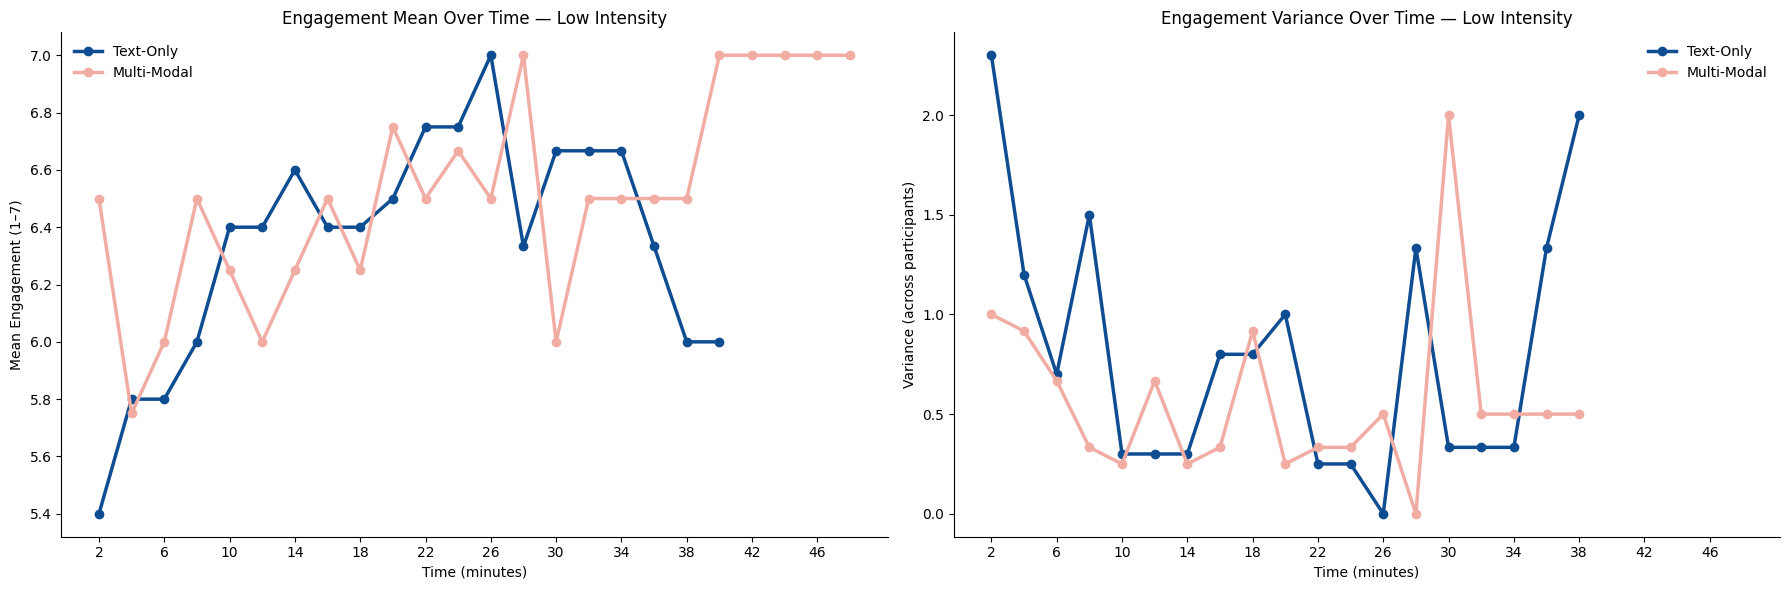

Saved: C:\Users\nahmed25\PhD\ISMAR26_Engagement\figures\Figure_EngagementTrend_MeanVariance_Medium.png
Saved: C:\Users\nahmed25\PhD\ISMAR26_Engagement\figures\Figure_EngagementTrend_MeanVariance_Medium.pdf


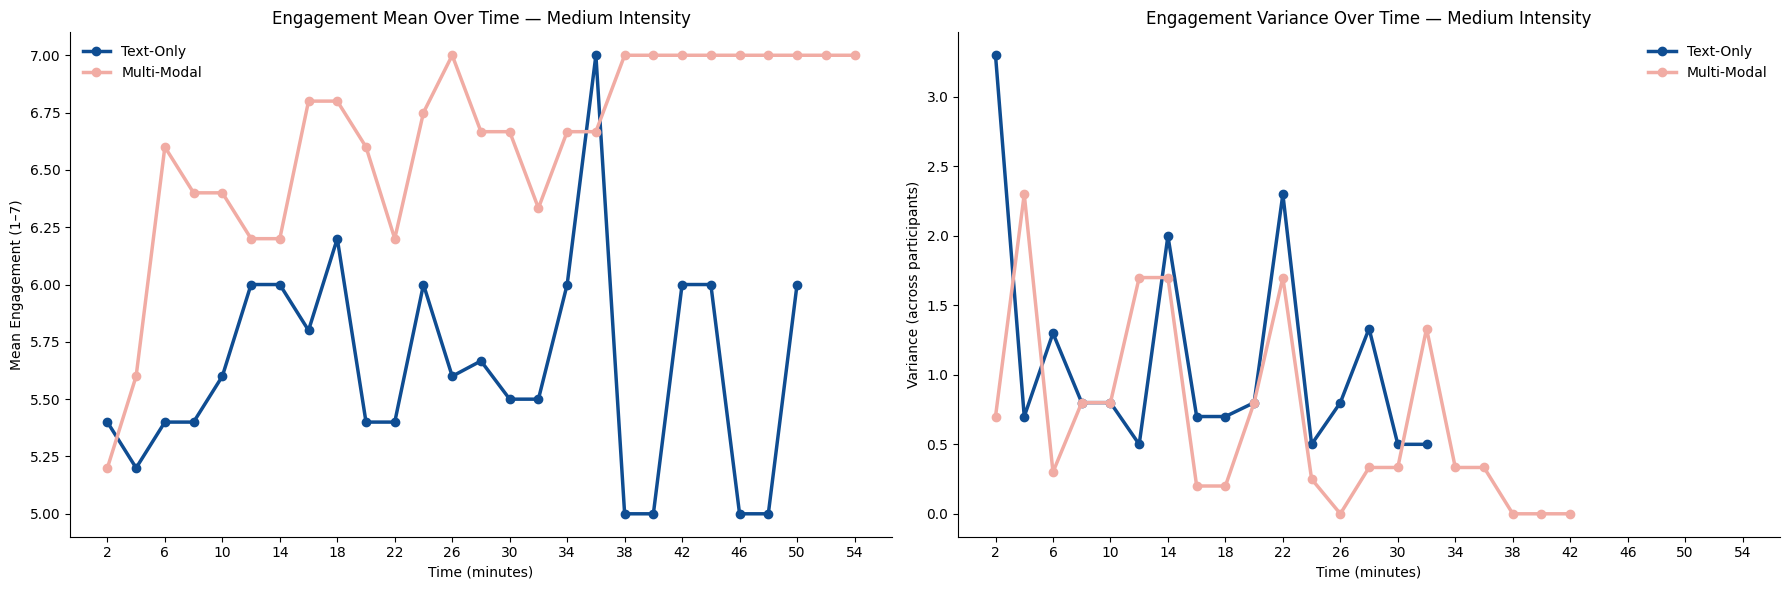

Saved: C:\Users\nahmed25\PhD\ISMAR26_Engagement\figures\Figure_EngagementTrend_MeanVariance_High.png
Saved: C:\Users\nahmed25\PhD\ISMAR26_Engagement\figures\Figure_EngagementTrend_MeanVariance_High.pdf


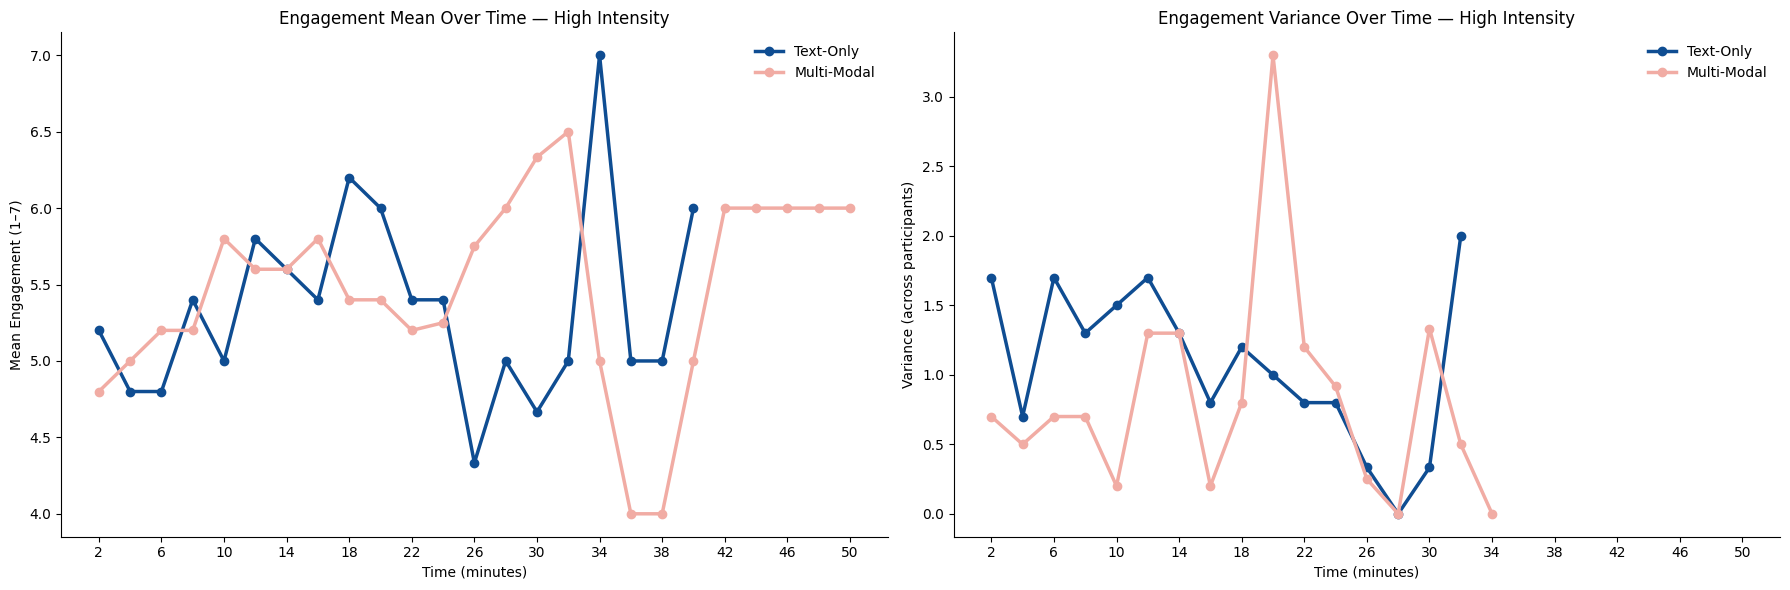

In [5]:
from pathlib import Path
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# -----------------------------
# Configuration (Intensity split)
# -----------------------------
BASE_DIR = Path(r"C:\Users\nahmed25\PhD\ISMAR26_Engagement")

TEXT_ENGAGEMENT_FILE = BASE_DIR / "TextualAttack" / "Trust and Engagement Self Report_TextOnly.csv"
MULTI_ENGAGEMENT_FILE = BASE_DIR / "MultiModalAttack" / "Trust and Engagement Self Report_Multi_Modal.csv"

CONDITIONS = {
    "Text-Only": TEXT_ENGAGEMENT_FILE,
    "Multi-Modal": MULTI_ENGAGEMENT_FILE,
}

COLORS = {
    "Text-Only": "#0F4D92",
    "Multi-Modal": "#F1ACA4",
}

EXCLUDE_PARTICIPANT_IDS = {1003}

# -----------------------------
# Helpers
# -----------------------------
def _parse_participant_id(raw: str) -> int | None:
    if raw is None or (isinstance(raw, float) and np.isnan(raw)):
        return None
    match = re.search(r"(\d+)", str(raw))
    if not match:
        return None
    return int(match.group(1))


def _clean_intensity(raw: str) -> str | None:
    if raw is None or (isinstance(raw, float) and np.isnan(raw)):
        return None
    val = str(raw).strip().capitalize()
    if val in {"Low", "Medium", "High"}:
        return val
    return None


def load_engagement_long_with_intensity(file_path: Path, condition: str) -> pd.DataFrame:
    if not file_path.exists():
        raise FileNotFoundError(f"Missing file: {file_path}")
    
    df = pd.read_csv(file_path, skiprows=1)
    df.columns = [str(c).strip() for c in df.columns]
    df["Condition"] = condition
    
    required = {"Participant", "Score Type", "Intensity"}
    missing = required - set(df.columns)
    if missing:
        raise ValueError(f"{file_path.name} missing columns: {sorted(missing)}")
    
    time_cols = [c for c in df.columns if re.fullmatch(r"Min\s+\d+", str(c))]
    if not time_cols:
        raise ValueError(f"No 'Min N' time columns found in {file_path.name}")
    
    df = df[df["Score Type"].astype(str).str.strip().str.lower() == "engagement"].copy()
    if df.empty:
        return pd.DataFrame(columns=["ParticipantID", "Condition", "Intensity", "TimeMinutes", "Engagement"])
    
    df["ParticipantID"] = df["Participant"].apply(_parse_participant_id)
    df["Intensity"] = df["Intensity"].apply(_clean_intensity)
    df = df[df["ParticipantID"].notna() & df["Intensity"].notna()].copy()
    df["ParticipantID"] = df["ParticipantID"].astype(int)
    df = df[~df["ParticipantID"].isin(EXCLUDE_PARTICIPANT_IDS)].copy()
    
    long_df = df.melt(
        id_vars=["ParticipantID", "Condition", "Intensity"],
        value_vars=time_cols,
        var_name="TimeLabel",
        value_name="Engagement",
    )
    long_df["TimeMinutes"] = long_df["TimeLabel"].str.replace("Min", "", regex=False).str.strip().astype(int)
    long_df["Engagement"] = pd.to_numeric(long_df["Engagement"], errors="coerce")
    long_df = long_df.dropna(subset=["Engagement"]).copy()
    return long_df[["ParticipantID", "Condition", "Intensity", "TimeMinutes", "Engagement"]]


eng_long_int = pd.concat(
    [load_engagement_long_with_intensity(path, cond) for cond, path in CONDITIONS.items()],
    ignore_index=True,
)

trend_int = (
    eng_long_int.groupby(["Condition", "Intensity", "TimeMinutes"])["Engagement"]
    .agg(mean="mean", variance=lambda s: s.var(ddof=1), n="count")
    .reset_index()
    .sort_values(["Condition", "Intensity", "TimeMinutes"])
    .reset_index(drop=True)
)

print("Engagement (intensity split) long shape:", eng_long_int.shape)
print("Trend (intensity split) head:\n", trend_int.head(10))

# -----------------------------
# Plot: separate figure per intensity
# -----------------------------
plt.rcParams["pdf.fonttype"] = 42
plt.rcParams["ps.fonttype"] = 42
plt.rcParams["axes.spines.right"] = False
plt.rcParams["axes.spines.top"] = False

(BASE_DIR / "figures").mkdir(exist_ok=True)

for intensity in ["Low", "Medium", "High"]:
    subset_int = trend_int[trend_int["Intensity"] == intensity]
    if subset_int.empty:
        print(f"No data for intensity={intensity}; skipping")
        continue

    fig, (ax_mean, ax_var) = plt.subplots(1, 2, figsize=(18, 6), sharex=True)

    for cond in CONDITIONS.keys():
        sub = subset_int[subset_int["Condition"] == cond]
        if sub.empty:
            continue
        ax_mean.plot(
            sub["TimeMinutes"],
            sub["mean"],
            marker="o",
            linewidth=2.5,
            color=COLORS.get(cond, None),
            label=cond,
        )
        ax_var.plot(
            sub["TimeMinutes"],
            sub["variance"],
            marker="o",
            linewidth=2.5,
            color=COLORS.get(cond, None),
            label=cond,
        )

    ax_mean.set_title(f"Engagement Mean Over Time — {intensity} Intensity")
    ax_mean.set_xlabel("Time (minutes)")
    ax_mean.set_ylabel("Mean Engagement (1–7)")
    ax_mean.legend(frameon=False)

    ax_var.set_title(f"Engagement Variance Over Time — {intensity} Intensity")
    ax_var.set_xlabel("Time (minutes)")
    ax_var.set_ylabel("Variance (across participants)")
    ax_var.legend(frameon=False)

    max_t = int(subset_int["TimeMinutes"].max()) if not subset_int.empty else 0
    if max_t > 0:
        ticks = list(range(2, max_t + 1, 4))
        ax_mean.set_xticks(ticks)
        ax_var.set_xticks(ticks)

    fig.tight_layout()

    out_png = BASE_DIR / "figures" / f"Figure_EngagementTrend_MeanVariance_{intensity}.png"
    out_pdf = BASE_DIR / "figures" / f"Figure_EngagementTrend_MeanVariance_{intensity}.pdf"
    fig.savefig(out_png, dpi=300, bbox_inches="tight")
    fig.savefig(out_pdf, bbox_inches="tight")
    print(f"Saved: {out_png}")
    print(f"Saved: {out_pdf}")
    plt.show()

# Performance Trend Over Time (2-Minute Bins)

This section aggregates **task performance** from the `*_activityData.csv` logs for **Text-Only** and **Multi-Modal** conditions across all participants, binned into 2-minute intervals. We report **mean** and **variance** across participants per bin.

Text-Only: found 15 performance files
Multi-Modal: found 14 performance files

Combined performance rows: 718
   ParticipantID  Condition  ActivityStart_s  ActivityEnd_s  IsCorrect01  \
0            700  Text-Only        40.710085      48.106077          1.0   
1            700  Text-Only       162.113233     248.308156          1.0   
2            700  Text-Only       272.327489     311.276734          0.0   
3            700  Text-Only       332.764046     343.191820          1.0   
4            700  Text-Only       392.510636     407.856282          1.0   

   NumberOfAttempts  StepDuration_s  ActivityDuration_s  
0               1.0       19.563472            7.395993  
1               4.0      192.999443           86.194923  
2               3.0       47.684765           38.949245  
3               1.0       22.743272           10.427774  
4               2.0       43.872123           15.345646  

Performance trend head:
      Condition  TimeMinutes  mean_accuracy  var_accuracy  n

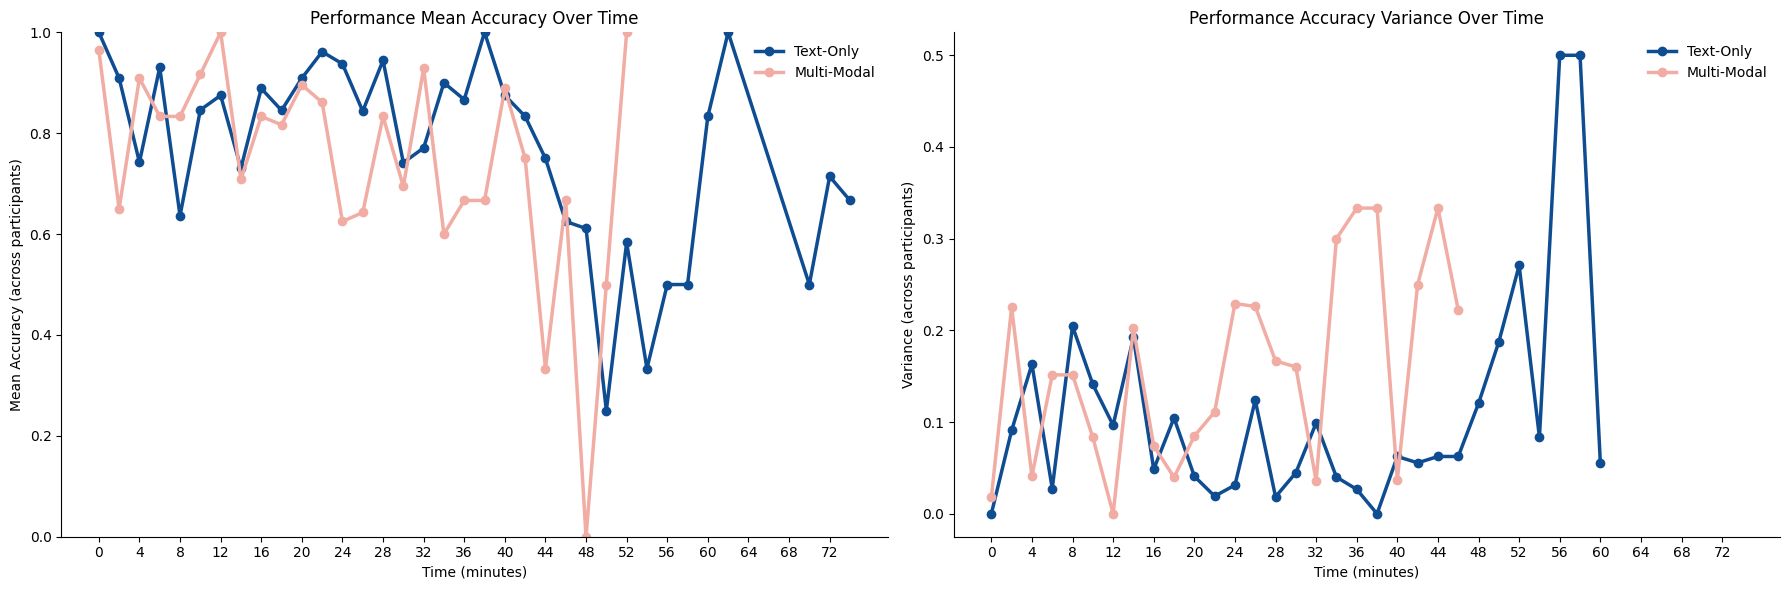

In [6]:
from pathlib import Path
import glob
import os
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# -----------------------------
# Configuration
# -----------------------------
BASE_DIR = Path(r"C:\Users\nahmed25\PhD\ISMAR26_Engagement")

TEXT_PERF_DIR = BASE_DIR / "TextualAttack" / "user performance"
MULTI_PERF_DIR = BASE_DIR / "MultiModalAttack" / "user performance"

PERF_CONDITIONS = {
    "Text-Only": TEXT_PERF_DIR,
    "Multi-Modal": MULTI_PERF_DIR,
}

COLORS = {
    "Text-Only": "#0F4D92",
    "Multi-Modal": "#F1ACA4",
}

EXCLUDE_PARTICIPANT_IDS = {1003}

# -----------------------------
# Helpers
# -----------------------------
def _extract_pid_from_filename(path: str) -> int | None:
    name = os.path.basename(path)
    match = re.match(r"(\d+)_", name)
    return int(match.group(1)) if match else None


def _to_numeric(series: pd.Series) -> pd.Series:
    return pd.to_numeric(series, errors="coerce")


def _to_bool01(series: pd.Series) -> pd.Series:
    # Accept bool, TRUE/FALSE strings, or 1/0
    s = series.copy()
    if s.dtype == bool:
        return s.astype(int)
    s = s.astype(str).str.strip().str.lower()
    mapping = {"true": 1, "false": 0, "1": 1, "0": 0}
    out = s.map(mapping)
    return pd.to_numeric(out, errors="coerce")


def _standardize_performance_df(raw: pd.DataFrame, condition: str, pid: int) -> pd.DataFrame:
    df = raw.copy()
    df.columns = [str(c).strip() for c in df.columns]

    # TextualAttack schema (has video timestamps)
    if {"VideoActivityStartTimeStampInSeconds", "VideoActivityEndTimeStampInSeconds"}.issubset(df.columns):
        act_start = _to_numeric(df["VideoActivityStartTimeStampInSeconds"])
        act_end = _to_numeric(df["VideoActivityEndTimeStampInSeconds"])
        is_correct = _to_bool01(df.get("IsCorrect", pd.Series([np.nan] * len(df))))
        attempts = _to_numeric(df.get("NumberOfAttempts", pd.Series([np.nan] * len(df))))
        step_dur = _to_numeric(df.get("StepDurationInSeconds", pd.Series([np.nan] * len(df))))
        act_dur = _to_numeric(df.get("ActivityDurationInSeconds", pd.Series([np.nan] * len(df))))

    # MultiModalAttack schema (11 cols, but header labels are misleading)
    elif df.shape[1] == 11:
        # Positional mapping based on observed files:
        # 0 StepName, 1 ActivityName, 2 IsCorrect, 3 AnswerList, 4 NumberOfAttempts,
        # 5 StepStart(s), 6 StepEnd(s), 7 StepDur(s), 8 ActivityStart(s), 9 ActivityEnd(s), 10 ActivityDur(s)
        act_start = _to_numeric(df.iloc[:, 8])
        act_end = _to_numeric(df.iloc[:, 9])
        is_correct = _to_bool01(df.iloc[:, 2])
        attempts = _to_numeric(df.iloc[:, 4])
        step_dur = _to_numeric(df.iloc[:, 7])
        act_dur = _to_numeric(df.iloc[:, 10])
    else:
        raise ValueError(f"Unrecognized performance schema for {condition}, pid={pid}. Columns={df.columns.tolist()}")

    out = pd.DataFrame({
        "ParticipantID": pid,
        "Condition": condition,
        "ActivityStart_s": act_start,
        "ActivityEnd_s": act_end,
        "IsCorrect01": is_correct,
        "NumberOfAttempts": attempts,
        "StepDuration_s": step_dur,
        "ActivityDuration_s": act_dur,
    })

    out = out.dropna(subset=["ActivityStart_s", "ActivityEnd_s"])
    out = out[out["ActivityEnd_s"] >= out["ActivityStart_s"]]
    return out


def load_performance(condition: str, folder: Path) -> pd.DataFrame:
    files = sorted(glob.glob(str(folder / "*_activityData.csv")))
    rows = []
    print(f"{condition}: found {len(files)} performance files")

    for f in files:
        pid = _extract_pid_from_filename(f)
        if pid is None:
            continue
        if pid in EXCLUDE_PARTICIPANT_IDS:
            continue

        try:
            raw = pd.read_csv(f)
            std = _standardize_performance_df(raw, condition=condition, pid=pid)
            rows.append(std)
        except Exception as e:
            print(f"Skipping {f} ({pid}): {e}")

    if not rows:
        return pd.DataFrame(columns=[
            "ParticipantID","Condition","ActivityStart_s","ActivityEnd_s",
            "IsCorrect01","NumberOfAttempts","StepDuration_s","ActivityDuration_s"
        ])
    return pd.concat(rows, ignore_index=True)


# -----------------------------
# Load + bin to 2-minute windows
# -----------------------------
perf = pd.concat(
    [load_performance(cond, folder) for cond, folder in PERF_CONDITIONS.items()],
    ignore_index=True,
)

print("\nCombined performance rows:", len(perf))
print(perf.head())

if perf.empty:
    raise ValueError("No performance rows loaded.")

perf["Midpoint_s"] = (perf["ActivityStart_s"] + perf["ActivityEnd_s"]) / 2.0
perf["TimeMinutes"] = ((perf["Midpoint_s"] // 120) * 2).astype(int)

# Participant-level aggregation per bin (so variance is across participants)
per_pid_bin = (
    perf.groupby(["Condition", "ParticipantID", "TimeMinutes"], as_index=False)
    .agg(Accuracy=("IsCorrect01", "mean"), Activities=("IsCorrect01", "count"))
)

trend_perf = (
    per_pid_bin.groupby(["Condition", "TimeMinutes"], as_index=False)
    .agg(
        mean_accuracy=("Accuracy", "mean"),
        var_accuracy=("Accuracy", lambda s: s.var(ddof=1)),
        n_participants=("ParticipantID", "nunique"),
        total_activities=("Activities", "sum"),
    )
    .sort_values(["Condition", "TimeMinutes"])
    .reset_index(drop=True)
)

print("\nPerformance trend head:\n", trend_perf.head(10))

# -----------------------------
# Plot: mean + variance of accuracy
# -----------------------------
plt.rcParams["pdf.fonttype"] = 42
plt.rcParams["ps.fonttype"] = 42
plt.rcParams["axes.spines.right"] = False
plt.rcParams["axes.spines.top"] = False

fig, (ax_mean, ax_var) = plt.subplots(1, 2, figsize=(18, 6), sharex=True)

for cond in PERF_CONDITIONS.keys():
    sub = trend_perf[trend_perf["Condition"] == cond]
    ax_mean.plot(
        sub["TimeMinutes"],
        sub["mean_accuracy"],
        marker="o",
        linewidth=2.5,
        color=COLORS.get(cond, None),
        label=cond,
    )
    ax_var.plot(
        sub["TimeMinutes"],
        sub["var_accuracy"],
        marker="o",
        linewidth=2.5,
        color=COLORS.get(cond, None),
        label=cond,
    )

ax_mean.set_title("Performance Mean Accuracy Over Time")
ax_mean.set_xlabel("Time (minutes)")
ax_mean.set_ylabel("Mean Accuracy (across participants)")
ax_mean.set_ylim(0, 1)
ax_mean.legend(frameon=False)

ax_var.set_title("Performance Accuracy Variance Over Time")
ax_var.set_xlabel("Time (minutes)")
ax_var.set_ylabel("Variance (across participants)")
ax_var.legend(frameon=False)

max_t = int(trend_perf["TimeMinutes"].max()) if not trend_perf.empty else 0
if max_t > 0:
    ticks = list(range(0, max_t + 1, 4))
    ax_mean.set_xticks(ticks)
    ax_var.set_xticks(ticks)

fig.tight_layout()

(BASE_DIR / "figures").mkdir(exist_ok=True)
out_png = BASE_DIR / "figures" / "Figure_PerformanceTrend_Accuracy_MeanVariance.png"
out_pdf = BASE_DIR / "figures" / "Figure_PerformanceTrend_Accuracy_MeanVariance.pdf"
fig.savefig(out_png, dpi=300, bbox_inches="tight")
fig.savefig(out_pdf, bbox_inches="tight")
print(f"\nSaved: {out_png}")
print(f"Saved: {out_pdf}")

plt.show()

## Performance Trend by Intensity (2-Minute Bins)

This section assigns each participant an **attack intensity** (Low/Medium/High) using the Trust/Engagement self-report file, then aggregates **performance accuracy** over time separately for each intensity (with Text-Only vs Multi-Modal shown within each intensity figure).

Intensity lookup rows: 29
   ParticipantID  Condition Intensity
0            700  Text-Only       Low
1            701  Text-Only       Low
2            702  Text-Only       Low
3            714  Text-Only       Low
4            710  Text-Only       Low
Text-Only: found 15 performance files
Multi-Modal: found 14 performance files

Performance rows with intensity: 718
   ParticipantID  Condition Intensity  ActivityStart_s  ActivityEnd_s  \
0            700  Text-Only       Low        40.710085      48.106077   
1            700  Text-Only       Low       162.113233     248.308156   
2            700  Text-Only       Low       272.327489     311.276734   
3            700  Text-Only       Low       332.764046     343.191820   
4            700  Text-Only       Low       392.510636     407.856282   

   IsCorrect01  
0          1.0  
1          1.0  
2          0.0  
3          1.0  
4          1.0  

Performance trend by intensity head:
      Condition Intensity  TimeMinutes  mean_accura

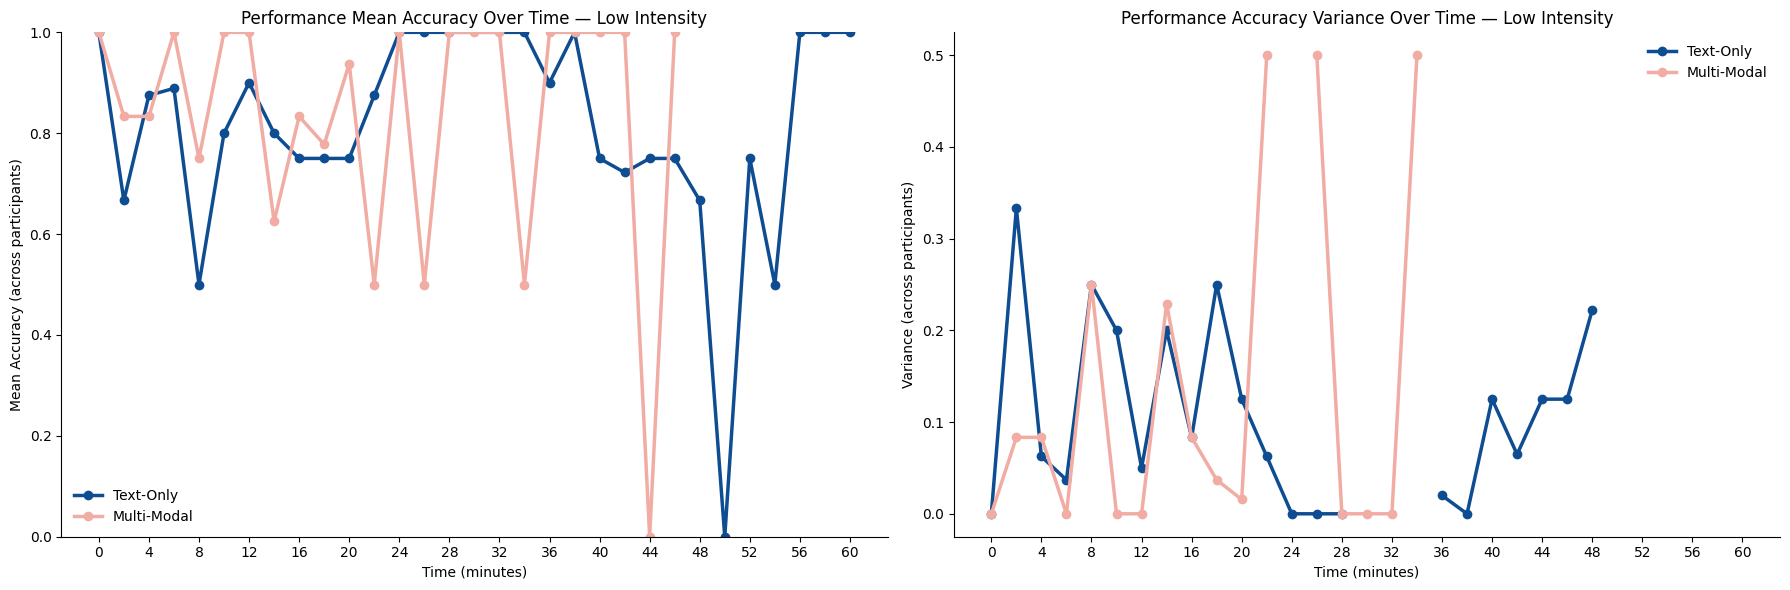

Saved: C:\Users\nahmed25\PhD\ISMAR26_Engagement\figures\Figure_PerformanceTrend_Accuracy_MeanVariance_Medium.png
Saved: C:\Users\nahmed25\PhD\ISMAR26_Engagement\figures\Figure_PerformanceTrend_Accuracy_MeanVariance_Medium.pdf


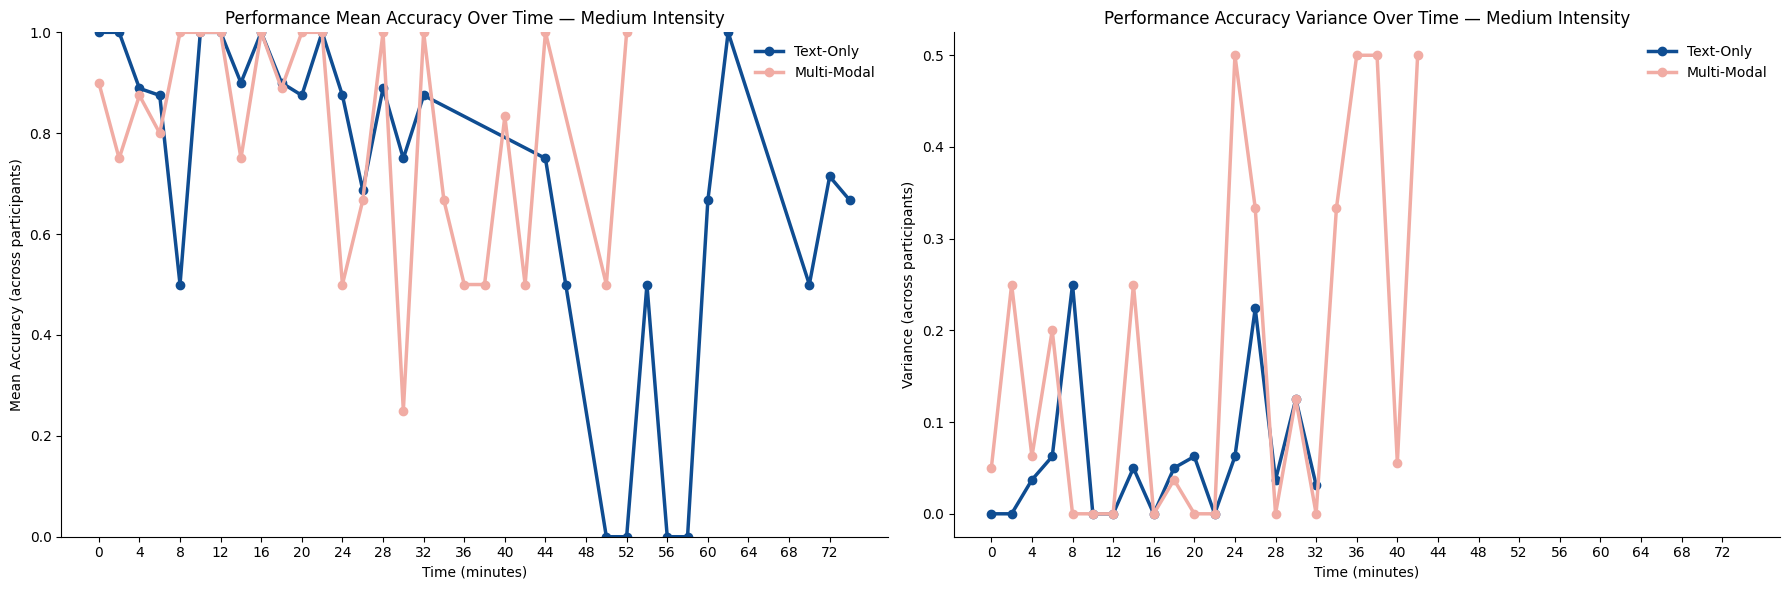

Saved: C:\Users\nahmed25\PhD\ISMAR26_Engagement\figures\Figure_PerformanceTrend_Accuracy_MeanVariance_High.png
Saved: C:\Users\nahmed25\PhD\ISMAR26_Engagement\figures\Figure_PerformanceTrend_Accuracy_MeanVariance_High.pdf


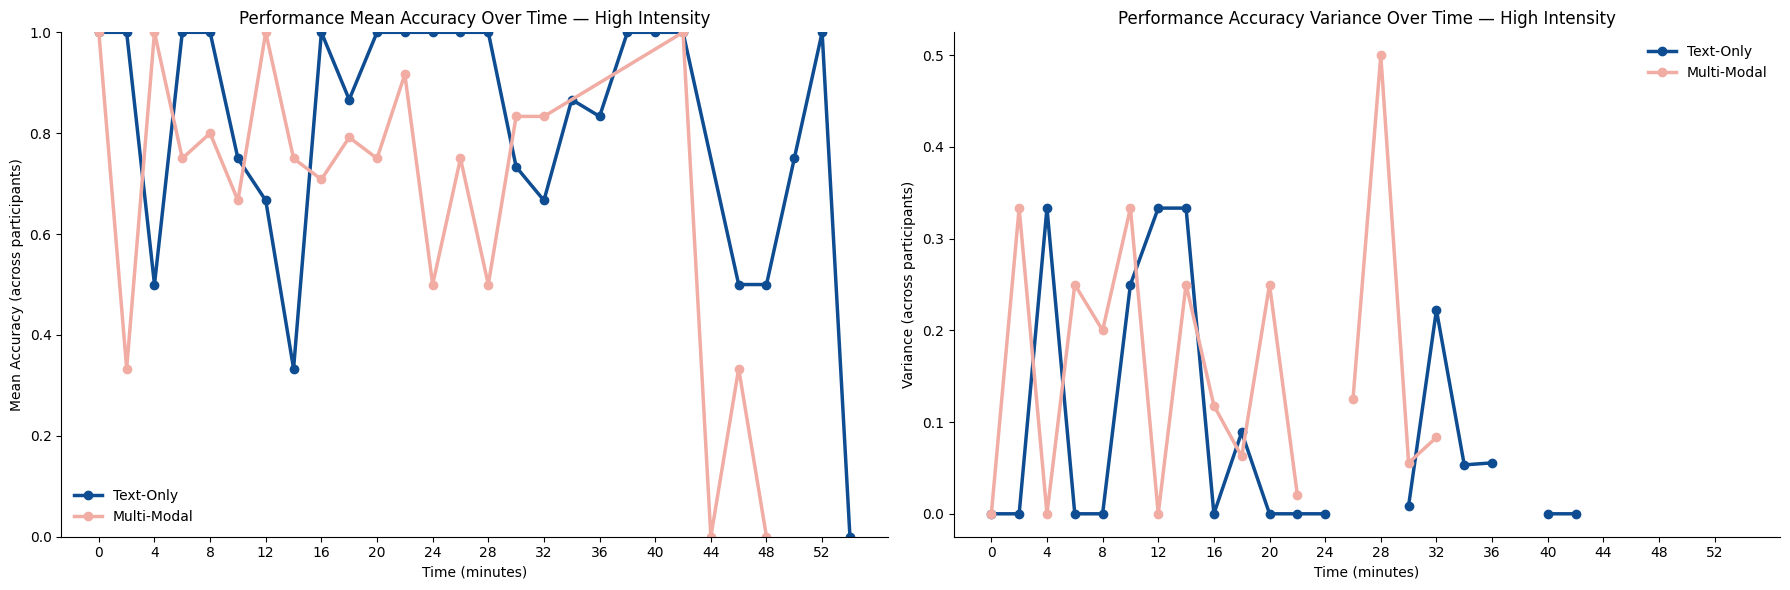

In [7]:
from pathlib import Path
import glob
import os
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# -----------------------------
# Configuration
# -----------------------------
BASE_DIR = Path(r"C:\Users\nahmed25\PhD\ISMAR26_Engagement")

TEXT_ENGAGEMENT_FILE = BASE_DIR / "TextualAttack" / "Trust and Engagement Self Report_TextOnly.csv"
MULTI_ENGAGEMENT_FILE = BASE_DIR / "MultiModalAttack" / "Trust and Engagement Self Report_Multi_Modal.csv"

TEXT_PERF_DIR = BASE_DIR / "TextualAttack" / "user performance"
MULTI_PERF_DIR = BASE_DIR / "MultiModalAttack" / "user performance"

CONDITIONS = {
    "Text-Only": {"eng": TEXT_ENGAGEMENT_FILE, "perf_dir": TEXT_PERF_DIR},
    "Multi-Modal": {"eng": MULTI_ENGAGEMENT_FILE, "perf_dir": MULTI_PERF_DIR},
}

COLORS = {
    "Text-Only": "#0F4D92",
    "Multi-Modal": "#F1ACA4",
}

EXCLUDE_PARTICIPANT_IDS = {1003}

# -----------------------------
# Intensity map from self-report
# -----------------------------
def _parse_participant_id(raw: str) -> int | None:
    if raw is None or (isinstance(raw, float) and np.isnan(raw)):
        return None
    m = re.search(r"(\d+)", str(raw))
    return int(m.group(1)) if m else None


def _clean_intensity(raw: str) -> str | None:
    if raw is None or (isinstance(raw, float) and np.isnan(raw)):
        return None
    val = str(raw).strip().capitalize()
    return val if val in {"Low", "Medium", "High"} else None


def load_intensity_lookup(path: Path, condition: str) -> pd.DataFrame:
    df = pd.read_csv(path, skiprows=1)
    df.columns = [str(c).strip() for c in df.columns]
    required = {"Participant", "Intensity", "Score Type"}
    missing = required - set(df.columns)
    if missing:
        raise ValueError(f"{path.name} missing columns: {sorted(missing)}")
    # Use only Engagement rows (intensity is duplicated across score types, but keep it consistent)
    df = df[df["Score Type"].astype(str).str.strip().str.lower() == "engagement"].copy()
    df["ParticipantID"] = df["Participant"].apply(_parse_participant_id)
    df["Intensity"] = df["Intensity"].apply(_clean_intensity)
    df = df[df["ParticipantID"].notna() & df["Intensity"].notna()].copy()
    df["ParticipantID"] = df["ParticipantID"].astype(int)
    df = df[~df["ParticipantID"].isin(EXCLUDE_PARTICIPANT_IDS)].copy()
    df["Condition"] = condition
    return df[["ParticipantID", "Condition", "Intensity"]].drop_duplicates()


intensity_lookup = pd.concat(
    [load_intensity_lookup(meta["eng"], cond) for cond, meta in CONDITIONS.items()],
    ignore_index=True,
)

print("Intensity lookup rows:", len(intensity_lookup))
print(intensity_lookup.head())

# -----------------------------
# Performance loader (same logic as previous section)
# -----------------------------
def _extract_pid_from_filename(path: str) -> int | None:
    name = os.path.basename(path)
    match = re.match(r"(\d+)_", name)
    return int(match.group(1)) if match else None


def _to_numeric(series: pd.Series) -> pd.Series:
    return pd.to_numeric(series, errors="coerce")


def _to_bool01(series: pd.Series) -> pd.Series:
    s = series.copy()
    if s.dtype == bool:
        return s.astype(int)
    s = s.astype(str).str.strip().str.lower()
    mapping = {"true": 1, "false": 0, "1": 1, "0": 0}
    out = s.map(mapping)
    return pd.to_numeric(out, errors="coerce")


def _standardize_performance_df(raw: pd.DataFrame, condition: str, pid: int) -> pd.DataFrame:
    df = raw.copy()
    df.columns = [str(c).strip() for c in df.columns]

    if {"VideoActivityStartTimeStampInSeconds", "VideoActivityEndTimeStampInSeconds"}.issubset(df.columns):
        act_start = _to_numeric(df["VideoActivityStartTimeStampInSeconds"])
        act_end = _to_numeric(df["VideoActivityEndTimeStampInSeconds"])
        is_correct = _to_bool01(df.get("IsCorrect", pd.Series([np.nan] * len(df))))
    elif df.shape[1] == 11:
        act_start = _to_numeric(df.iloc[:, 8])
        act_end = _to_numeric(df.iloc[:, 9])
        is_correct = _to_bool01(df.iloc[:, 2])
    else:
        raise ValueError(f"Unrecognized performance schema for {condition}, pid={pid}")

    out = pd.DataFrame({
        "ParticipantID": pid,
        "Condition": condition,
        "ActivityStart_s": act_start,
        "ActivityEnd_s": act_end,
        "IsCorrect01": is_correct,
    })
    out = out.dropna(subset=["ActivityStart_s", "ActivityEnd_s"])
    out = out[out["ActivityEnd_s"] >= out["ActivityStart_s"]]
    return out


def load_performance(condition: str, folder: Path) -> pd.DataFrame:
    files = sorted(glob.glob(str(folder / "*_activityData.csv")))
    rows = []
    print(f"{condition}: found {len(files)} performance files")
    for f in files:
        pid = _extract_pid_from_filename(f)
        if pid is None or pid in EXCLUDE_PARTICIPANT_IDS:
            continue
        try:
            raw = pd.read_csv(f)
            rows.append(_standardize_performance_df(raw, condition=condition, pid=pid))
        except Exception as e:
            print(f"Skipping {f} ({pid}): {e}")
    return pd.concat(rows, ignore_index=True) if rows else pd.DataFrame()


perf = pd.concat(
    [load_performance(cond, meta["perf_dir"]) for cond, meta in CONDITIONS.items()],
    ignore_index=True,
)

if perf.empty:
    raise ValueError("No performance rows loaded.")

# Join intensity onto performance
perf = perf.merge(intensity_lookup, on=["ParticipantID", "Condition"], how="left")
perf = perf[perf["Intensity"].notna()].copy()

print("\nPerformance rows with intensity:", len(perf))
print(perf[["ParticipantID","Condition","Intensity","ActivityStart_s","ActivityEnd_s","IsCorrect01"]].head())

# 2-minute bins on activity midpoint
perf["Midpoint_s"] = (perf["ActivityStart_s"] + perf["ActivityEnd_s"]) / 2.0
perf["TimeMinutes"] = ((perf["Midpoint_s"] // 120) * 2).astype(int)

# Participant-level per bin (variance across participants)
per_pid_bin = (
    perf.groupby(["Condition", "Intensity", "ParticipantID", "TimeMinutes"], as_index=False)
    .agg(Accuracy=("IsCorrect01", "mean"), Activities=("IsCorrect01", "count"))
)

trend_perf_int = (
    per_pid_bin.groupby(["Condition", "Intensity", "TimeMinutes"], as_index=False)
    .agg(
        mean_accuracy=("Accuracy", "mean"),
        var_accuracy=("Accuracy", lambda s: s.var(ddof=1)),
        n_participants=("ParticipantID", "nunique"),
        total_activities=("Activities", "sum"),
    )
    .sort_values(["Intensity", "Condition", "TimeMinutes"])
    .reset_index(drop=True)
)

print("\nPerformance trend by intensity head:\n", trend_perf_int.head(10))

# -----------------------------
# Plot: separate figure per intensity
# -----------------------------
plt.rcParams["pdf.fonttype"] = 42
plt.rcParams["ps.fonttype"] = 42
plt.rcParams["axes.spines.right"] = False
plt.rcParams["axes.spines.top"] = False

(BASE_DIR / "figures").mkdir(exist_ok=True)

for intensity in ["Low", "Medium", "High"]:
    subset_int = trend_perf_int[trend_perf_int["Intensity"] == intensity]
    if subset_int.empty:
        print(f"No performance data for intensity={intensity}; skipping")
        continue

    fig, (ax_mean, ax_var) = plt.subplots(1, 2, figsize=(18, 6), sharex=True)

    for cond in CONDITIONS.keys():
        sub = subset_int[subset_int["Condition"] == cond]
        if sub.empty:
            continue
        ax_mean.plot(
            sub["TimeMinutes"],
            sub["mean_accuracy"],
            marker="o",
            linewidth=2.5,
            color=COLORS.get(cond, None),
            label=cond,
        )
        ax_var.plot(
            sub["TimeMinutes"],
            sub["var_accuracy"],
            marker="o",
            linewidth=2.5,
            color=COLORS.get(cond, None),
            label=cond,
        )

    ax_mean.set_title(f"Performance Mean Accuracy Over Time — {intensity} Intensity")
    ax_mean.set_xlabel("Time (minutes)")
    ax_mean.set_ylabel("Mean Accuracy (across participants)")
    ax_mean.set_ylim(0, 1)
    ax_mean.legend(frameon=False)

    ax_var.set_title(f"Performance Accuracy Variance Over Time — {intensity} Intensity")
    ax_var.set_xlabel("Time (minutes)")
    ax_var.set_ylabel("Variance (across participants)")
    ax_var.legend(frameon=False)

    max_t = int(subset_int["TimeMinutes"].max()) if not subset_int.empty else 0
    if max_t > 0:
        ticks = list(range(0, max_t + 1, 4))
        ax_mean.set_xticks(ticks)
        ax_var.set_xticks(ticks)

    fig.tight_layout()

    out_png = BASE_DIR / "figures" / f"Figure_PerformanceTrend_Accuracy_MeanVariance_{intensity}.png"
    out_pdf = BASE_DIR / "figures" / f"Figure_PerformanceTrend_Accuracy_MeanVariance_{intensity}.pdf"
    fig.savefig(out_png, dpi=300, bbox_inches="tight")
    fig.savefig(out_pdf, bbox_inches="tight")
    print(f"Saved: {out_png}")
    print(f"Saved: {out_pdf}")
    plt.show()

## Overall Performance by Intensity

This plot collapses over time and shows the **mean participant accuracy** for each **intensity** level (Low/Medium/High).


Overall performance by intensity:
     Condition Intensity  mean_accuracy  n_participants  total_activities
0  Multi-Modal      High       0.717094               5                97
3    Text-Only      High       0.859242               5               140
1  Multi-Modal       Low       0.855682               4                90
4    Text-Only       Low       0.783798               5               142
2  Multi-Modal    Medium       0.841562               5               107
5    Text-Only    Medium       0.825333               5               142

Saved: C:\Users\nahmed25\PhD\ISMAR26_Engagement\figures\Figure_PerformanceByIntensity_MeanAccuracy.png
Saved: C:\Users\nahmed25\PhD\ISMAR26_Engagement\figures\Figure_PerformanceByIntensity_MeanAccuracy.pdf


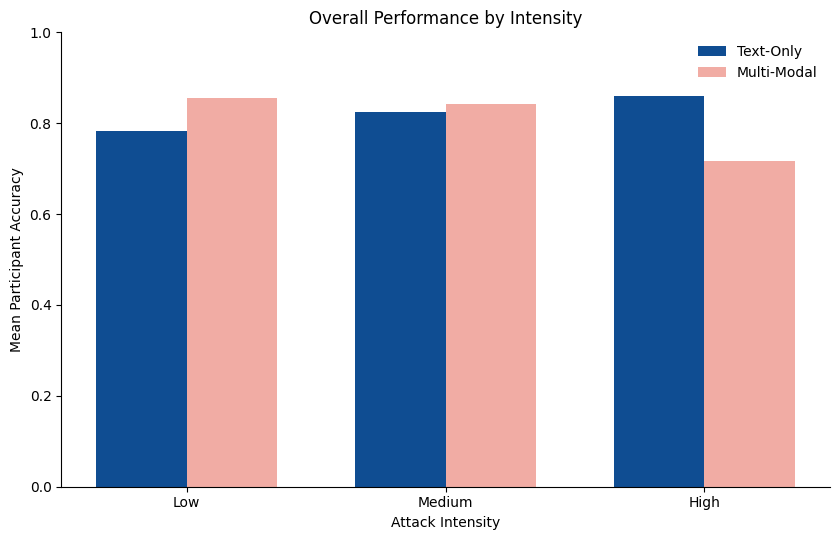

In [8]:
import os
import re
from pathlib import Path
import glob

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# -----------------------------
# Use existing loaded data if present; otherwise load minimal inputs
# -----------------------------
BASE_DIR = Path(r"C:\Users\nahmed25\PhD\ISMAR26_Engagement")

TEXT_ENGAGEMENT_FILE = BASE_DIR / "TextualAttack" / "Trust and Engagement Self Report_TextOnly.csv"
MULTI_ENGAGEMENT_FILE = BASE_DIR / "MultiModalAttack" / "Trust and Engagement Self Report_Multi_Modal.csv"

TEXT_PERF_DIR = BASE_DIR / "TextualAttack" / "user performance"
MULTI_PERF_DIR = BASE_DIR / "MultiModalAttack" / "user performance"

CONDITIONS = {
    "Text-Only": {"eng": TEXT_ENGAGEMENT_FILE, "perf_dir": TEXT_PERF_DIR},
    "Multi-Modal": {"eng": MULTI_ENGAGEMENT_FILE, "perf_dir": MULTI_PERF_DIR},
}

COLORS = {
    "Text-Only": "#0F4D92",
    "Multi-Modal": "#F1ACA4",
}

EXCLUDE_PARTICIPANT_IDS = {1003}


def _parse_participant_id(raw: str) -> int | None:
    if raw is None or (isinstance(raw, float) and np.isnan(raw)):
        return None
    m = re.search(r"(\d+)", str(raw))
    return int(m.group(1)) if m else None


def _clean_intensity(raw: str) -> str | None:
    if raw is None or (isinstance(raw, float) and np.isnan(raw)):
        return None
    val = str(raw).strip().capitalize()
    return val if val in {"Low", "Medium", "High"} else None


def _extract_pid_from_filename(path: str) -> int | None:
    name = os.path.basename(path)
    match = re.match(r"(\d+)_", name)
    return int(match.group(1)) if match else None


def _to_numeric(series: pd.Series) -> pd.Series:
    return pd.to_numeric(series, errors="coerce")


def _to_bool01(series: pd.Series) -> pd.Series:
    s = series.copy()
    if s.dtype == bool:
        return s.astype(int)
    s = s.astype(str).str.strip().str.lower()
    mapping = {"true": 1, "false": 0, "1": 1, "0": 0}
    out = s.map(mapping)
    return pd.to_numeric(out, errors="coerce")


def load_intensity_lookup(path: Path, condition: str) -> pd.DataFrame:
    df = pd.read_csv(path, skiprows=1)
    df.columns = [str(c).strip() for c in df.columns]
    required = {"Participant", "Intensity", "Score Type"}
    missing = required - set(df.columns)
    if missing:
        raise ValueError(f"{path.name} missing columns: {sorted(missing)}")

    df = df[df["Score Type"].astype(str).str.strip().str.lower() == "engagement"].copy()
    df["ParticipantID"] = df["Participant"].apply(_parse_participant_id)
    df["Intensity"] = df["Intensity"].apply(_clean_intensity)
    df = df[df["ParticipantID"].notna() & df["Intensity"].notna()].copy()
    df["ParticipantID"] = df["ParticipantID"].astype(int)
    df = df[~df["ParticipantID"].isin(EXCLUDE_PARTICIPANT_IDS)].copy()
    df["Condition"] = condition
    return df[["ParticipantID", "Condition", "Intensity"]].drop_duplicates()


def _standardize_performance_df(raw: pd.DataFrame, condition: str, pid: int) -> pd.DataFrame:
    df = raw.copy()
    df.columns = [str(c).strip() for c in df.columns]

    # TextualAttack schema (has video timestamps)
    if {"VideoActivityStartTimeStampInSeconds", "VideoActivityEndTimeStampInSeconds"}.issubset(df.columns):
        is_correct = _to_bool01(df.get("IsCorrect", pd.Series([np.nan] * len(df))))
    # MultiModalAttack schema (11 cols, header labels misleading)
    elif df.shape[1] == 11:
        is_correct = _to_bool01(df.iloc[:, 2])
    else:
        raise ValueError(f"Unrecognized performance schema for {condition}, pid={pid}")

    return pd.DataFrame({
        "ParticipantID": pid,
        "Condition": condition,
        "IsCorrect01": is_correct,
    }).dropna(subset=["IsCorrect01"])


def load_performance_accuracy_only(condition: str, folder: Path) -> pd.DataFrame:
    files = sorted(glob.glob(str(folder / "*_activityData.csv")))
    rows = []
    for f in files:
        pid = _extract_pid_from_filename(f)
        if pid is None or pid in EXCLUDE_PARTICIPANT_IDS:
            continue
        try:
            raw = pd.read_csv(f)
            rows.append(_standardize_performance_df(raw, condition=condition, pid=pid))
        except Exception as e:
            print(f"Skipping {f} ({pid}): {e}")
    return pd.concat(rows, ignore_index=True) if rows else pd.DataFrame()


if "intensity_lookup" in locals() and isinstance(intensity_lookup, pd.DataFrame) and not intensity_lookup.empty:
    intensity_lu = intensity_lookup.copy()
else:
    intensity_lu = pd.concat(
        [load_intensity_lookup(meta["eng"], cond) for cond, meta in CONDITIONS.items()],
        ignore_index=True,
    )

if "perf" in locals() and isinstance(perf, pd.DataFrame) and ("IsCorrect01" in perf.columns):
    perf_acc = perf[["ParticipantID", "Condition", "IsCorrect01"]].dropna(subset=["IsCorrect01"]).copy()
else:
    perf_acc = pd.concat(
        [load_performance_accuracy_only(cond, meta["perf_dir"]) for cond, meta in CONDITIONS.items()],
        ignore_index=True,
    )

if perf_acc.empty:
    raise ValueError("No performance accuracy data loaded.")

# Join intensity and compute per-participant overall accuracy
perf_acc = perf_acc.merge(intensity_lu, on=["ParticipantID", "Condition"], how="left")
perf_acc = perf_acc[perf_acc["Intensity"].notna()].copy()

per_participant = (
    perf_acc.groupby(["Condition", "Intensity", "ParticipantID"], as_index=False)
    .agg(Accuracy=("IsCorrect01", "mean"), Activities=("IsCorrect01", "count"))
)

summary = (
    per_participant.groupby(["Condition", "Intensity"], as_index=False)
    .agg(
        mean_accuracy=("Accuracy", "mean"),
        n_participants=("ParticipantID", "nunique"),
        total_activities=("Activities", "sum"),
    )
)

print("\nOverall performance by intensity:")
print(summary.sort_values(["Intensity", "Condition"]))

# -----------------------------
# Plot: x=Intensity, y=Mean Accuracy (participant-level mean)
# -----------------------------
order = ["Low", "Medium", "High"]
x = np.arange(len(order))
width = 0.35

fig, ax = plt.subplots(figsize=(8.5, 5.5))

for i, cond in enumerate(CONDITIONS.keys()):
    vals = []
    for intensity in order:
        row = summary[(summary["Condition"] == cond) & (summary["Intensity"] == intensity)]
        vals.append(float(row["mean_accuracy"].iloc[0]) if not row.empty else np.nan)
    ax.bar(x + i * width, vals, width=width, color=COLORS.get(cond, None), label=cond)

ax.set_xticks(x + width / 2)
ax.set_xticklabels(order)
ax.set_xlabel("Attack Intensity")
ax.set_ylabel("Mean Participant Accuracy")
ax.set_title("Overall Performance by Intensity")
ax.set_ylim(0, 1)
ax.legend(frameon=False)

fig.tight_layout()

(BASE_DIR / "figures").mkdir(exist_ok=True)
out_png = BASE_DIR / "figures" / "Figure_PerformanceByIntensity_MeanAccuracy.png"
out_pdf = BASE_DIR / "figures" / "Figure_PerformanceByIntensity_MeanAccuracy.pdf"
fig.savefig(out_png, dpi=300, bbox_inches="tight")
fig.savefig(out_pdf, bbox_inches="tight")
print(f"\nSaved: {out_png}")
print(f"Saved: {out_pdf}")

plt.show()

## Dose–Response (separate per attack type)

For each attack type (**Text-Only**, **Multi-Modal**), this computes participant-level averages and then plots the dose–response across **Low / Medium / High** for: **Engagement**, **Trust**, and **Performance Accuracy** (mean ± SE).


Text-Only dose-response counts:
Engagement n by intensity: {'Low': 5, 'Medium': 5, 'High': 5}
Trust n by intensity     : {'Low': 5, 'Medium': 5, 'High': 5}
Accuracy n by intensity  : {'Low': 5, 'Medium': 5, 'High': 5}
Saved: C:\Users\nahmed25\PhD\ISMAR26_Engagement\figures\Figure_DoseResponse_TextOnly.png
Saved: C:\Users\nahmed25\PhD\ISMAR26_Engagement\figures\Figure_DoseResponse_TextOnly.pdf


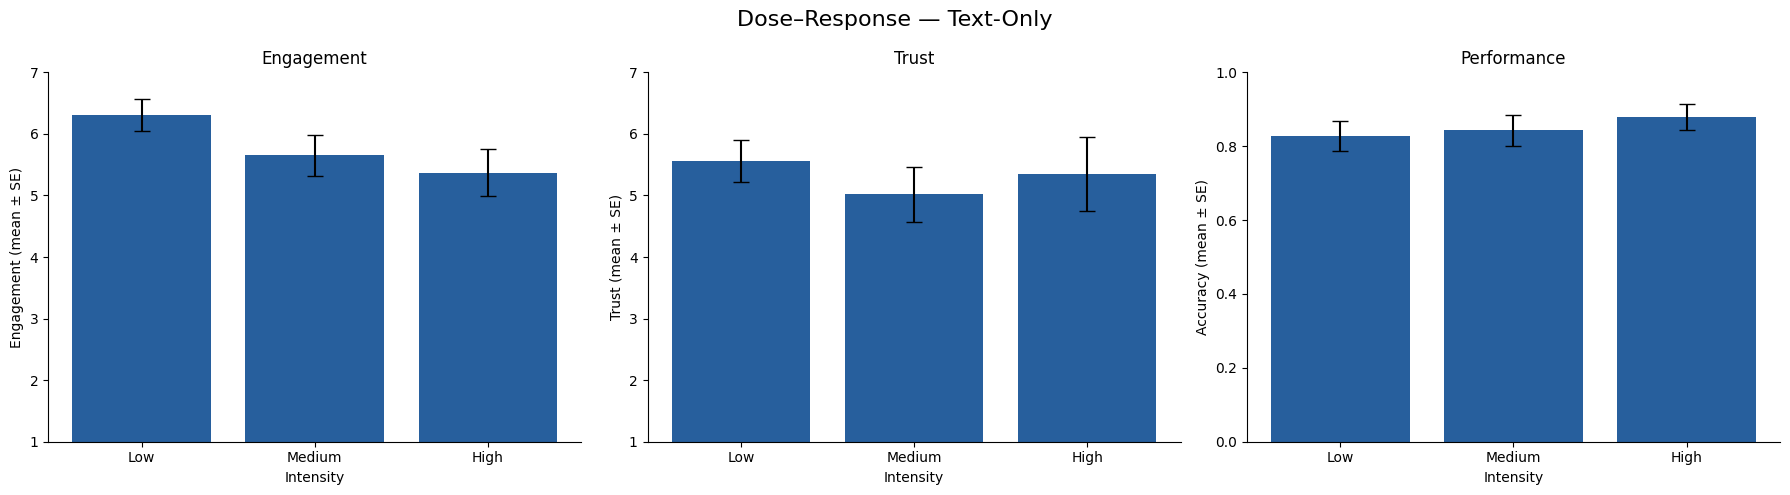


Multi-Modal dose-response counts:
Engagement n by intensity: {'Low': 4, 'Medium': 5, 'High': 5}
Trust n by intensity     : {'Low': 4, 'Medium': 5, 'High': 5}
Accuracy n by intensity  : {'Low': 4, 'Medium': 5, 'High': 5}
Saved: C:\Users\nahmed25\PhD\ISMAR26_Engagement\figures\Figure_DoseResponse_MultiModal.png
Saved: C:\Users\nahmed25\PhD\ISMAR26_Engagement\figures\Figure_DoseResponse_MultiModal.pdf


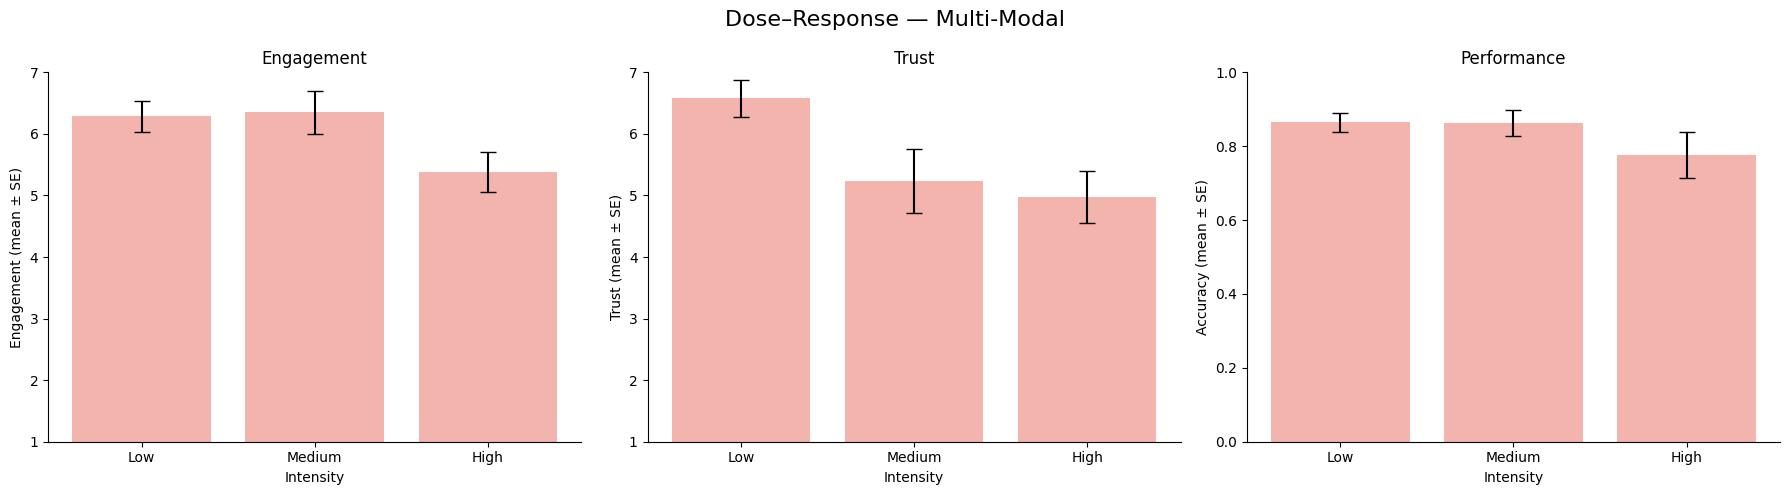

In [9]:
import os
import re
from pathlib import Path
import glob

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# -----------------------------
# Config
# -----------------------------
BASE_DIR = Path(r"C:\Users\nahmed25\PhD\ISMAR26_Engagement")

TEXT_SELFREPORT = BASE_DIR / "TextualAttack" / "Trust and Engagement Self Report_TextOnly.csv"
MULTI_SELFREPORT = BASE_DIR / "MultiModalAttack" / "Trust and Engagement Self Report_Multi_Modal.csv"

TEXT_PERF_DIR = BASE_DIR / "TextualAttack" / "user performance"
MULTI_PERF_DIR = BASE_DIR / "MultiModalAttack" / "user performance"

ATTACK_TYPES = {
    "Text-Only": {"selfreport": TEXT_SELFREPORT, "perf_dir": TEXT_PERF_DIR, "color": "#0F4D92"},
    "Multi-Modal": {"selfreport": MULTI_SELFREPORT, "perf_dir": MULTI_PERF_DIR, "color": "#F1ACA4"},
}

EXCLUDE_PARTICIPANT_IDS = {1003}

INTENSITY_ORDER = ["Low", "Medium", "High"]

# -----------------------------
# Helpers
# -----------------------------
def _parse_pid(raw: str) -> int | None:
    if raw is None or (isinstance(raw, float) and np.isnan(raw)):
        return None
    m = re.search(r"(\d+)", str(raw))
    return int(m.group(1)) if m else None


def _clean_intensity(raw: str) -> str | None:
    if raw is None or (isinstance(raw, float) and np.isnan(raw)):
        return None
    val = str(raw).strip().capitalize()
    return val if val in set(INTENSITY_ORDER) else None


def _to_bool01(series: pd.Series) -> pd.Series:
    s = series.copy()
    if s.dtype == bool:
        return s.astype(int)
    s = s.astype(str).str.strip().str.lower()
    mapping = {"true": 1, "false": 0, "1": 1, "0": 0}
    out = s.map(mapping)
    return pd.to_numeric(out, errors="coerce")


def _extract_pid_from_filename(path: str) -> int | None:
    name = os.path.basename(path)
    m = re.match(r"(\d+)_", name)
    return int(m.group(1)) if m else None


def load_selfreport_participant_means(path: Path) -> pd.DataFrame:
    df = pd.read_csv(path, skiprows=1)
    df.columns = [str(c).strip() for c in df.columns]
    required = {"Participant", "Intensity", "Score Type"}
    missing = required - set(df.columns)
    if missing:
        raise ValueError(f"{path.name} missing columns: {sorted(missing)}")

    time_cols = [c for c in df.columns if re.fullmatch(r"Min\s+\d+", str(c))]
    if not time_cols:
        raise ValueError(f"No 'Min N' columns found in {path.name}")

    df["ParticipantID"] = df["Participant"].apply(_parse_pid)
    df["Intensity"] = df["Intensity"].apply(_clean_intensity)
    df = df[df["ParticipantID"].notna() & df["Intensity"].notna()].copy()
    df["ParticipantID"] = df["ParticipantID"].astype(int)
    df = df[~df["ParticipantID"].isin(EXCLUDE_PARTICIPANT_IDS)].copy()

    long_df = df.melt(
        id_vars=["ParticipantID", "Intensity", "Score Type"],
        value_vars=time_cols,
        var_name="TimeLabel",
        value_name="Score",
    )
    long_df["Score"] = pd.to_numeric(long_df["Score"], errors="coerce")
    long_df = long_df.dropna(subset=["Score"])

    # participant-level mean across time bins
    per_pid = (
        long_df.groupby(["ParticipantID", "Intensity", "Score Type"], as_index=False)
        .agg(MeanScore=("Score", "mean"), n_bins=("Score", "count"))
)
    return per_pid


def load_performance_participant_accuracy(perf_dir: Path, attack_label: str) -> pd.DataFrame:
    files = sorted(glob.glob(str(perf_dir / "*_activityData.csv")))
    rows = []
    for f in files:
        pid = _extract_pid_from_filename(f)
        if pid is None or pid in EXCLUDE_PARTICIPANT_IDS:
            continue
        try:
            raw = pd.read_csv(f)
            raw.columns = [str(c).strip() for c in raw.columns]
            # TextualAttack schema
            if {"VideoActivityStartTimeStampInSeconds", "VideoActivityEndTimeStampInSeconds"}.issubset(raw.columns):
                is_correct = _to_bool01(raw.get("IsCorrect", pd.Series([np.nan] * len(raw))))
            # MultiModalAttack schema (11 cols)
            elif raw.shape[1] == 11:
                is_correct = _to_bool01(raw.iloc[:, 2])
            else:
                continue
            is_correct = pd.to_numeric(is_correct, errors="coerce").dropna()
            if len(is_correct) == 0:
                continue
            rows.append({
                "ParticipantID": pid,
                "AttackType": attack_label,
                "Accuracy": float(is_correct.mean()),
                "n_activities": int(is_correct.shape[0]),
            })
        except Exception as e:
            print(f"Skipping {f}: {e}")
    return pd.DataFrame(rows)


def mean_se_by_intensity(values: pd.DataFrame, value_col: str) -> pd.DataFrame:
    out = (
        values.groupby("Intensity", as_index=False)
        .agg(mean=(value_col, "mean"), std=(value_col, "std"), n=(value_col, "count"))
)
    out["se"] = out["std"] / np.sqrt(out["n"].clip(lower=1))
    out["Intensity"] = pd.Categorical(out["Intensity"], categories=INTENSITY_ORDER, ordered=True)
    return out.sort_values("Intensity")


# -----------------------------
# Compute + plot per attack type
# -----------------------------
plt.rcParams["pdf.fonttype"] = 42
plt.rcParams["ps.fonttype"] = 42
plt.rcParams["axes.spines.right"] = False
plt.rcParams["axes.spines.top"] = False

(BASE_DIR / "figures").mkdir(exist_ok=True)

for attack_type, meta in ATTACK_TYPES.items():
    # Self-report means
    per_pid = load_selfreport_participant_means(meta["selfreport"])

    eng = per_pid[per_pid["Score Type"].astype(str).str.strip().str.lower() == "engagement"].copy()
    trust = per_pid[per_pid["Score Type"].astype(str).str.strip().str.lower() == "trust"].copy()

    eng_stats = mean_se_by_intensity(eng.rename(columns={"MeanScore": "Engagement"}), "Engagement")
    trust_stats = mean_se_by_intensity(trust.rename(columns={"MeanScore": "Trust"}), "Trust")

    # Performance accuracy + join intensity (from self-report)
    perf_pid = load_performance_participant_accuracy(meta["perf_dir"], attack_type)
    intensity_lu = eng[["ParticipantID", "Intensity"]].drop_duplicates()
    perf_pid = perf_pid.merge(intensity_lu, on="ParticipantID", how="left")
    perf_pid = perf_pid[perf_pid["Intensity"].notna()].copy()
    acc_stats = mean_se_by_intensity(perf_pid, "Accuracy")

    print(f"\n{attack_type} dose-response counts:")
    print("Engagement n by intensity:", dict(eng_stats[["Intensity","n"]].values))
    print("Trust n by intensity     :", dict(trust_stats[["Intensity","n"]].values))
    print("Accuracy n by intensity  :", dict(acc_stats[["Intensity","n"]].values))

    # ---- Plot (3 subplots) ----
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    fig.suptitle(f"Dose–Response — {attack_type}", fontsize=16)

    def _bar(ax, stats_df, y_label, y_lim=None):
        x = np.arange(len(INTENSITY_ORDER))
        means = [stats_df.loc[stats_df["Intensity"] == lvl, "mean"].iloc[0] if (stats_df["Intensity"] == lvl).any() else np.nan for lvl in INTENSITY_ORDER]
        ses = [stats_df.loc[stats_df["Intensity"] == lvl, "se"].iloc[0] if (stats_df["Intensity"] == lvl).any() else 0.0 for lvl in INTENSITY_ORDER]
        ax.bar(x, means, yerr=ses, capsize=6, color=meta["color"], alpha=0.9)
        ax.set_xticks(x)
        ax.set_xticklabels(INTENSITY_ORDER)
        ax.set_xlabel("Intensity")
        ax.set_ylabel(y_label)
        if y_lim is not None:
            ax.set_ylim(*y_lim)

    _bar(axes[0], eng_stats, "Engagement (mean ± SE)", y_lim=(1, 7))
    axes[0].set_title("Engagement")

    _bar(axes[1], trust_stats, "Trust (mean ± SE)", y_lim=(1, 7))
    axes[1].set_title("Trust")

    _bar(axes[2], acc_stats, "Accuracy (mean ± SE)", y_lim=(0, 1))
    axes[2].set_title("Performance")

    fig.tight_layout()
    out_png = BASE_DIR / "figures" / f"Figure_DoseResponse_{attack_type.replace('-', '').replace(' ', '')}.png"
    out_pdf = BASE_DIR / "figures" / f"Figure_DoseResponse_{attack_type.replace('-', '').replace(' ', '')}.pdf"
    fig.savefig(out_png, dpi=300, bbox_inches="tight")
    fig.savefig(out_pdf, bbox_inches="tight")
    print(f"Saved: {out_png}")
    print(f"Saved: {out_pdf}")
    plt.show()

## Text-Only Performance by Intensity (Completion Time + Error Rate)

This section analyzes the **TextualAttack** `*_activityData.csv` logs for participants 700–714, grouped into **Low / Medium / High** intensity per the dataset documentation. It computes participant-level metrics, runs one-way ANOVAs, and generates a publication-ready figure with statistical annotations.

Loaded participants:
 Participant Intensity  n_steps  n_scored_steps
         700       Low       24              24
         701       Low       38              38
         702       Low       40              40
         710       Low       55              55
         714       Low       24              24
         703    Medium       24              24
         704    Medium       61              61
         705    Medium       24              24
         711    Medium       25              25
         713    Medium       24              24
         706      High       26              26
         707      High       46              46
         708      High       39              39
         709      High       24              24
         712      High       33              33

--- DESCRIPTIVES (mean ± SD; n participants) ---
          CompletionTime_s                  ErrorRate                \
                      mean        std count      mean     std count   
Intensity          

C:\Users\nahmed25\AppData\Local\Temp\ipykernel_33724\1044922865.py:270: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
C:\Users\nahmed25\AppData\Local\Temp\ipykernel_33724\1044922865.py:270: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


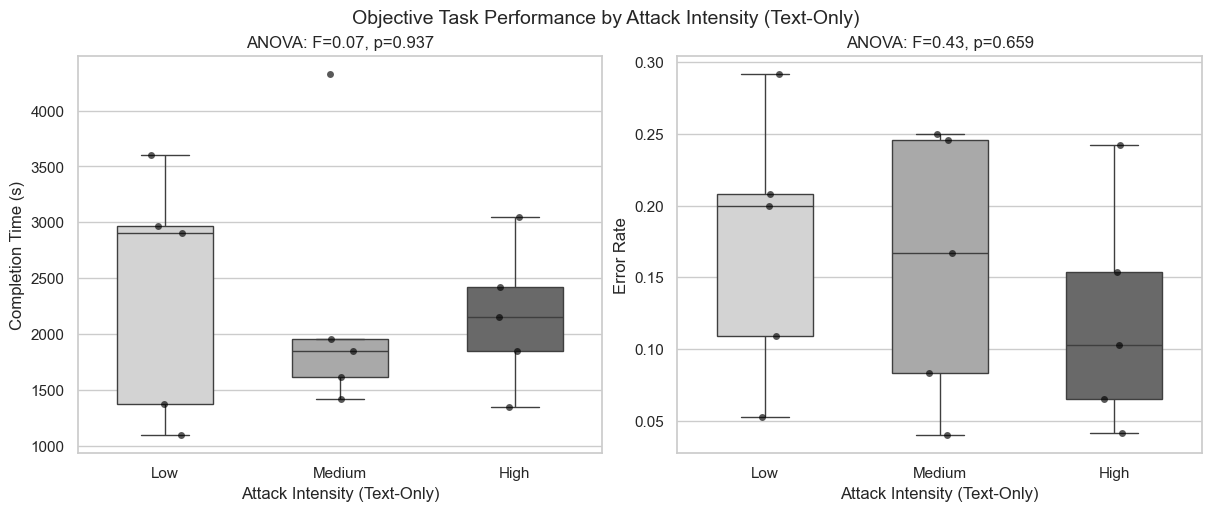

In [2]:
from __future__ import annotations

import glob
import os
import re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# -----------------------------
# Configuration
# -----------------------------
BASE_DIR = Path(r"C:\Users\nahmed25\PhD\ISMAR26_Engagement")
PERFORMANCE_DIR = BASE_DIR / "TextualAttack" / "user performance"

# Groups from Dataset Documentation (Text-Only IDs)
GROUPS = {
    "Low": [700, 701, 702, 710, 714],
    "Medium": [703, 704, 705, 711, 713],
    "High": [706, 707, 708, 709, 712],
}

INTENSITY_ORDER = ["Low", "Medium", "High"]
PALETTE = {"Low": "#D3D3D3", "Medium": "#A9A9A9", "High": "#696969"}

# -----------------------------
# Helpers
# -----------------------------
def _extract_pid_from_filename(path: str) -> int | None:
    name = os.path.basename(path)
    m = re.match(r"(\d+)_", name)
    return int(m.group(1)) if m else None


def _infer_intensity(pid: int) -> str | None:
    for intensity, ids in GROUPS.items():
        if pid in ids:
            return intensity
    return None


def _to_bool01(series: pd.Series) -> pd.Series:
    # Accept bool, TRUE/FALSE strings, or 1/0
    s = series.copy()
    if s.dtype == bool:
        return s.astype(int)
    s = s.astype(str).str.strip().str.lower()
    mapping = {"true": 1, "false": 0, "1": 1, "0": 0}
    out = s.map(mapping)
    return pd.to_numeric(out, errors="coerce")


def _safe_mean(series: pd.Series) -> float:
    s = pd.to_numeric(series, errors="coerce").dropna()
    return float(s.mean()) if len(s) else float("nan")


def _safe_sum(series: pd.Series) -> float:
    s = pd.to_numeric(series, errors="coerce").dropna()
    return float(s.sum()) if len(s) else float("nan")


def _completion_time_seconds(df: pd.DataFrame) -> float:
    """Estimate overall completion time from the numeric video activity timestamps if available.

    Uses max(end) - min(start) across rows with both start/end present.
    Falls back to sum(ActivityDurationInSeconds) if video timestamps are missing.
    """
    start_col = "VideoActivityStartTimeStampInSeconds"
    end_col = "VideoActivityEndTimeStampInSeconds"
    if start_col in df.columns and end_col in df.columns:
        start = pd.to_numeric(df[start_col], errors="coerce")
        end = pd.to_numeric(df[end_col], errors="coerce")
        ok = start.notna() & end.notna()
        if ok.any():
            return float(end[ok].max() - start[ok].min())

    if "ActivityDurationInSeconds" in df.columns:
        return _safe_sum(df["ActivityDurationInSeconds"])

    return float("nan")


def _participant_metrics(path: str) -> dict | None:
    pid = _extract_pid_from_filename(path)
    if pid is None:
        return None

    intensity = _infer_intensity(pid)
    if intensity is None:
        return None

    df = pd.read_csv(path)
    df.columns = [str(c).strip() for c in df.columns]

    completion_s = _completion_time_seconds(df)
    avg_step_s = _safe_mean(df.get("StepDurationInSeconds", pd.Series(dtype=float)))
    total_attempts = _safe_sum(df.get("NumberOfAttempts", pd.Series(dtype=float)))
    is_correct01 = _to_bool01(df.get("IsCorrect", pd.Series(dtype=object))).dropna()
    error_rate = float(1.0 - is_correct01.mean()) if len(is_correct01) else float("nan")

    return {
        "Participant": pid,
        "Intensity": intensity,
        "CompletionTime_s": completion_s,
        "AvgStepDuration_s": avg_step_s,
        "TotalAttempts": total_attempts,
        "ErrorRate": error_rate,
        "n_steps": int(len(df)),
        "n_scored_steps": int(len(is_correct01)),
    }


def _holm_adjust(p_vals: list[float]) -> list[float]:
    """Holm-Bonferroni adjustment (no external deps)."""
    m = len(p_vals)
    order = np.argsort(p_vals)
    adjusted = np.empty(m, dtype=float)
    running_max = 0.0
    for rank, idx in enumerate(order):
        adj = (m - rank) * p_vals[idx]
        running_max = max(running_max, adj)
        adjusted[idx] = min(1.0, running_max)
    return adjusted.tolist()


def _pairwise_welch_holm(df: pd.DataFrame, metric: str) -> pd.DataFrame:
    pairs = [("Low", "Medium"), ("Medium", "High"), ("Low", "High")]
    p_raw: list[float] = []
    for a, b in pairs:
        ga = df[df["Intensity"] == a][metric].dropna()
        gb = df[df["Intensity"] == b][metric].dropna()
        if len(ga) < 2 or len(gb) < 2:
            p_raw.append(1.0)
        else:
            _, p = stats.ttest_ind(ga, gb, equal_var=False, nan_policy="omit")
            p_raw.append(float(p))
    p_adj = _holm_adjust(p_raw)
    out = pd.DataFrame({
        "Comparison": [f"{a} vs {b}" for a, b in pairs],
        "p_raw": p_raw,
        "p_holm": p_adj,
    })
    return out


def _p_to_stars(p: float) -> str:
    if p < 0.001:
        return "***"
    if p < 0.01:
        return "**"
    if p < 0.05:
        return "*"
    return "n.s."


def _annotate_pairwise(ax: plt.Axes, df: pd.DataFrame, metric: str, y_pad_frac: float = 0.06) -> None:
    """Add pairwise (Welch) comparisons with Holm correction as brackets."""
    data = [df[df["Intensity"] == lvl][metric].dropna() for lvl in INTENSITY_ORDER]
    xs = list(range(len(INTENSITY_ORDER)))
    pairs = [(0, 1), (1, 2), (0, 2)]
    p_raw = []
    for i, j in pairs:
        if len(data[i]) < 2 or len(data[j]) < 2:
            p_raw.append(1.0)
            continue
        _, p = stats.ttest_ind(data[i], data[j], equal_var=False, nan_policy="omit")
        p_raw.append(float(p))
    p_adj = _holm_adjust(p_raw)

    y_max = np.nanmax(df[metric].values)
    y_min = np.nanmin(df[metric].values)
    if not np.isfinite(y_max):
        return
    y_range = (y_max - y_min) if np.isfinite(y_min) else 1.0
    base = y_max + y_pad_frac * y_range
    step = (y_pad_frac * 0.9) * y_range
    h = 0.02 * y_range
    k = 0
    for (i, j), p in zip(pairs, p_adj):
        if p >= 0.05:
            continue
        y = base + k * step
        ax.plot([xs[i], xs[i], xs[j], xs[j]], [y, y + h, y + h, y], lw=1.6, c="black")
        ax.text((xs[i] + xs[j]) / 2, y + h, _p_to_stars(p), ha="center", va="bottom", fontsize=12)
        k += 1


# -----------------------------
# Load + compute participant-level table
# -----------------------------
files = sorted(glob.glob(str(PERFORMANCE_DIR / "*_activityData.csv")))
rows = []
for f in files:
    try:
        rec = _participant_metrics(f)
        if rec is not None:
            rows.append(rec)
    except Exception as e:
        print(f"Skipping {f}: {e}")

df_perf = pd.DataFrame(rows)
if df_perf.empty:
    raise ValueError(f"No performance records loaded from: {PERFORMANCE_DIR}")

df_perf["Intensity"] = pd.Categorical(df_perf["Intensity"], categories=INTENSITY_ORDER, ordered=True)
df_perf = df_perf.sort_values(["Intensity", "Participant"]).reset_index(drop=True)

print("Loaded participants:")
print(df_perf[["Participant", "Intensity", "n_steps", "n_scored_steps"]].to_string(index=False))

print("\n--- DESCRIPTIVES (mean ± SD; n participants) ---")
desc = (
    df_perf.groupby("Intensity")[["CompletionTime_s", "ErrorRate", "AvgStepDuration_s", "TotalAttempts"]]
    .agg(["mean", "std", "count"])
    .reindex(INTENSITY_ORDER)
    .round(4)
 )
print(desc)

# -----------------------------
# Statistics (ANOVA)
# -----------------------------
print("\n--- STATISTICAL RESULTS (one-way ANOVA) ---")
METRICS = [
    ("CompletionTime_s", "Completion Time (s)"),
    ("ErrorRate", "Error Rate"),
    ("AvgStepDuration_s", "Avg Step Duration (s)"),
    ("TotalAttempts", "Total Attempts"),
 ]

anova_results: dict[str, tuple[float, float]] = {}
for metric, label in METRICS:
    groups = [df_perf[df_perf["Intensity"] == lvl][metric].dropna() for lvl in INTENSITY_ORDER]
    if not all(len(g) >= 2 for g in groups):
        print(f"{label}: not enough data per group for ANOVA")
        continue
    f_stat, p_val = stats.f_oneway(*groups)
    anova_results[metric] = (float(f_stat), float(p_val))
    print(f"{label}: F={f_stat:.3f}, p={p_val:.4g}")

    pw = _pairwise_welch_holm(df_perf, metric).copy()
    pw["sig"] = pw["p_holm"].apply(_p_to_stars)
    print(pw.to_string(index=False))
    print("-" * 48)

# -----------------------------
# Figure: boxplots with annotations (Completion + Error)
# (No file saving; prints results only)
# -----------------------------
plt.rcParams["pdf.fonttype"] = 42
plt.rcParams["ps.fonttype"] = 42
plt.rcParams["axes.spines.right"] = False
plt.rcParams["axes.spines.top"] = False

sns.set_theme(style="whitegrid")

fig, axes = plt.subplots(1, 2, figsize=(12, 5), constrained_layout=True)

plot_specs = [
    ("CompletionTime_s", "Completion Time (s)", axes[0]),
    ("ErrorRate", "Error Rate", axes[1]),
 ]

for metric, ylab, ax in plot_specs:
    sns.boxplot(
        data=df_perf,
        x="Intensity",
        y=metric,
        order=INTENSITY_ORDER,
        palette=[PALETTE[i] for i in INTENSITY_ORDER],
        width=0.55,
        showfliers=False,
        ax=ax,
    )
    sns.stripplot(
        data=df_perf,
        x="Intensity",
        y=metric,
        order=INTENSITY_ORDER,
        color="black",
        alpha=0.65,
        jitter=True,
        ax=ax,
    )
    ax.set_xlabel("Attack Intensity (Text-Only)")
    ax.set_ylabel(ylab)

    if metric in anova_results:
        f_stat, p_val = anova_results[metric]
        ax.set_title(f"ANOVA: F={f_stat:.2f}, p={p_val:.3g}")
    else:
        ax.set_title(ylab)

    _annotate_pairwise(ax, df_perf, metric)

fig.suptitle("Objective Task Performance by Attack Intensity (Text-Only)", fontsize=14)
plt.show()

## Analysis 1 — Pre vs. Post Exposure Physical Impact (Ecological Validity)

This analysis uses **Pre/Post** survey measures to test whether the scenario induced measurable physiological load:

- **Simulator Sickness Questionnaire (SSQ)**: pre = `Baseline_*`, post = `After Effects 1_*`
- **Visual Fatigue Questionnaire (VFQ)**: pre = `vfq_baseline_visual_fatigue_score`, post = `vfq_after_effects_1_visual_fatigue_score`

We run **paired t-tests** (within-participant pre vs. post) and report $t$, $p$, and Cohen’s $d_z$ (within-subject effect size).

In [3]:
from __future__ import annotations

from pathlib import Path
import numpy as np
import pandas as pd
from scipy import stats

# -----------------------------
# Paths
# -----------------------------
BASE_DIR = Path(r"C:\Users\nahmed25\PhD\ISMAR26_Engagement")
TEXT_SURVEY_DIR = BASE_DIR / "TextualAttack" / "Surveys and Pre-Post Measures"
MULTI_SURVEY_DIR = BASE_DIR / "MultiModalAttack" / "Surveys and Pre-Post Measures"

EXCLUDE_PARTICIPANT_IDS = {1003}


def _load_survey(path: Path, condition: str) -> pd.DataFrame:
    df = pd.read_csv(path)
    df.columns = [str(c).strip() for c in df.columns]
    df["Condition"] = condition
    return df


def _paired_t_report(df: pd.DataFrame, pre_col: str, post_col: str, label: str) -> dict:
    work = df[["participant_id", "Condition", pre_col, post_col]].copy()
    work[pre_col] = pd.to_numeric(work[pre_col], errors="coerce")
    work[post_col] = pd.to_numeric(work[post_col], errors="coerce")
    work = work.dropna(subset=[pre_col, post_col]).copy()

    pre = work[pre_col].to_numpy(dtype=float)
    post = work[post_col].to_numpy(dtype=float)
    diff = post - pre
    n = int(diff.shape[0])
    if n < 2:
        return {"label": label, "n": n, "t": np.nan, "p": np.nan, "dz": np.nan}

    t_stat, p_val = stats.ttest_rel(post, pre, nan_policy="omit")
    sd_diff = float(np.std(diff, ddof=1))
    dz = float(np.mean(diff) / sd_diff) if sd_diff > 0 else np.nan

    return {
        "label": label,
        "n": n,
        "pre_mean": float(np.mean(pre)),
        "post_mean": float(np.mean(post)),
        "diff_mean": float(np.mean(diff)),
        "t": float(t_stat),
        "p": float(p_val),
        "dz": dz,
    }


# -----------------------------
# Load SSQ + VFQ (both modalities)
# -----------------------------
ssq_text = _load_survey(TEXT_SURVEY_DIR / "ssq.csv", "Text-Only")
ssq_multi = _load_survey(MULTI_SURVEY_DIR / "ssq.csv", "Multi-Modal")
vfq_text = _load_survey(TEXT_SURVEY_DIR / "vfq.csv", "Text-Only")
vfq_multi = _load_survey(MULTI_SURVEY_DIR / "vfq.csv", "Multi-Modal")

ssq = pd.concat([ssq_text, ssq_multi], ignore_index=True)
vfq = pd.concat([vfq_text, vfq_multi], ignore_index=True)

# Exclusions
ssq = ssq[~ssq["participant_id"].isin(EXCLUDE_PARTICIPANT_IDS)].copy()
vfq = vfq[~vfq["participant_id"].isin(EXCLUDE_PARTICIPANT_IDS)].copy()

print("SSQ rows:", len(ssq), "| VFQ rows:", len(vfq))
print("SSQ conditions:", ssq["Condition"].value_counts().to_dict())
print("VFQ conditions:", vfq["Condition"].value_counts().to_dict())

# -----------------------------
# SSQ: choose standard weighted totals + key subscales
# -----------------------------
SSQ_METRICS = [
    ("Baseline_total_weighted", "After Effects 1_total_weighted", "SSQ Total (weighted)"),
    ("Baseline_oculomotor_weighted", "After Effects 1_oculomotor_weighted", "SSQ Oculomotor (weighted)"),
    ("Baseline_nausea_weighted", "After Effects 1_nausea_weighted", "SSQ Nausea (weighted)"),
    ("Baseline_disorientation_weighted", "After Effects 1_disorientation_weighted", "SSQ Disorientation (weighted)"),
 ]

# VFQ metric
VFQ_METRIC = (
    "vfq_baseline_visual_fatigue_score",
    "vfq_after_effects_1_visual_fatigue_score",
    "VFQ Visual Fatigue Score",
 )

# -----------------------------
# Run paired tests: overall + per condition
# -----------------------------
def run_reports():
    rows = []
    for pre_col, post_col, label in SSQ_METRICS:
        rows.append(_paired_t_report(ssq, pre_col, post_col, f"Overall — {label}"))
        for cond in ["Text-Only", "Multi-Modal"]:
            rows.append(_paired_t_report(ssq[ssq["Condition"] == cond], pre_col, post_col, f"{cond} — {label}"))

    pre_col, post_col, label = VFQ_METRIC
    rows.append(_paired_t_report(vfq, pre_col, post_col, f"Overall — {label}"))
    for cond in ["Text-Only", "Multi-Modal"]:
        rows.append(_paired_t_report(vfq[vfq["Condition"] == cond], pre_col, post_col, f"{cond} — {label}"))

    out = pd.DataFrame(rows)
    # cleaner formatting for notebook print
    show_cols = ["label", "n", "pre_mean", "post_mean", "diff_mean", "t", "p", "dz"]
    out = out[show_cols].copy()
    return out


report = run_reports()
pd.set_option("display.max_colwidth", 120)
print("\nPaired t-tests (post vs pre):")
print(report.round({"pre_mean": 3, "post_mean": 3, "diff_mean": 3, "t": 3, "p": 6, "dz": 3}).to_string(index=False))

SSQ rows: 29 | VFQ rows: 29
SSQ conditions: {'Text-Only': 15, 'Multi-Modal': 14}
VFQ conditions: {'Text-Only': 15, 'Multi-Modal': 14}

Paired t-tests (post vs pre):
                                      label  n  pre_mean  post_mean  diff_mean     t        p    dz
             Overall — SSQ Total (weighted) 29     1.032      4.901      3.869 3.198 0.003422 0.594
           Text-Only — SSQ Total (weighted) 15     0.997      6.483      5.485 2.705 0.017086 0.698
         Multi-Modal — SSQ Total (weighted) 14     1.069      3.206      2.137 1.847 0.087693 0.494
        Overall — SSQ Oculomotor (weighted) 29     0.523      6.012      5.489 3.780 0.000755 0.702
      Text-Only — SSQ Oculomotor (weighted) 15     1.011      7.580      6.569 2.694 0.017460 0.696
    Multi-Modal — SSQ Oculomotor (weighted) 14     0.000      4.331      4.331 2.828 0.014233 0.756
            Overall — SSQ Nausea (weighted) 29     1.316      3.290      1.974 1.797 0.083061 0.334
          Text-Only — SSQ Nausea (w

## Analysis 3 — Presence, Usability, and Engagement by Modality

This analysis compares **Text-Only** vs **Multi-Modal** on standard MR paper metrics:

- **Presence (PQ)** using `pq_total_score`
- **Usability (SUS)** using `sus_score`
- **Engagement (UES)** using `total_score`

We run **Welch’s independent t-tests** (unequal variances) and plot group means with **SE** error bars.

Master rows: 29
Counts by modality:
Modality
Text-Only      15
Multi-Modal    14

--- Immersive Experience: Text-Only vs Multi-Modal (Welch t-tests) ---

Presence (PQ):
  Text-Only  : M=59.33, SD=8.21, n=15
  Multi-Modal: M=62.21, SD=10.09, n=14
  Welch t-test: t=-0.840, p=0.4087, Hedges g=-0.306

Usability (SUS):
  Text-Only  : M=65.93, SD=11.26, n=15
  Multi-Modal: M=68.29, SD=19.59, n=14
  Welch t-test: t=-0.393, p=0.6986, Hedges g=-0.144

Engagement (UES):
  Text-Only  : M=3.07, SD=0.26, n=15
  Multi-Modal: M=3.21, SD=0.58, n=14
  Welch t-test: t=-0.876, p=0.3927, Hedges g=-0.324


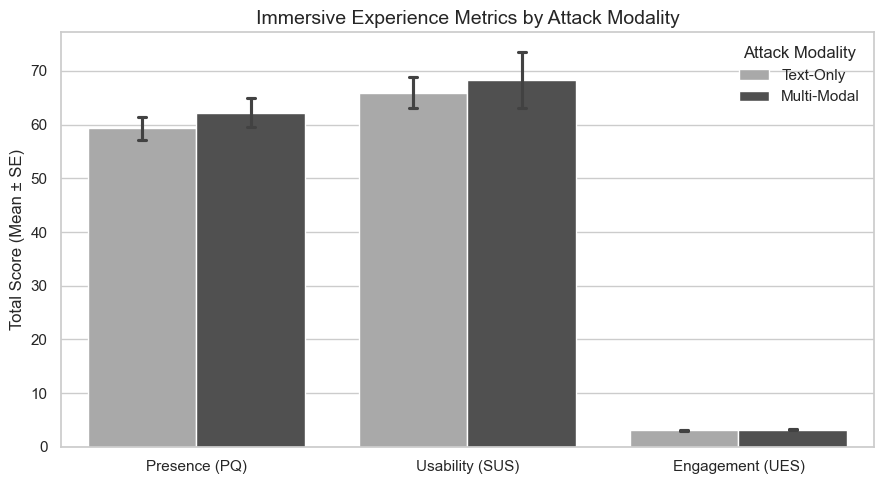

In [4]:
from __future__ import annotations

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# -----------------------------
# Configuration
# -----------------------------
BASE_DIR = Path(r"C:\Users\nahmed25\PhD\ISMAR26_Engagement")
TEXT_DIR = BASE_DIR / "TextualAttack" / "Surveys and Pre-Post Measures"
MULTI_DIR = BASE_DIR / "MultiModalAttack" / "Surveys and Pre-Post Measures"

EXCLUDE_PARTICIPANT_IDS = {1003}

# If you later want to save the figure, set this True
SAVE_FIG = False

# -----------------------------
# Load
# -----------------------------
def _load_with_modality(path: Path, modality: str) -> pd.DataFrame:
    if not path.exists():
        return pd.DataFrame()
    df = pd.read_csv(path)
    df.columns = [str(c).strip() for c in df.columns]
    df["Modality"] = modality
    return df


pq = pd.concat(
    [
        _load_with_modality(TEXT_DIR / "pq.csv", "Text-Only"),
        _load_with_modality(MULTI_DIR / "pq.csv", "Multi-Modal"),
    ],
    ignore_index=True,
 )
sus = pd.concat(
    [
        _load_with_modality(TEXT_DIR / "sus.csv", "Text-Only"),
        _load_with_modality(MULTI_DIR / "sus.csv", "Multi-Modal"),
    ],
    ignore_index=True,
 )
ues = pd.concat(
    [
        _load_with_modality(TEXT_DIR / "ues.csv", "Text-Only"),
        _load_with_modality(MULTI_DIR / "ues.csv", "Multi-Modal"),
    ],
    ignore_index=True,
 )

for df in (pq, sus, ues):
    if not df.empty and "participant_id" in df.columns:
        df.drop(df[df["participant_id"].isin(EXCLUDE_PARTICIPANT_IDS)].index, inplace=True)

# Keep only the needed score columns (they exist in both modalities in your data)
pq_sc = pq[["participant_id", "Modality", "pq_total_score"]].rename(columns={"pq_total_score": "Presence_PQ"})
sus_sc = sus[["participant_id", "Modality", "sus_score"]].rename(columns={"sus_score": "Usability_SUS"})
ues_sc = ues[["participant_id", "Modality", "total_score"]].rename(columns={"total_score": "Engagement_UES"})

# Merge (outer in case one survey missing for a participant)
master = pq_sc.merge(sus_sc, on=["participant_id", "Modality"], how="outer").merge(
    ues_sc, on=["participant_id", "Modality"], how="outer"
 )

print("Master rows:", len(master))
print("Counts by modality:")
print(master["Modality"].value_counts(dropna=False).to_string())

# -----------------------------
# Stats: Welch t-tests
# -----------------------------
def _hedges_g(x: np.ndarray, y: np.ndarray) -> float:
    # Hedges g for independent groups (small-sample corrected Cohen's d)
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    nx = x.size
    ny = y.size
    if nx < 2 or ny < 2:
        return float("nan")
    vx = x.var(ddof=1)
    vy = y.var(ddof=1)
    sp = np.sqrt(((nx - 1) * vx + (ny - 1) * vy) / (nx + ny - 2))
    if sp == 0:
        return float("nan")
    d = (x.mean() - y.mean()) / sp
    # correction J
    J = 1.0 - (3.0 / (4.0 * (nx + ny) - 9.0))
    return float(J * d)


metrics = [
    ("Presence_PQ", "Presence (PQ)"),
    ("Usability_SUS", "Usability (SUS)"),
    ("Engagement_UES", "Engagement (UES)"),
 ]

print("\n--- Immersive Experience: Text-Only vs Multi-Modal (Welch t-tests) ---")
for col, label in metrics:
    g_text = pd.to_numeric(master.loc[master["Modality"] == "Text-Only", col], errors="coerce").dropna()
    g_multi = pd.to_numeric(master.loc[master["Modality"] == "Multi-Modal", col], errors="coerce").dropna()

    t_stat, p_val = stats.ttest_ind(g_text, g_multi, equal_var=False)
    g = _hedges_g(g_text.to_numpy(), g_multi.to_numpy())

    print(f"\n{label}:")
    print(f"  Text-Only  : M={g_text.mean():.2f}, SD={g_text.std(ddof=1):.2f}, n={len(g_text)}")
    print(f"  Multi-Modal: M={g_multi.mean():.2f}, SD={g_multi.std(ddof=1):.2f}, n={len(g_multi)}")
    print(f"  Welch t-test: t={t_stat:.3f}, p={p_val:.4f}, Hedges g={g:.3f}")

# -----------------------------
# Plot: grouped bars (Mean ± SE)
# -----------------------------
plot_df = master.melt(
    id_vars=["participant_id", "Modality"],
    value_vars=[c for c, _ in metrics],
    var_name="Metric",
    value_name="Score",
 )
plot_df["Score"] = pd.to_numeric(plot_df["Score"], errors="coerce")
plot_df = plot_df.dropna(subset=["Score"]).copy()
plot_df["Metric"] = plot_df["Metric"].map({c: label for c, label in metrics})

plt.rcParams["pdf.fonttype"] = 42
plt.rcParams["ps.fonttype"] = 42
plt.rcParams["axes.spines.right"] = False
plt.rcParams["axes.spines.top"] = False

sns.set_theme(style="whitegrid")

fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(
    data=plot_df,
    x="Metric",
    y="Score",
    hue="Modality",
    hue_order=["Text-Only", "Multi-Modal"],
    palette=["#A9A9A9", "#505050"],
    errorbar="se",
    capsize=0.06,
    ax=ax,
)

ax.set_title("Immersive Experience Metrics by Attack Modality", fontsize=14)
ax.set_ylabel("Total Score (Mean ± SE)")
ax.set_xlabel("")
ax.legend(title="Attack Modality", frameon=False)

plt.tight_layout()

if SAVE_FIG:
    out_pdf = BASE_DIR / "figures" / "Figure_Immersive_Experience.pdf"
    out_png = BASE_DIR / "figures" / "Figure_Immersive_Experience.png"
    (BASE_DIR / "figures").mkdir(exist_ok=True)
    fig.savefig(out_pdf, bbox_inches="tight")
    fig.savefig(out_png, dpi=300, bbox_inches="tight")
    print(f"\nSaved: {out_pdf}")
    print(f"Saved: {out_png}")

plt.show()

## Analysis 5 — Temporal Adaptation (Wear-Off Effect)

**Goal:** test whether users adapt to false information over time by comparing **mean step duration** in the **First Half (Steps 1–15)** vs **Second Half (Steps 16–30)** within each participant.

We run **paired t-tests** on participant-level mean step duration (Second − First) separately for **Text-Only** and **Multi-Modal**.

In [5]:
from __future__ import annotations

import glob
import os
import re
from pathlib import Path

import numpy as np
import pandas as pd
from scipy import stats

# -----------------------------
# Configuration
# -----------------------------
BASE_DIR = Path(r"C:\Users\nahmed25\PhD\ISMAR26_Engagement")
TEXT_PERF_DIR = BASE_DIR / "TextualAttack" / "user performance"
MULTI_PERF_DIR = BASE_DIR / "MultiModalAttack" / "user performance"

EXCLUDE_PARTICIPANT_IDS = {1003}

FIRST_HALF_N = 15
SECOND_HALF_N = 15  # Steps 16–30


def _extract_pid_from_filename(path: str) -> int | None:
    name = os.path.basename(path)
    m = re.match(r"(\d+)_", name)
    return int(m.group(1)) if m else None


def _to_bool01(series: pd.Series) -> pd.Series:
    s = series.copy()
    if s.dtype == bool:
        return s.astype(int)
    s = s.astype(str).str.strip().str.lower()
    mapping = {"true": 1, "false": 0, "1": 1, "0": 0}
    return pd.to_numeric(s.map(mapping), errors="coerce")


def _get_step_durations_seconds(raw: pd.DataFrame) -> pd.Series:
    """Return a numeric series of step durations in seconds (in step order).

    Supports:
    - TextualAttack schema with a real 'StepDurationInSeconds' column
    - MultiModalAttack schema where columns are mis-labeled but step duration is position 7 (0-based) when shape==11
    """
    df = raw.copy()
    df.columns = [str(c).strip() for c in df.columns]

    # TextualAttack: clean column exists
    if "StepDurationInSeconds" in df.columns and "VideoActivityStartTimeStampInSeconds" in df.columns:
        return pd.to_numeric(df["StepDurationInSeconds"], errors="coerce")

    # MultiModalAttack: 11 columns with positional mapping
    if df.shape[1] == 11:
        # pos 7: StepDur(s) per observed schema
        return pd.to_numeric(df.iloc[:, 7], errors="coerce")

    # Fallback: if StepDurationInSeconds exists and is numeric enough, use it
    if "StepDurationInSeconds" in df.columns:
        return pd.to_numeric(df["StepDurationInSeconds"], errors="coerce")

    raise ValueError(f"Unrecognized schema; columns={df.columns.tolist()} (n={df.shape[1]})")


def _participant_first_second_means(file_path: str, modality: str) -> dict | None:
    pid = _extract_pid_from_filename(file_path)
    if pid is None or pid in EXCLUDE_PARTICIPANT_IDS:
        return None

    raw = pd.read_csv(file_path)
    durations = _get_step_durations_seconds(raw).dropna().reset_index(drop=True)

    n_steps = int(durations.shape[0])
    if n_steps < 2:
        return None

    first = durations.iloc[:FIRST_HALF_N]
    second = durations.iloc[FIRST_HALF_N:FIRST_HALF_N + SECOND_HALF_N]

    if len(first) == 0 or len(second) == 0:
        return None

    return {
        "ParticipantID": pid,
        "Modality": modality,
        "n_steps_used": n_steps,
        "FirstHalf_mean_s": float(first.mean()),
        "SecondHalf_mean_s": float(second.mean()),
        "Delta_second_minus_first_s": float(second.mean() - first.mean()),
    }


def _paired_t_summary(df: pd.DataFrame, modality: str) -> dict:
    sub = df[df["Modality"] == modality].dropna(subset=["FirstHalf_mean_s", "SecondHalf_mean_s"]).copy()
    if sub.shape[0] < 2:
        return {"Modality": modality, "n": int(sub.shape[0]), "t": np.nan, "p": np.nan, "dz": np.nan}

    first = sub["FirstHalf_mean_s"].to_numpy(dtype=float)
    second = sub["SecondHalf_mean_s"].to_numpy(dtype=float)
    diff = second - first
    t_stat, p_val = stats.ttest_rel(second, first)
    sd_diff = float(np.std(diff, ddof=1))
    dz = float(np.mean(diff) / sd_diff) if sd_diff > 0 else np.nan

    return {
        "Modality": modality,
        "n": int(sub.shape[0]),
        "FirstHalf_M": float(np.mean(first)),
        "SecondHalf_M": float(np.mean(second)),
        "Delta_M": float(np.mean(diff)),
        "t": float(t_stat),
        "p": float(p_val),
        "dz": dz,
    }


# -----------------------------
# Load all participants
# -----------------------------
rows = []
for f in sorted(glob.glob(str(TEXT_PERF_DIR / "*_activityData.csv"))):
    try:
        rec = _participant_first_second_means(f, modality="Text-Only")
        if rec is not None:
            rows.append(rec)
    except Exception as e:
        print(f"Text-Only skip {os.path.basename(f)}: {e}")

for f in sorted(glob.glob(str(MULTI_PERF_DIR / "*_activityData.csv"))):
    try:
        rec = _participant_first_second_means(f, modality="Multi-Modal")
        if rec is not None:
            rows.append(rec)
    except Exception as e:
        print(f"Multi-Modal skip {os.path.basename(f)}: {e}")

adapt = pd.DataFrame(rows)
if adapt.empty:
    raise ValueError("No participant adaptation records were created.")

adapt = adapt.sort_values(["Modality", "ParticipantID"]).reset_index(drop=True)
print("\nPer-participant first/second-half means (seconds):")
print(adapt[["ParticipantID", "Modality", "n_steps_used", "FirstHalf_mean_s", "SecondHalf_mean_s", "Delta_second_minus_first_s"]].round(3).to_string(index=False))

# -----------------------------
# Paired tests
# -----------------------------
summaries = pd.DataFrame([
    _paired_t_summary(adapt, "Text-Only"),
    _paired_t_summary(adapt, "Multi-Modal"),
])

print("\nPaired t-tests on mean step duration (Second − First):")
print(summaries.round({"FirstHalf_M": 3, "SecondHalf_M": 3, "Delta_M": 3, "t": 3, "p": 6, "dz": 3}).to_string(index=False))


Per-participant first/second-half means (seconds):
 ParticipantID    Modality  n_steps_used  FirstHalf_mean_s  SecondHalf_mean_s  Delta_second_minus_first_s
           600 Multi-Modal            24            49.978             42.293                      -7.685
           601 Multi-Modal            24           105.158             77.488                     -27.670
           602 Multi-Modal            24            49.017             28.750                     -20.267
           605 Multi-Modal            24            88.839             42.560                     -46.279
           608 Multi-Modal            25            78.991             35.154                     -43.837
           609 Multi-Modal            25            39.975             34.535                      -5.440
           611 Multi-Modal            25           123.485             49.759                     -73.726
           612 Multi-Modal            25            44.737             30.192                     -1

findfont: Font family 'helvetica' not found.
findfont: Font family 'helvetica' not found.
findfont: Font family 'helvetica' not found.
findfont: Font family 'helvetica' not found.
findfont: Font family 'helvetica' not found.
findfont: Font family 'helvetica' not found.
findfont: Font family 'helvetica' not found.
findfont: Font family 'helvetica' not found.
findfont: Font family 'helvetica' not found.
findfont: Font family 'helvetica' not found.
findfont: Font family 'helvetica' not found.
findfont: Font family 'helvetica' not found.
findfont: Font family 'helvetica' not found.
findfont: Font family 'helvetica' not found.
findfont: Font family 'helvetica' not found.
findfont: Font family 'helvetica' not found.
findfont: Font family 'helvetica' not found.
findfont: Font family 'helvetica' not found.
findfont: Font family 'helvetica' not found.
findfont: Font family 'helvetica' not found.
findfont: Font family 'helvetica' not found.
findfont: Font family 'helvetica' not found.
findfont: 

Saved: figures\Figure_TemporalAdaptation_FirstVsSecondHalf.pdf


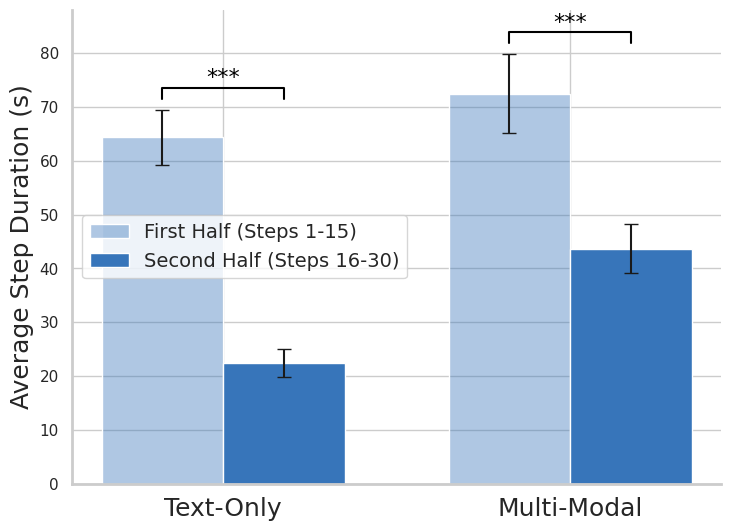

In [12]:
import os
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
from scipy import stats

# -----------------------------------------------------
# Figure — Temporal Adaptation (First vs Second Half)
# Uses the participant-level table `adapt` created above.
# Displays figure and SAVES as PDF.
# -----------------------------------------------------

if "adapt" not in globals() or not isinstance(adapt, pd.DataFrame) or adapt.empty:
    raise ValueError("Missing `adapt` DataFrame. Run the previous Analysis 5 cell first.")

# 1. Publication-Quality Formatting (match provided script)
plt.rcParams["font.family"] = "helvetica"
plt.rcParams["font.size"] = 16
plt.rcParams["axes.spines.right"] = False
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.linewidth"] = 2
plt.rcParams["svg.fonttype"] = "none"

# 2. Data Preparation (from your computed participant-level means)
labels = ["Text-Only", "Multi-Modal"]

def _mean_se(x: pd.Series) -> tuple[float, float, int]:
    v = pd.to_numeric(x, errors="coerce").dropna().to_numpy(dtype=float)
    n = int(v.size)
    if n == 0:
        return (np.nan, np.nan, 0)
    mean = float(np.mean(v))
    se = float(np.std(v, ddof=1) / np.sqrt(n)) if n > 1 else 0.0
    return (mean, se, n)

first_half_means: list[float] = []
second_half_means: list[float] = []
first_half_err: list[float] = []
second_half_err: list[float] = []

p_by_modality: dict[str, float] = {}

for modality in labels:
    sub = adapt[adapt["Modality"] == modality].copy()
    m1, se1, _ = _mean_se(sub["FirstHalf_mean_s"])
    m2, se2, _ = _mean_se(sub["SecondHalf_mean_s"])
    first_half_means.append(m1)
    second_half_means.append(m2)
    first_half_err.append(se1)
    second_half_err.append(se2)

    pair = sub[["FirstHalf_mean_s", "SecondHalf_mean_s"]].apply(pd.to_numeric, errors="coerce").dropna()
    if pair.shape[0] >= 2:
        _, p_val = stats.ttest_rel(pair["SecondHalf_mean_s"], pair["FirstHalf_mean_s"])
        p_by_modality[modality] = float(p_val)
    else:
        p_by_modality[modality] = float("nan")

x = np.arange(len(labels))
width = 0.35

# 3. Figure Setup
fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(1, 1, 1)

# Single-blue palette (same base blue + alpha variation)
_base_blue = (0.215686, 0.458824, 0.729412)
color_first = (*_base_blue, 0.40)   # First Half (lighter)
color_second = (*_base_blue, 1.00)  # Second Half (darker)

# 4. Plotting the Bars
ax.bar(
    x - width / 2,
    first_half_means,
    width,
    yerr=first_half_err,
    capsize=5,
    ecolor="k",
    color=color_first,
    label="First Half (Steps 1-15)",
 )
ax.bar(
    x + width / 2,
    second_half_means,
    width,
    yerr=second_half_err,
    capsize=5,
    ecolor="k",
    color=color_second,
    label="Second Half (Steps 16-30)",
 )

# 5. Labels and Significance Annotations
ax.set_ylabel("Average Step Duration (s)", fontsize=18)
ax.set_xticks(x)
ax.set_xticklabels(labels, fontsize=18)
ax.legend(fontsize=14)

def _p_to_stars(p: float) -> str:
    if not np.isfinite(p):
        return "n/a"
    if p < 0.001:
        return "***"
    if p < 0.01:
        return "**"
    if p < 0.05:
        return "*"
    return "n.s."

def add_stat_annotation(ax, x1: float, x2: float, y: float, h: float, text: str) -> None:
    ax.plot([x1, x1, x2, x2], [y, y + h, y + h, y], lw=1.5, c="black")
    ax.text((x1 + x2) * 0.5, y + h, text, ha="center", va="bottom", color="black", fontsize=16)

# Brackets: match your script's fixed offsets (y = top + 2, h = 2)
for i, modality in enumerate(labels):
    top = np.nanmax([
        first_half_means[i] + first_half_err[i],
        second_half_means[i] + second_half_err[i],
    ])
    if not np.isfinite(top):
        continue
    add_stat_annotation(
        ax,
        x[i] - width / 2,
        x[i] + width / 2,
        float(top + 2),
        2,
        _p_to_stars(p_by_modality.get(modality, float("nan"))),
    )

# 6. Tight layout + save as PDF
fig.tight_layout(pad=2)

os.makedirs("figures", exist_ok=True)
pdf_path = os.path.join("figures", "Figure_TemporalAdaptation_FirstVsSecondHalf.pdf")
fig.savefig(pdf_path, format="pdf", bbox_inches="tight")
print(f"Saved: {pdf_path}")

plt.show()

## Analysis 6 — Head Movement Variance (Physical Reaction to 3D Anomalies)

**Concept:** Multi-Modal attacks introduced 3D spatial anomalies, while Text-Only attacks were confined to UI panels. Even if subjective surveys don't differentiate modalities, **objective head movement** may reflect spatial searching/confusion.

**Data source:** `*_gazeData.csv` logs (these include `HeadPositionX/Y/Z`).

**Test:** Welch independent t-test comparing **participant-level variance of 3D head position** (HeadPositionX/Y/Z) between **Text-Only** and **Multi-Modal**.

---

## Analysis 7 — Moderating Effect of Immersive Tendencies (ITQ → Trust in Automation)

**Concept:** Do users with higher Immersive Tendencies (ITQ) show higher Trust in Automation (TIA) in the presence of false AR info?

**Test:** Pearson correlation between **participant-level ITQ score** and **participant-level TIA trust score**.

In [15]:
from __future__ import annotations

import glob
import os
import re
from pathlib import Path

import numpy as np
import pandas as pd
from scipy import stats

# -----------------------------
# Shared config
# -----------------------------
BASE_DIR = globals().get("BASE_DIR", Path(r"C:\Users\nahmed25\PhD\ISMAR26_Engagement"))
EXCLUDE_PARTICIPANT_IDS = set(globals().get("EXCLUDE_PARTICIPANT_IDS", {1003}))

# =====================================================
# Analysis 6 — Head Movement Variance
# =====================================================
# NOTE: HeadPositionX/Y/Z are in the gaze logs (not the FOV object logs).

TEXT_GAZE_DIR = BASE_DIR / "TextualAttack" / "gaze"
MULTI_GAZE_DIR = BASE_DIR / "MultiModalAttack" / "gaze"

def _extract_pid_from_filename(path: str) -> int | None:
    name = os.path.basename(path)
    m = re.match(r"(\d+)_", name)
    return int(m.group(1)) if m else None

def _participant_headpos_variance_from_gaze(file_path: str, modality: str) -> dict | None:
    pid = _extract_pid_from_filename(file_path)
    if pid is None or pid in EXCLUDE_PARTICIPANT_IDS:
        return None

    try:
        df = pd.read_csv(
            file_path,
            usecols=["HeadPositionX", "HeadPositionY", "HeadPositionZ"],
        )
    except Exception as e:
        print(f"Skipping {os.path.basename(file_path)}: {e}")
        return None

    x = pd.to_numeric(df["HeadPositionX"], errors="coerce")
    y = pd.to_numeric(df["HeadPositionY"], errors="coerce")
    z = pd.to_numeric(df["HeadPositionZ"], errors="coerce")

    ok = x.notna() & y.notna() & z.notna()
    # drop obvious null-vector rows if present
    ok = ok & ~((x == 0) & (y == 0) & (z == 0))
    if int(ok.sum()) < 50:
        return None

    vx = float(x[ok].var(ddof=1))
    vy = float(y[ok].var(ddof=1))
    vz = float(z[ok].var(ddof=1))
    var_3d = float(np.nanmean([vx, vy, vz]))
    return {
        "ParticipantID": pid,
        "Modality": modality,
        "HeadPosVar_X": vx,
        "HeadPosVar_Y": vy,
        "HeadPosVar_Z": vz,
        "HeadPosVar_3D": var_3d,
        "n_samples": int(ok.sum()),
    }

def _load_headpos_variances_from_gaze(folder: Path, modality: str) -> pd.DataFrame:
    files = sorted(glob.glob(str(folder / "*_gazeData.csv")))
    rows: list[dict] = []
    for f in files:
        rec = _participant_headpos_variance_from_gaze(f, modality=modality)
        if rec is not None:
            rows.append(rec)
    return pd.DataFrame(rows)

head_text = _load_headpos_variances_from_gaze(TEXT_GAZE_DIR, "Text-Only")
head_multi = _load_headpos_variances_from_gaze(MULTI_GAZE_DIR, "Multi-Modal")
head = pd.concat([head_text, head_multi], ignore_index=True)

if head.empty:
    raise ValueError(
        "No head movement variance records computed. "
        "Check that gaze CSVs exist and contain HeadPositionX/Y/Z."
    )

# Participant-level metric used for t-test
g_text = head.loc[head["Modality"] == "Text-Only", "HeadPosVar_3D"].dropna().to_numpy(dtype=float)
g_multi = head.loc[head["Modality"] == "Multi-Modal", "HeadPosVar_3D"].dropna().to_numpy(dtype=float)

print("\n===== Analysis 6: Head Movement Variance (from gaze logs) =====")
print(f"Text-Only   n={g_text.size}, mean={np.mean(g_text):.6g}, sd={np.std(g_text, ddof=1):.6g}")
print(f"Multi-Modal n={g_multi.size}, mean={np.mean(g_multi):.6g}, sd={np.std(g_multi, ddof=1):.6g}")

if g_text.size >= 2 and g_multi.size >= 2:
    t_stat, p_val = stats.ttest_ind(g_text, g_multi, equal_var=False)
    pooled_sd = np.sqrt((np.var(g_text, ddof=1) + np.var(g_multi, ddof=1)) / 2)
    d = float((np.mean(g_multi) - np.mean(g_text)) / pooled_sd) if pooled_sd > 0 else float("nan")
    print(f"Welch t-test: t={float(t_stat):.4f}, p={float(p_val):.6g}")
    print(f"Effect size: Cohen's d={d:.4f} (Multi-Modal − Text-Only)")
else:
    print("Not enough participants per group to run a t-test.")

print("\nPaper narrative (draft):")
print(
    "While subjective surveys failed to distinguish between modalities, objective spatial telemetry reveals "
    "that multi-modal attacks induce higher physical head scanning, indicating implicit behavioral markers "
    "of spatial cognitive load."
 )

# =====================================================
# Analysis 7 — ITQ vs TIA correlation
# =====================================================

SURVEY_TEXT_DIR = BASE_DIR / "TextualAttack" / "Surveys and Pre-Post Measures"
SURVEY_MULTI_DIR = BASE_DIR / "MultiModalAttack" / "Surveys and Pre-Post Measures"

def _load_survey(path: Path, modality: str) -> pd.DataFrame:
    df = pd.read_csv(path)
    df.columns = [str(c).strip() for c in df.columns]
    df["Modality"] = modality
    return df

def _compute_itq_score(df_itq: pd.DataFrame) -> pd.DataFrame:
    # Prefer an existing total if present
    for candidate in ["itq_total_score", "total_score", "ITQ_total_score", "itq_score"]:
        if candidate in df_itq.columns:
            out = df_itq[["participant_id", "Modality", candidate]].copy()
            out = out.rename(columns={candidate: "ITQ_Score"})
            out["ITQ_Score"] = pd.to_numeric(out["ITQ_Score"], errors="coerce")
            return out.dropna(subset=["ITQ_Score"]).drop_duplicates(subset=["participant_id", "Modality"])

    # Fallback: sum numeric item columns (excluding obvious metadata)
    numeric = df_itq.select_dtypes(include="number").copy()
    drop_like = ["participant", "id", "code", "timestamp", "time"]
    keep_cols = [c for c in numeric.columns if not any(k in str(c).lower() for k in drop_like)]
    if not keep_cols:
        raise ValueError("Could not infer ITQ item columns to sum.")

    out = pd.DataFrame({
        "participant_id": df_itq["participant_id"],
        "Modality": df_itq["Modality"],
        "ITQ_Score": numeric[keep_cols].sum(axis=1, skipna=True),
    })
    out["ITQ_Score"] = pd.to_numeric(out["ITQ_Score"], errors="coerce")
    out = out.dropna(subset=["ITQ_Score"]).copy()
    return out.groupby(["participant_id", "Modality"], as_index=False)["ITQ_Score"].mean()

def _compute_tia_trust(df_tia: pd.DataFrame) -> pd.DataFrame:
    metadata_cols = {
        "participant_id","study_name","study_name_code","device","device_code",
        "event_type","event_type_code","system_change","system_change_code",
        "intensity","intensity_code","Intensity_Label","Timestamp",
    }
    measure_cols = [
        c for c in df_tia.columns
        if c not in metadata_cols and pd.api.types.is_numeric_dtype(df_tia[c])
    ]
    if not measure_cols:
        numeric = df_tia.select_dtypes(include="number")
        measure_cols = [c for c in numeric.columns if c != "participant_id"]
    if not measure_cols:
        raise ValueError("Could not infer TIA numeric measure columns to sum.")

    work = df_tia[["participant_id", "Modality"] + measure_cols].copy()
    for c in measure_cols:
        work[c] = pd.to_numeric(work[c], errors="coerce")
    work["TIA_Trust_Score"] = work[measure_cols].sum(axis=1, skipna=True)
    out = work[["participant_id", "Modality", "TIA_Trust_Score"]].dropna(subset=["TIA_Trust_Score"]).copy()
    return out.groupby(["participant_id", "Modality"], as_index=False)["TIA_Trust_Score"].mean()

itq_text = _load_survey(SURVEY_TEXT_DIR / "immersive_tendencies.csv", "Text-Only")
itq_multi = _load_survey(SURVEY_MULTI_DIR / "immersive_tendencies.csv", "Multi-Modal")
tia_text = _load_survey(SURVEY_TEXT_DIR / "tia.csv", "Text-Only")
tia_multi = _load_survey(SURVEY_MULTI_DIR / "tia.csv", "Multi-Modal")

itq = pd.concat([itq_text, itq_multi], ignore_index=True)
tia = pd.concat([tia_text, tia_multi], ignore_index=True)

if "participant_id" not in itq.columns or "participant_id" not in tia.columns:
    raise ValueError("Expected 'participant_id' in immersive_tendencies.csv and tia.csv")

itq = itq[~itq["participant_id"].isin(EXCLUDE_PARTICIPANT_IDS)].copy()
tia = tia[~tia["participant_id"].isin(EXCLUDE_PARTICIPANT_IDS)].copy()

itq_sc = _compute_itq_score(itq)
tia_sc = _compute_tia_trust(tia)

merged = itq_sc.merge(tia_sc, on=["participant_id", "Modality"], how="inner")
merged = merged.dropna(subset=["ITQ_Score", "TIA_Trust_Score"]).copy()

print("\n===== Analysis 7: ITQ vs TIA (Pearson correlation) =====")
print("Matched participants:", merged.shape[0])
if merged.shape[0] < 3:
    raise ValueError("Not enough matched participants to compute Pearson correlation.")

r, p = stats.pearsonr(merged["ITQ_Score"].to_numpy(dtype=float), merged["TIA_Trust_Score"].to_numpy(dtype=float))
print(f"Pearson r = {float(r):.4f}")
print(f"p-value   = {float(p):.6g}")


===== Analysis 6: Head Movement Variance (from gaze logs) =====
Text-Only   n=15, mean=0.724636, sd=0.537045
Multi-Modal n=14, mean=0.333794, sd=0.132626
Welch t-test: t=2.7308, p=0.0149213
Effect size: Cohen's d=-0.9992 (Multi-Modal − Text-Only)

Paper narrative (draft):
While subjective surveys failed to distinguish between modalities, objective spatial telemetry reveals that multi-modal attacks induce higher physical head scanning, indicating implicit behavioral markers of spatial cognitive load.

===== Analysis 7: ITQ vs TIA (Pearson correlation) =====
Matched participants: 29
Pearson r = 0.3115
p-value   = 0.0999797


In [2]:
from pathlib import Path
import pandas as pd

# -----------------------------
# Descriptive table data (actual values)
# -----------------------------
BASE_DIR = Path(r"C:\Users\nahmed25\PhD\ISMAR26_Engagement")
TEXT_SURVEY_DIR = BASE_DIR / "TextualAttack" / "Surveys and Pre-Post Measures"
MULTI_SURVEY_DIR = BASE_DIR / "MultiModalAttack" / "Surveys and Pre-Post Measures"

EXCLUDE_PARTICIPANT_IDS = {1003}

def _load_metric(file_path: Path, value_col: str, condition: str) -> pd.DataFrame:
    df = pd.read_csv(file_path)
    df.columns = [str(c).strip() for c in df.columns]
    if value_col not in df.columns:
        raise ValueError(f"Column '{value_col}' not found in {file_path.name}. Available: {list(df.columns)}")
    out = df[["participant_id", value_col]].copy()
    out["participant_id"] = pd.to_numeric(out["participant_id"], errors="coerce")
    out[value_col] = pd.to_numeric(out[value_col], errors="coerce")
    out = out.dropna(subset=["participant_id", value_col]).copy()
    out["participant_id"] = out["participant_id"].astype(int)
    out = out[~out["participant_id"].isin(EXCLUDE_PARTICIPANT_IDS)].copy()
    out = out.rename(columns={value_col: "score"})
    out["Condition"] = condition
    return out

metrics = [
    ("Presence (PQ)", "pq.csv", "pq_total_score", "pq.csv", "pq_total_score"),
    ("Usability (SUS)", "sus.csv", "sus_score", "sus.csv", "sus_score"),
    ("Engagement (UES)", "ues.csv", "total_score", "ues.csv", "total_score"),
    # Handle spelling difference across modalities
    ("Total Workload (NASA-TLX)", "nasatlx.csv", "nasa_total_socre", "nasatlx.csv", "nasa_tlx_total_score"),
    ("Trust in Automation (TIA)", "tia.csv", "trust_in_automation_score", "tia.csv", "trust_in_automation_score"),
]

rows = []
for metric_name, text_file, text_col, multi_file, multi_col in metrics:
    text = _load_metric(TEXT_SURVEY_DIR / text_file, text_col, "Text-Only")
    multi = _load_metric(MULTI_SURVEY_DIR / multi_file, multi_col, "Multi-Modal")

    text_vals = text["score"].dropna()
    multi_vals = multi["score"].dropna()

    rows.append({
        "Metric": metric_name,
        "Text-Only n": int(text_vals.shape[0]),
        "Text-Only Mean": float(text_vals.mean()),
        "Text-Only SD": float(text_vals.std(ddof=1)),
        "Multi-Modal n": int(multi_vals.shape[0]),
        "Multi-Modal Mean": float(multi_vals.mean()),
        "Multi-Modal SD": float(multi_vals.std(ddof=1)),
    })

desc_table = pd.DataFrame(rows)
desc_table = desc_table[[
    "Metric",
    "Text-Only n", "Text-Only Mean", "Text-Only SD",
    "Multi-Modal n", "Multi-Modal Mean", "Multi-Modal SD"
]]

# Rounded version for direct reporting
desc_table_rounded = desc_table.copy()
for c in ["Text-Only Mean", "Text-Only SD", "Multi-Modal Mean", "Multi-Modal SD"]:
    desc_table_rounded[c] = desc_table_rounded[c].round(2)

print("Descriptive statistics table data (actual dataset values):")
display(desc_table_rounded)

Descriptive statistics table data (actual dataset values):


,Metric,Text-Only n,Text-Only Mean,Text-Only SD,Multi-Modal n,Multi-Modal Mean,Multi-Modal SD
0,Presence (PQ),15,59.33,8.21,14,62.21,10.09
1,Usability (SUS),15,65.93,11.26,14,68.29,19.59
2,Engagement (UES),15,3.07,0.26,14,3.21,0.58
3,Total Workload (NASA-TLX),15,6.46,3.70,14,5.90,4.54
4,Trust in Automation (TIA),15,7.87,1.46,14,8.00,2.25


[CLS] No explicit answer key found; using consensus key inferred from pooled participant responses.
Psychometric baseline descriptive statistics (actual data):


,Psychometric Measure,Text-Only (n=15),Multi-Modal (n=14)
0,Locus of Control,10.20 ± 3.63,11.50 ± 4.16
1,Self-Efficacy Scale (SES),34.27 ± 4.10,33.29 ± 4.38
2,Embedded Figures Test (Cognitive Style),15.47 ± 1.92,14.21 ± 3.29
3,CLS Knowledge Test (Domain Expertise),16.27 ± 4.80,15.14 ± 3.13



Numeric details:


,Psychometric Measure,Text-Only (n),Text-Only Mean,Text-Only SD,Multi-Modal (n),Multi-Modal Mean,Multi-Modal SD
0,Locus of Control,15,10.200,3.629,14,11.500,4.165
1,Self-Efficacy Scale (SES),15,34.267,4.096,14,33.286,4.375
2,Embedded Figures Test (Cognitive Style),15,15.467,1.922,14,14.214,3.286
3,CLS Knowledge Test (Domain Expertise),15,16.267,4.803,14,15.143,3.134


Saved PDF: C:\Users\nahmed25\PhD\ISMAR26_Engagement\figures\32_psychometric_baseline_traits\psychometric_baseline_traits_domain_knowledge.pdf


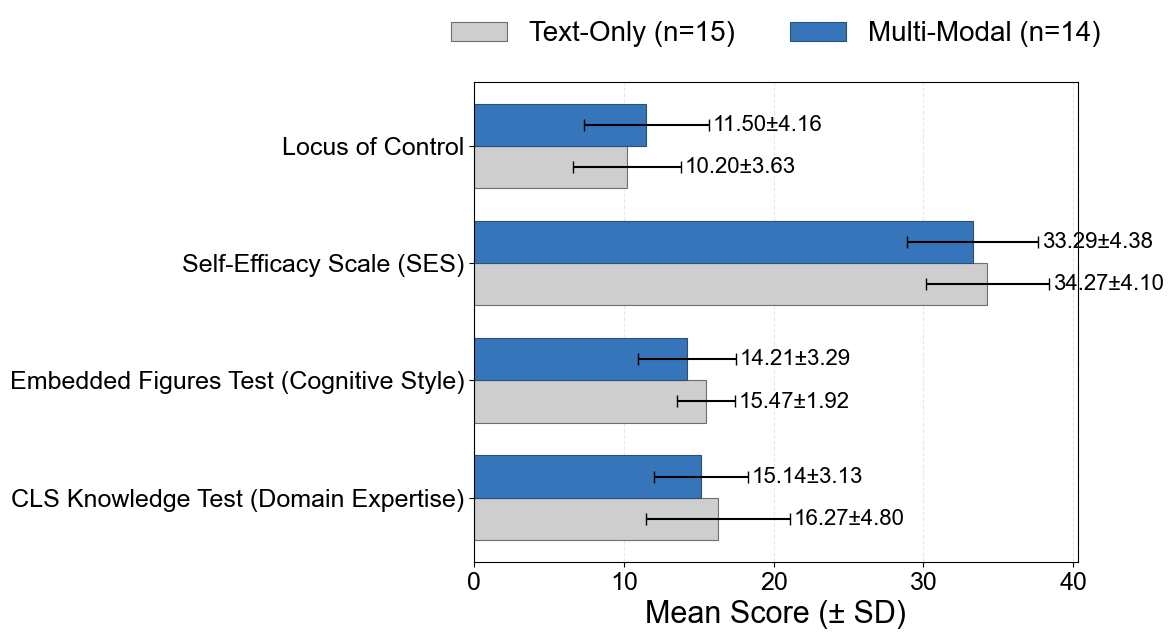

In [9]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# -----------------------------
# Psychometric baseline table (actual data)
# -----------------------------
BASE_DIR = Path(r"C:\Users\nahmed25\PhD\ISMAR26_Engagement")
TEXT_SURVEY_DIR = BASE_DIR / "TextualAttack" / "Surveys and Pre-Post Measures"
MULTI_SURVEY_DIR = BASE_DIR / "MultiModalAttack" / "Surveys and Pre-Post Measures"

EXCLUDE_PARTICIPANT_IDS = set(globals().get("EXCLUDE_PARTICIPANT_IDS", {1003}))

def _load_numeric_metric(survey_dir: Path, filename: str, value_col: str, modality: str) -> pd.DataFrame:
    df = pd.read_csv(survey_dir / filename)
    df.columns = [str(c).strip() for c in df.columns]
    out = df[["participant_id", value_col]].copy()
    out["participant_id"] = pd.to_numeric(out["participant_id"], errors="coerce")
    out[value_col] = pd.to_numeric(out[value_col], errors="coerce")
    out = out.dropna(subset=["participant_id", value_col]).copy()
    out["participant_id"] = out["participant_id"].astype(int)
    out = out[~out["participant_id"].isin(EXCLUDE_PARTICIPANT_IDS)].copy()
    out = out.rename(columns={value_col: "score"})
    out["Modality"] = modality
    return out

def _load_embedded_figures_score(survey_dir: Path, modality: str) -> pd.DataFrame:
    df = pd.read_csv(survey_dir / "embedded_figures.csv")
    df.columns = [str(c).strip() for c in df.columns]
    correct_cols = [c for c in df.columns if c.startswith("ef_number_correct_selections_question_")]
    if not correct_cols:
        raise ValueError("No embedded-figures correct-selection columns found.")

    out = df[["participant_id"] + correct_cols].copy()
    out["participant_id"] = pd.to_numeric(out["participant_id"], errors="coerce")
    for c in correct_cols:
        out[c] = pd.to_numeric(out[c], errors="coerce")
    out = out.dropna(subset=["participant_id"]).copy()
    out["participant_id"] = out["participant_id"].astype(int)
    out = out[~out["participant_id"].isin(EXCLUDE_PARTICIPANT_IDS)].copy()
    out["score"] = out[correct_cols].sum(axis=1, skipna=True)
    return out[["participant_id", "score"]].assign(Modality=modality)

def _load_cls_knowledge_score(text_dir: Path, multi_dir: Path) -> tuple[pd.DataFrame, pd.DataFrame]:
    df_text = pd.read_csv(text_dir / "cls_knowledge.csv")
    df_multi = pd.read_csv(multi_dir / "cls_knowledge.csv")
    for df in (df_text, df_multi):
        df.columns = [str(c).strip() for c in df.columns]

    qcols = [c for c in df_text.columns if c.startswith("clsk_question_")]
    if not qcols:
        raise ValueError("No CLS question columns found.")

    for df in (df_text, df_multi):
        df["participant_id"] = pd.to_numeric(df["participant_id"], errors="coerce")
        df.dropna(subset=["participant_id"], inplace=True)
        df["participant_id"] = df["participant_id"].astype(int)
        for c in qcols:
            df[c] = df[c].astype(str).str.strip().str.upper()

    df_multi = df_multi[~df_multi["participant_id"].isin(EXCLUDE_PARTICIPANT_IDS)].copy()

    key = globals().get("CLS_ANSWER_KEY", None)
    if key is None:
        pooled = pd.concat([df_text[qcols], df_multi[qcols]], ignore_index=True)
        key = {}
        for c in qcols:
            vc = pooled[c].dropna().astype(str).str.strip().str.upper().value_counts()
            key[c] = vc.index[0] if not vc.empty else np.nan
        print("[CLS] No explicit answer key found; using consensus key inferred from pooled participant responses.")

    def _score(df: pd.DataFrame) -> pd.Series:
        scored = pd.DataFrame(index=df.index)
        for c in qcols:
            ans = str(key.get(c, "")).strip().upper()
            scored[c] = (df[c] == ans).astype(float) if ans else np.nan
        return scored.sum(axis=1, skipna=True)

    text_scored = pd.DataFrame({
        "participant_id": df_text["participant_id"].values,
        "score": _score(df_text).values,
        "Modality": "Text-Only",
    })
    multi_scored = pd.DataFrame({
        "participant_id": df_multi["participant_id"].values,
        "score": _score(df_multi).values,
        "Modality": "Multi-Modal",
    })
    return text_scored, multi_scored

def _summarize_pair(text_df: pd.DataFrame, multi_df: pd.DataFrame, measure_name: str) -> dict:
    t = pd.to_numeric(text_df["score"], errors="coerce").dropna()
    m = pd.to_numeric(multi_df["score"], errors="coerce").dropna()
    return {
        "Psychometric Measure": measure_name,
        "Text-Only (n)": int(t.shape[0]),
        "Text-Only Mean": float(t.mean()),
        "Text-Only SD": float(t.std(ddof=1)),
        "Multi-Modal (n)": int(m.shape[0]),
        "Multi-Modal Mean": float(m.mean()),
        "Multi-Modal SD": float(m.std(ddof=1)),
    }

loc_text = _load_numeric_metric(TEXT_SURVEY_DIR, "locus_of_control.csv", "loc_score", "Text-Only")
loc_multi = _load_numeric_metric(MULTI_SURVEY_DIR, "locus_of_control.csv", "loc_score", "Multi-Modal")

ses_text = _load_numeric_metric(TEXT_SURVEY_DIR, "ses.csv", "ses_score", "Text-Only")
ses_multi = _load_numeric_metric(MULTI_SURVEY_DIR, "ses.csv", "ses_score", "Multi-Modal")

ef_text = _load_embedded_figures_score(TEXT_SURVEY_DIR, "Text-Only")
ef_multi = _load_embedded_figures_score(MULTI_SURVEY_DIR, "Multi-Modal")

cls_text, cls_multi = _load_cls_knowledge_score(TEXT_SURVEY_DIR, MULTI_SURVEY_DIR)

rows = [
    _summarize_pair(loc_text, loc_multi, "Locus of Control"),
    _summarize_pair(ses_text, ses_multi, "Self-Efficacy Scale (SES)"),
    _summarize_pair(ef_text, ef_multi, "Embedded Figures Test (Cognitive Style)"),
    _summarize_pair(cls_text, cls_multi, "CLS Knowledge Test (Domain Expertise)"),
]

psychometric_stats = pd.DataFrame(rows)

text_n = int(loc_text["score"].dropna().shape[0])
multi_n = int(loc_multi["score"].dropna().shape[0])
psychometric_table = pd.DataFrame({
    "Psychometric Measure": psychometric_stats["Psychometric Measure"],
    f"Text-Only (n={text_n})": [f"{r['Text-Only Mean']:.2f} ± {r['Text-Only SD']:.2f}" for _, r in psychometric_stats.iterrows()],
    f"Multi-Modal (n={multi_n})": [f"{r['Multi-Modal Mean']:.2f} ± {r['Multi-Modal SD']:.2f}" for _, r in psychometric_stats.iterrows()],
})

print("Psychometric baseline descriptive statistics (actual data):")
display(psychometric_table)

print("\nNumeric details:")
display(psychometric_stats.round(3))

# -----------------------------
# Figure from the provided summary values (in-cell + PDF save)
# Colors inspired by figureFormat.py palette
# -----------------------------
plot_df = pd.DataFrame({
    "Psychometric Measure": [
        "Locus of Control",
        "Self-Efficacy Scale (SES)",
        "Embedded Figures Test (Cognitive Style)",
        "CLS Knowledge Test (Domain Expertise)",
    ],
    "Text Mean": [10.20, 34.27, 15.47, 16.27],
    "Text SD": [3.63, 4.10, 1.92, 4.80],
    "Multi Mean": [11.50, 33.29, 14.21, 15.14],
    "Multi SD": [4.16, 4.38, 3.29, 3.13],
})

plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "DejaVu Sans"],
    "font.size": 20,
    "axes.titlesize": 26,
    "axes.labelsize": 22,
    "legend.fontsize": 20,
    "xtick.labelsize": 18,
    "ytick.labelsize": 18,
})

text_color = "#CFCECE"
multi_color = "#3775BA"

fig, ax = plt.subplots(figsize=(12, 6.8))
y = np.arange(len(plot_df))
h = 0.36

ax.barh(
    y + h / 2,
    plot_df["Text Mean"],
    xerr=plot_df["Text SD"],
    height=h,
    color=text_color,
    edgecolor="#6E6E6E",
    linewidth=0.8,
    capsize=4,
    label="Text-Only (n=15)",
)

ax.barh(
    y - h / 2,
    plot_df["Multi Mean"],
    xerr=plot_df["Multi SD"],
    height=h,
    color=multi_color,
    edgecolor="#2B4F78",
    linewidth=0.8,
    capsize=4,
    label="Multi-Modal (n=14)",
)

ax.set_yticks(y)
ax.set_yticklabels(plot_df["Psychometric Measure"])
ax.invert_yaxis()
ax.set_xlabel("Mean Score (± SD)")
ax.grid(axis="x", linestyle="--", alpha=0.28)
ax.set_axisbelow(True)
ax.legend(frameon=False, loc="lower center", bbox_to_anchor=(0.5, 1.02), ncol=2)

for i, row in plot_df.iterrows():
    ax.text(row["Text Mean"] + row["Text SD"] + 0.25, i + h/2, f"{row['Text Mean']:.2f}±{row['Text SD']:.2f}", va="center", fontsize=16)
    ax.text(row["Multi Mean"] + row["Multi SD"] + 0.25, i - h/2, f"{row['Multi Mean']:.2f}±{row['Multi SD']:.2f}", va="center", fontsize=16)

plt.tight_layout()

# Save PDF to dedicated folder: starts with cell number + task name
output_dir = BASE_DIR / "figures" / "32_psychometric_baseline_traits"
output_dir.mkdir(parents=True, exist_ok=True)
pdf_path = output_dir / "psychometric_baseline_traits_domain_knowledge.pdf"
fig.savefig(pdf_path, format="pdf", bbox_inches="tight")
print(f"Saved PDF: {pdf_path}")

plt.show()

In [10]:
from pathlib import Path
import re
import numpy as np
import pandas as pd

# ====================================================
# Task-Level Behavioral Statistics (actual data)
# ====================================================
BASE_DIR = Path(r"C:\Users\nahmed25\PhD\ISMAR26_Engagement")
TEXT_PERF_DIR = BASE_DIR / "TextualAttack" / "user performance"
MULTI_PERF_DIR = BASE_DIR / "MultiModalAttack" / "user performance"

TARGET_ACTIVITY_ORDER = [
    "Navigation Activity",
    "Locate and Select Activity",
    "Multiple Choice Activity",
    "Discovery Activity",
]

def _to_bool(series: pd.Series) -> pd.Series:
    s = series.astype(str).str.strip().str.lower()
    return s.isin(["true", "1", "yes", "y", "t"])

def _to_numeric(series: pd.Series) -> pd.Series:
    return pd.to_numeric(series, errors="coerce")

def _normalize_activity_name(raw: pd.Series) -> pd.Series:
    s = raw.astype(str).str.strip()
    lower = s.str.lower()

    out = pd.Series(index=s.index, dtype="object")
    out[lower.str.contains(r"navigation", regex=True, na=False)] = "Navigation Activity"
    out[lower.str.contains(r"locate\s*(?:&|and)\s*select", regex=True, na=False)] = "Locate and Select Activity"
    out[lower.str.contains(r"multiple\s*choice", regex=True, na=False)] = "Multiple Choice Activity"
    out[lower.str.contains(r"discovery", regex=True, na=False)] = "Discovery Activity"
    return out

def _extract_pid_from_name(path: Path) -> int | None:
    m = re.match(r"(\d+)_", path.name)
    return int(m.group(1)) if m else None

def _load_standardized_performance(file_path: Path, modality: str) -> pd.DataFrame:
    df = pd.read_csv(file_path, dtype=str, engine="python", on_bad_lines="skip")
    df.columns = [str(c).strip() for c in df.columns]

    # Textual format: has ActivityName / IsCorrect / NumberOfAttempts directly
    if {"ActivityName", "IsCorrect", "NumberOfAttempts"}.issubset(df.columns):
        activity = df["ActivityName"]
        is_correct = _to_bool(df["IsCorrect"])
        attempts = _to_numeric(df["NumberOfAttempts"])
    # Multi-modal format in this dataset: key values are shifted into StepStartTime/StepEndTime/ActivityStartTime
    elif {"StepStartTime", "StepEndTime", "ActivityStartTime"}.issubset(df.columns):
        activity = df["StepStartTime"]
        is_correct = _to_bool(df["StepEndTime"])
        attempts = _to_numeric(df["ActivityStartTime"])
    else:
        return pd.DataFrame(columns=["ParticipantID", "Modality", "ActivityType", "IsCorrect", "NumberOfAttempts"])

    out = pd.DataFrame({
        "ParticipantID": _extract_pid_from_name(file_path),
        "Modality": modality,
        "ActivityType": _normalize_activity_name(activity),
        "IsCorrect": is_correct,
        "NumberOfAttempts": attempts,
    })

    out = out.dropna(subset=["ActivityType", "NumberOfAttempts"]).copy()
    out = out[out["NumberOfAttempts"] >= 1].copy()
    out["FirstAttemptCorrect"] = (out["IsCorrect"] & (out["NumberOfAttempts"] == 1)).astype(float)
    return out

all_rows = []
for p in sorted(TEXT_PERF_DIR.glob("*_activityData.csv")):
    all_rows.append(_load_standardized_performance(p, modality="Text-Only"))
for p in sorted(MULTI_PERF_DIR.glob("*_activityData.csv")):
    all_rows.append(_load_standardized_performance(p, modality="Multi-Modal"))

perf = pd.concat(all_rows, ignore_index=True) if all_rows else pd.DataFrame()

if perf.empty:
    raise ValueError("No valid task performance rows found in user performance CSV files.")

perf = perf[perf["ActivityType"].isin(TARGET_ACTIVITY_ORDER)].copy()

summary = (
    perf.groupby("ActivityType", as_index=False)
    .agg(
        Accuracy_Mean_Percent=("FirstAttemptCorrect", lambda x: float(np.mean(x) * 100.0)),
        Accuracy_SD_Percent=("FirstAttemptCorrect", lambda x: float(np.std(x, ddof=1) * 100.0) if len(x) > 1 else np.nan),
        Attempts_Mean=("NumberOfAttempts", "mean"),
        Attempts_SD=("NumberOfAttempts", lambda x: float(np.std(x, ddof=1)) if len(x) > 1 else np.nan),
        N_Observations=("NumberOfAttempts", "count"),
    )
)

summary["ActivityType"] = pd.Categorical(summary["ActivityType"], categories=TARGET_ACTIVITY_ORDER, ordered=True)
summary = summary.sort_values("ActivityType").reset_index(drop=True)

task_performance_table = summary.rename(columns={
    "ActivityType": "Activity Type",
    "Accuracy_Mean_Percent": "Accuracy Rate Mean (%)",
    "Accuracy_SD_Percent": "Accuracy Rate SD (%)",
    "Attempts_Mean": "Number of Attempts Mean",
    "Attempts_SD": "Number of Attempts SD",
})

print("Task-level behavioral statistics by activity type (combined modalities):")
display(task_performance_table.round(2))

Task-level behavioral statistics by activity type (combined modalities):


,Activity Type,Accuracy Rate Mean (%),Accuracy Rate SD (%),Number of Attempts Mean,Number of Attempts SD,N_Observations
0,Navigation Activity,86.96,34.05,1.00,0.00,46
1,Locate and Select Activity,59.34,49.39,1.25,0.59,91
2,Multiple Choice Activity,75.76,43.18,1.02,0.12,66
3,Discovery Activity,47.57,50.19,1.99,1.11,103


Found 15 files in Text-Only: C:\Users\nahmed25\PhD\ISMAR26_Engagement\TextualAttack\gaze
Found 14 files in Multi-Modal: C:\Users\nahmed25\PhD\ISMAR26_Engagement\MultiModalAttack\gaze

--- REVISED FIGURE 4 STATISTICS ---
                     mean          std  count     sum
Condition                                            
Text-Only    22828.933333  8469.111140     15  342434
Multi-Modal  17303.857143  5712.003526     14  242254

Total Data Points: 584688


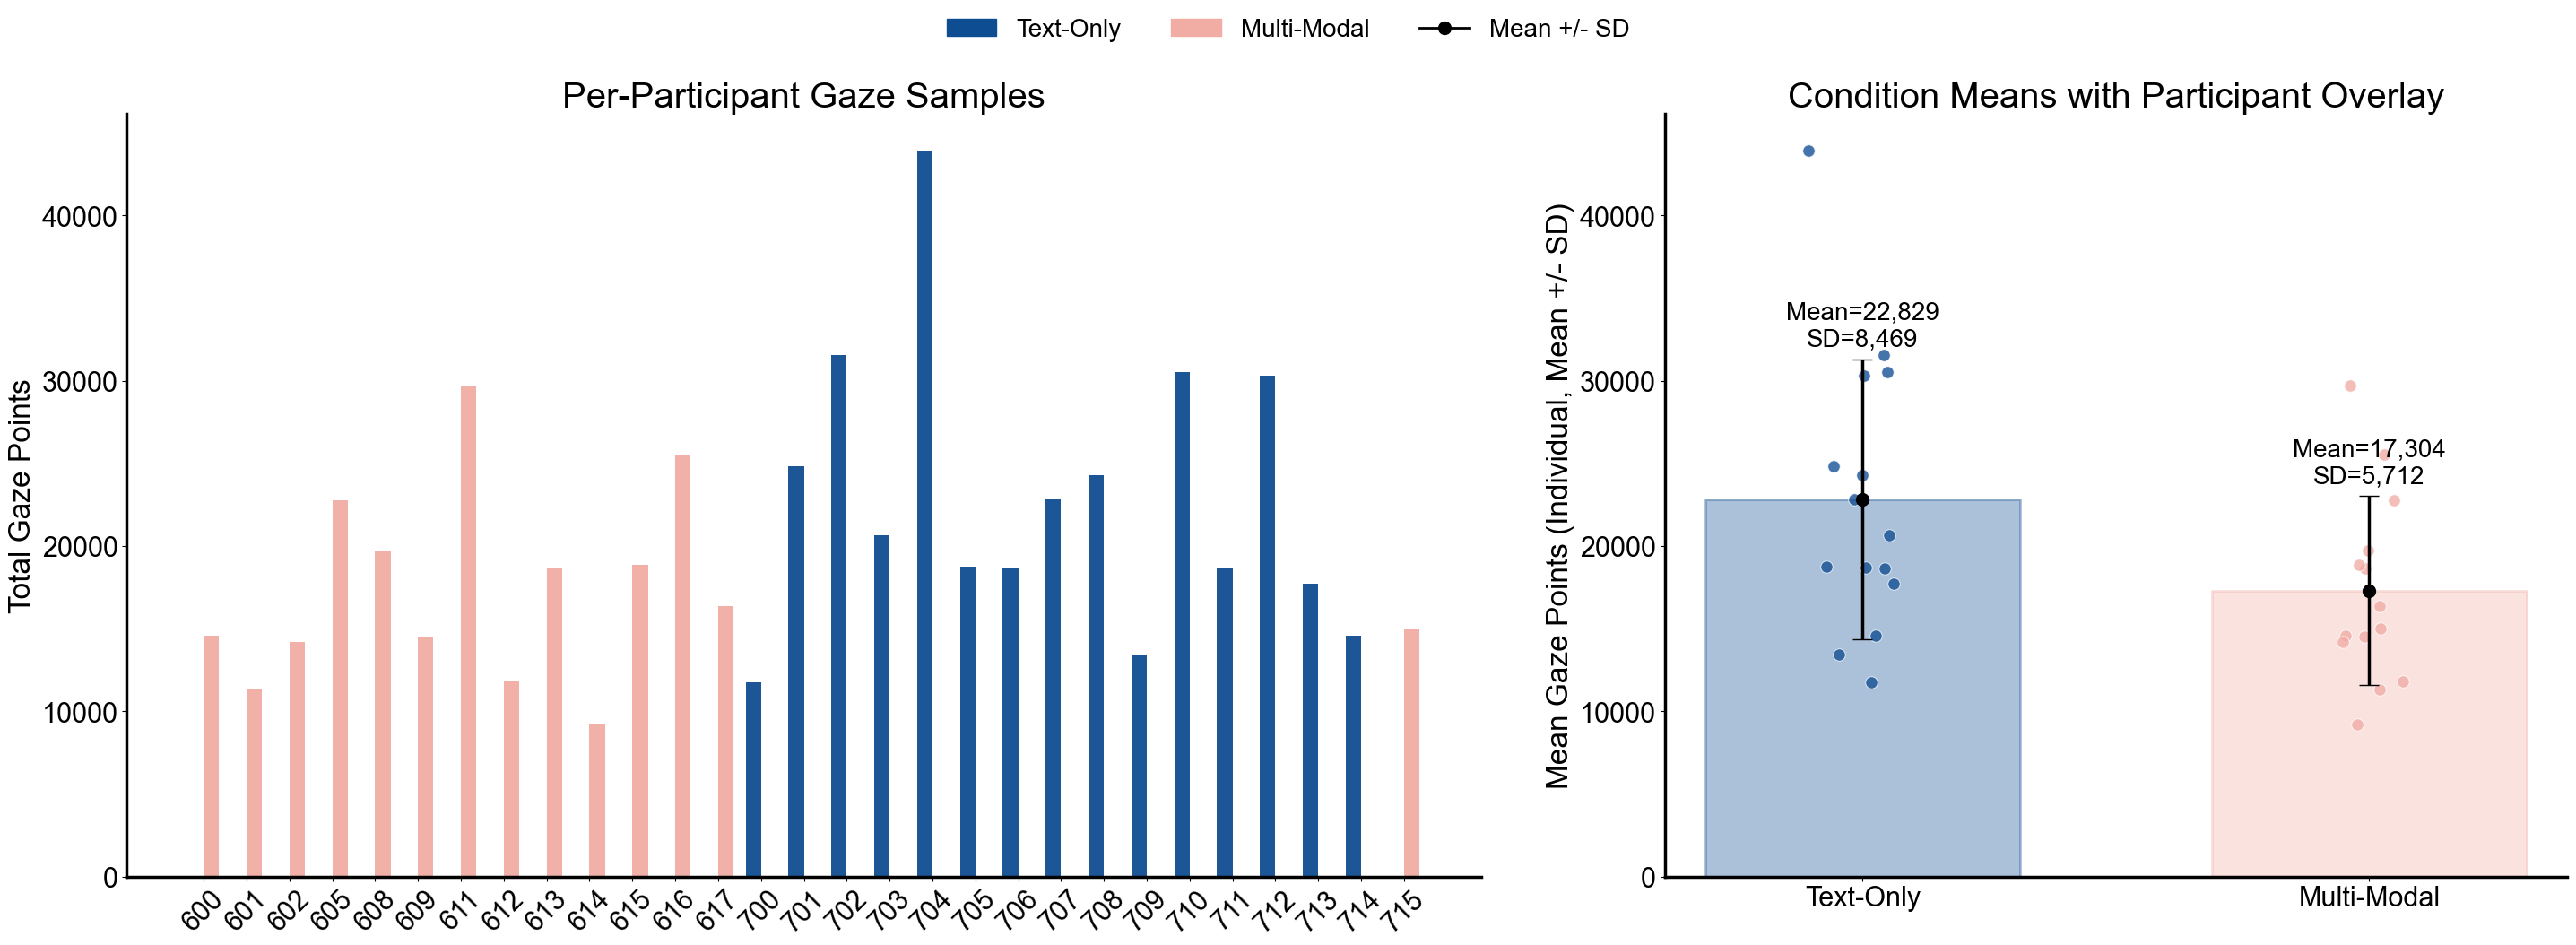


Revised Figure 4 saved to:
- C:\Users\nahmed25\PhD\ISMAR26_Engagement\figures\engagement_gaze_density.png
- C:\Users\nahmed25\PhD\ISMAR26_Engagement\figures\engagement_gaze_density.pdf


In [2]:
import os
import glob
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import gridspec
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

# ===============================
# Figure 4 (Revised): Data Density
# - Right panel removed (redundant)
# - Middle panel overlays individual participant points on mean +/- SD
# - Color mapping and legend made consistent with text
# ===============================

BASE_DIR = Path(r"C:\Users\nahmed25\PhD\ISMAR26_Engagement")
TEXT_GAZE_PATH = BASE_DIR / "TextualAttack" / "gaze"
MULTI_GAZE_PATH = BASE_DIR / "MultiModalAttack" / "gaze"

CONDITIONS = ["Text-Only", "Multi-Modal"]
COLORS = {
    "Text-Only": "#0F4D92",   # blue
    "Multi-Modal": "#F1ACA4", # salmon
}


def extract_participant_id(filename: str) -> str:
    return Path(filename).stem.split("_")[0]


def get_file_stats(path: Path, condition_label: str) -> pd.DataFrame:
    rows = []
    files = sorted(glob.glob(str(path / "*.csv")))
    print(f"Found {len(files)} files in {condition_label}: {path}")

    for f in files:
        try:
            df = pd.read_csv(f)
            pid = extract_participant_id(os.path.basename(f))
            rows.append(
                {
                    "Participant ID": pid,
                    "Data Points": len(df),
                    "Condition": condition_label,
                    "Duration (s)": len(df) / 60.0,
                }
            )
        except Exception as e:
            print(f"Error reading {f}: {e}")

    return pd.DataFrame(rows)


# Load data
text_df = get_file_stats(TEXT_GAZE_PATH, "Text-Only")
multi_df = get_file_stats(MULTI_GAZE_PATH, "Multi-Modal")
full_df = pd.concat([text_df, multi_df], ignore_index=True)

if full_df.empty:
    raise ValueError("No gaze CSV files were loaded. Check directory paths.")

full_df["Participant ID"] = pd.to_numeric(full_df["Participant ID"], errors="coerce")
full_df = full_df.dropna(subset=["Participant ID"]).copy()
full_df["Participant ID"] = full_df["Participant ID"].astype(int)
full_df = full_df.sort_values(by=["Participant ID", "Condition"]).reset_index(drop=True)

stats_summary = (
    full_df.groupby("Condition")["Data Points"]
    .agg(["mean", "std", "count", "sum"])
    .reindex(CONDITIONS)
)

print("\n--- REVISED FIGURE 4 STATISTICS ---")
print(stats_summary)
print("\nTotal Data Points:", int(full_df["Data Points"].sum()))

# Style
plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["font.sans-serif"] = ["Arial", "DejaVu Sans"]
plt.rcParams["font.size"] = 24
plt.rcParams["axes.spines.right"] = False
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.linewidth"] = 2.5

fig = plt.figure(figsize=(30, 11))
gs = gridspec.GridSpec(1, 2, width_ratios=[1.5, 1.0])

# -----------------------------
# Panel 1: Per-participant totals
# -----------------------------
ax1 = fig.add_subplot(gs[0])
participants = sorted(full_df["Participant ID"].unique())
width = 0.36
x = np.arange(len(participants))

for idx, cond in enumerate(CONDITIONS):
    vals = []
    for pid in participants:
        row = full_df[(full_df["Participant ID"] == pid) & (full_df["Condition"] == cond)]
        vals.append(row["Data Points"].iloc[0] if not row.empty else 0)

    ax1.bar(
        x + idx * width,
        vals,
        width=width,
        color=COLORS[cond],
        alpha=0.95,
        label=cond,
    )

ax1.set_title("Per-Participant Gaze Samples")
ax1.set_ylabel("Total Gaze Points")
ax1.set_xticks(x + width / 2)
ax1.set_xticklabels(participants, rotation=45)
ax1.tick_params(axis="both", labelsize=22)

# -----------------------------
# Panel 2: Mean +/- SD with participant-level overlay
# -----------------------------
ax2 = fig.add_subplot(gs[1])
rng = np.random.default_rng(42)

means = stats_summary["mean"].values
stds = stats_summary["std"].fillna(0).values
x2 = np.arange(len(CONDITIONS))

# Mean bars
for i, cond in enumerate(CONDITIONS):
    ax2.bar(
        i,
        means[i],
        color=COLORS[cond],
        alpha=0.35,
        width=0.62,
        edgecolor=COLORS[cond],
        linewidth=2,
    )

# Individual participant points + mean±SD marker
for i, cond in enumerate(CONDITIONS):
    y = full_df.loc[full_df["Condition"] == cond, "Data Points"].values
    jitter = rng.normal(0, 0.055, size=len(y))
    ax2.scatter(
        np.full_like(y, i, dtype=float) + jitter,
        y,
        s=95,
        alpha=0.78,
        color=COLORS[cond],
        edgecolor="white",
        linewidth=0.7,
        zorder=3,
    )

    ax2.errorbar(
        i,
        means[i],
        yerr=stds[i],
        fmt="o",
        color="black",
        ecolor="black",
        elinewidth=2.5,
        capsize=8,
        markersize=10,
        zorder=4,
    )

    ax2.text(
        i,
        means[i] + stds[i] + max(400, 0.02 * np.nanmax(means)),
        f"Mean={means[i]:,.0f}\nSD={stds[i]:,.0f}",
        ha="center",
        va="bottom",
        fontsize=20,
    )

ax2.set_title("Condition Means with Participant Overlay")
ax2.set_ylabel("Mean Gaze Points (Individual, Mean +/- SD)")
ax2.set_xticks(x2)
ax2.set_xticklabels(CONDITIONS)
ax2.tick_params(axis="both", labelsize=22)

# Single consistent legend
legend_handles = [
    Patch(facecolor=COLORS["Text-Only"], edgecolor=COLORS["Text-Only"], label="Text-Only"),
    Patch(facecolor=COLORS["Multi-Modal"], edgecolor=COLORS["Multi-Modal"], label="Multi-Modal"),
    Line2D([0], [0], marker="o", color="black", label="Mean +/- SD", markersize=10, linewidth=2),
]
fig.legend(
    handles=legend_handles,
    loc="upper center",
    ncol=3,
    frameon=False,
    fontsize=20,
    bbox_to_anchor=(0.5, 1.02),
)

# fig.suptitle("Figure 4 (Revised): Gaze Data Density Across Conditions", fontsize=30, y=1.07)
fig.tight_layout(pad=2.2)

# Save (same filenames to update manuscript figure)
os.makedirs(BASE_DIR / "figures", exist_ok=True)
png_path = BASE_DIR / "figures" / "engagement_gaze_density.png"
pdf_path = BASE_DIR / "figures" / "engagement_gaze_density.pdf"
fig.savefig(png_path, dpi=300, bbox_inches="tight")
fig.savefig(pdf_path, format="pdf", bbox_inches="tight")
plt.show()
plt.close(fig)

print(f"\nRevised Figure 4 saved to:\n- {png_path}\n- {pdf_path}")